# Topic 4 — Physics-Constrained MSE Inversion for Rock Strength and Sanding-Risk Profiling
### Complete research code, A–Z

This notebook holds the code behind every number and figure in the final paper. The well is Utah FORGE 58-32 (MU-ESW1), a geothermal test well near Milford, Utah. Its drilling record is the public Pason log (Podgorney, McLennan and Moore, 2018, https://doi.org/10.15121/1495411); the bit record, daily reports and end-of-well report are in Nash and Moore (2018, https://doi.org/10.15121/1452735) and the core tests in McLennan (2018, https://doi.org/10.15121/1557418), all under CC BY 4.0. Each module is written to the working folder with `%%writefile` and then run, so the code you read is the code that runs.

**Run modes.** The full study takes several hours on two cores: Routes 1–2 with profile likelihoods on 80 synthetic profiles (each twice, with and without a calibrated layer), the networks on 16 profiles × 10 starts × 2 variants plus the λ tuning, MCMC on 4 profiles, 36 robustness inversions and the field inversions. With `FULL = False` (the default) the notebook

* rebuilds the cleaned record, the section statistics, the noise library and all synthetic profiles from scratch and checks them against the stored set;
* checks the forward model against hand calculation and the friction line;
* re-runs Routes 1 and 2 completely for `CHECK_IDS` and compares them with the stored batch;
* runs a short MCMC chain, two network starts and the robustness truth check as live demonstrations;
* re-runs the whole field application on the two PDC runs (about a minute) and compares it with the stored results;
* computes every quoted number and draws every figure from the stored batch results (`REF`).

With `FULL = True` every batch is re-run here and nothing is read from `REF`.

## A. Setup

In [1]:
%matplotlib inline
import os, sys, json, glob, shutil, pickle, time, subprocess
import numpy as np, pandas as pd
from IPython.display import Image, display
DATA = os.environ.get('T3_DATA', os.path.abspath('field_data.csv') if os.path.exists('field_data.csv')
                      else '/mnt/user-data/outputs/field_data.csv')    # raw well record (7,311 rows); keep it next to this notebook
REF  = os.path.abspath('stored_results') + '/' if os.path.isdir('stored_results') else '/mnt/user-data/outputs/topic4_checkpoint/'                            # stored batch results
W    = os.path.abspath('./topic4_work') + '/'                                  # working folder
FULL = False                                                                   # True: re-run every batch here
CHECK_IDS = [2, 83]                                                            # profiles re-inverted live when FULL is False
for sub in ['figs', 'analysis', 'paper', 't4_runs', 't4_pcnn', 't4_mcmc', 't4_robust', 't4_field']: os.makedirs(W + sub, exist_ok=True)
os.chdir(W); sys.path.insert(0, W)
os.environ['T4_DIR'] = W; os.environ['T3_DATA'] = DATA; os.environ['T4_EXPORT'] = W
print('working folder:', W, '| stored results available:', os.path.isdir(REF + 't4_runs'))

working folder: /tmp/claude-0/nb4/topic4_work/ | stored results available: True


## B. Data cleaning and the proposal-stage section statistics (paper §3)

`t4data.py` is the cleaning used in Topics 1–3. `prop4_data.py` is the proposal-stage script: it flags sliding and the torque-sensor window, computes statistics on the hole sections assumed at that stage (26, 17½, 12¼ and 8½ in, read from the hydraulic steps) and draws the proposal's data figures. The well's bit record, found later, replaced those assumptions: the paper's §3 statistics use the actual hole sections (17½ in to 342 ft, 12¼ in to 2,180 ft, 8¾ in to TD), bit runs and lithology, held in `t4_core.py`, and are computed by `t4_figs_a.py` in Section K.

In [2]:
%%writefile t4data.py
import os, numpy as np, pandas as pd
raw = pd.read_csv(os.environ.get('T3_DATA', 'field_data.csv'))
raw = raw.reset_index(drop=False).rename(columns={'index':'row_id'})
df = raw.drop(columns=['Unnamed: 17','Unnamed: 18','Unnamed: 19','Unnamed: 20','Unnamed: 21','Unnamed: 22'])
df = df.rename(columns={'ROP(1 ft)':'ROP_1ft','WOB (k-lbs)':'WOB','Temp Out( degF)':'TempOut','Temp In(degF)':'TempIn',
    'Pit Total (bbls)':'PitTotal','Pump Press (psi)':'PumpPress','ROP(1 min)':'ROP_1min','Hookload (k-lbs)':'Hookload',
    'Surface Torque (psi)':'Torque','Rotary Speed (rpm)':'RPM','Flow In (gpm)':'FlowIn','Flow Out %':'FlowOutPct',
    'WH Pressure (psi)':'WHPressure','H2S Floor':'H2S_Floor','H2S Cellar':'H2S_Cellar','H2S Pits':'H2S_Pits'})
df['WHPressure_valid'] = df['WHPressure'] > -500
df.loc[~df['WHPressure_valid'], 'WHPressure'] = np.nan
df['ROP_1ft_winsorized'] = df['ROP_1ft'].clip(upper=df['ROP_1ft'].quantile(0.995))
df['FlowIn_winsorized'] = df['FlowIn'].clip(upper=df['FlowIn'].quantile(0.999))
df['is_circulating'] = df['FlowIn'] > 50
df['depth_block'] = pd.cut(df['Depth'], bins=10, labels=range(1,11)).astype(int)
circ = df[df['is_circulating']].copy().sort_values('Depth').reset_index(drop=True)
circ['pit_change'] = circ['PitTotal'].diff().fillna(0.0)
circ['flowout_dev'] = circ['FlowOutPct'] - 100.0
rop_safe = circ['ROP_1min'].clip(lower=5.0)
circ['dt_hr'] = (circ['Depth'].diff().clip(lower=0).fillna(0.0)) / rop_safe
circ['t_cum_hr'] = circ['dt_hr'].cumsum()

Writing t4data.py


In [3]:
%%writefile prop4_data.py
# Topic 4 proposal: characterise the drilling-mechanics channels and draw the data figures (p1-p4).
import os, json, numpy as np, pandas as pd
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
import sys; sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4data import df, circ
CK = os.environ.get('T4_DIR', os.environ.get('T4_DIR', './topic4_work/')); OUT = CK+'figs/'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.grid':True,'grid.color':'#e0e0e0','savefig.dpi':300,'savefig.bbox':'tight'})
NAVY, ORANGE, TEAL, GREY, RED, PURPLE, GOLD = '#1f3b57', '#d9822b', '#2a8c82', '#7a7a7a', '#b23b1f', '#6a4c93', '#c9a227'

# ---- assumed telescoping bit programme, anchored on the hydraulic steps in the drilling record ----
SECTIONS = [dict(name='26-in conductor hole', top=0, base=250, D=26.0, col='#f3f3f3'),
            dict(name='17½-in surface hole', top=250, base=2425, D=17.5, col='#eaf2f8'),
            dict(name='12¼-in intermediate hole', top=2425, base=4750, D=12.25, col='#f6efe4'),
            dict(name='8½-in production hole', top=4750, base=7600, D=8.5, col='#eef6ee')]
def section_of(z):
    for s in SECTIONS:
        if s['top'] <= z < s['base']: return s
    return SECTIONS[-1]

c = circ.copy()
c['D_in'] = [section_of(z)['D'] for z in c.Depth]
c['rop'] = c['ROP_1ft'].clip(lower=0.5, upper=500)
c['slide'] = (c.RPM < 5) & (c.WOB > 2) & (c.rop > 1)
TORQUE_LIVE = 600.0     # the torque channel reads about 5 psi (sensor not live) above ~592 ft
c['onbottom'] = (c.WOB > 2) & (c.rop > 1) & (c.Depth > 250)
c['rotating'] = c.onbottom & ~c.slide
c['tq_ok'] = c.Depth >= TORQUE_LIVE

# ---- statistics per section ----
stats = {}
for s in SECTIONS[1:]:
    g = c[(c.Depth >= s['top']) & (c.Depth < s['base'])]; r = g[g.rotating & g.tq_ok]; sl = g[g.slide]
    stats[s['name']] = dict(n=int(len(g)), n_onbottom=int(g.onbottom.sum()), slide_frac=float(g.slide.sum()/max(g.onbottom.sum(), 1)),
                            flow=float(g.FlowIn.median()), spp=float(g.PumpPress.median()), wob=float(r.WOB.median()), rpm=float(r.RPM.median()),
                            torque=float(r.Torque.median()), rop=float(r.rop.median()), torque_slide=float(sl.Torque.median()) if len(sl) else None,
                            wob_slide=float(sl.WOB.median()) if len(sl) else None, rop_slide=float(sl.rop.median()) if len(sl) else None,
                            corr_T_W=float(np.corrcoef(r.Torque, r.WOB)[0, 1]))
# slide-rotate pairs in the 8½-in hole
s8 = c[c.Depth >= 4750].reset_index(drop=True); z = s8.slide.values; pairs = []; runs = []; i = 0
while i < len(z):
    if z[i]:
        j = i
        while j < len(z) and z[j]: j += 1
        d0, d1 = s8.Depth[i], s8.Depth[j-1]; runs.append((float(d0), float(d1)))
        sl = s8.iloc[i:j]; rot = s8[(((s8.Depth > d1) & (s8.Depth <= d1+15)) | ((s8.Depth < d0) & (s8.Depth >= d0-15))) & s8.rotating]
        if len(sl) >= 3 and len(rot) >= 5: pairs.append((sl.rop.median()/rot.rop.median(), sl.WOB.median()/rot.WOB.median(), sl.Torque.median(), rot.Torque.median()))
        i = j
    else: i += 1
pairs = np.array(pairs); starts = np.array([r[0] for r in runs])
spacing = np.diff(starts); spacing = spacing[spacing < 45]
stats['slide_runs_8.5'] = dict(n_runs=len(runs), n_pairs=len(pairs), rop_ratio=float(np.median(pairs[:, 0])), wob_ratio=float(np.median(pairs[:, 1])),
                               torque_slide=float(np.median(pairs[:, 2])), torque_rot=float(np.median(pairs[:, 3])), spacing_median=float(np.median(spacing)))

# ---- surface MSE under the assumptions (Teale, field units) ----
def mse(W_klbf, Ns, Ptq, rop, D, Q, K_T, K_N):
    A = np.pi*D**2/4; Nb = Ns + K_N*Q; T = K_T*Ptq
    return 1000*W_klbf/A + 120*np.pi*Nb*T/(A*rop)
r8 = c[c.rotating & c.tq_ok].copy()
K_T_nom, K_N_nom = 30.0, 0.15
r8['mse_nom'] = mse(r8.WOB, r8.RPM, r8.Torque, r8.rop, r8.D_in, r8.FlowIn, K_T_nom, np.where(r8.Depth >= 2425, K_N_nom, 0.0))
mot = (r8.Depth >= 2425).values
r8['mse_lo'] = mse(r8.WOB, r8.RPM, r8.Torque, r8.rop, r8.D_in, r8.FlowIn, 15.0, np.where(mot, 0.0, 0.0))
r8['mse_hi'] = mse(r8.WOB, r8.RPM, r8.Torque, r8.rop, r8.D_in, r8.FlowIn, 60.0, np.where(mot, 0.30, 0.0))
stats['mse'] = {s['name']: dict(nom=float(r8.mse_nom[(r8.Depth >= s['top']) & (r8.Depth < s['base'])].median()),
                               lo=float(r8.mse_lo[(r8.Depth >= s['top']) & (r8.Depth < s['base'])].median()),
                               hi=float(r8.mse_hi[(r8.Depth >= s['top']) & (r8.Depth < s['base'])].median())) for s in SECTIONS[1:]}
# implied Pessier-Fear bit friction coefficient mu_b = 36 T/(D W) for the nominal K_T (all surface torque taken as bit torque)
r8['mu_b_nom'] = 36*K_T_nom*r8.Torque/(r8.D_in*1000*r8.WOB)
stats['mu_b'] = {s['name']: float(r8.mu_b_nom[(r8.Depth >= s['top']) & (r8.Depth < s['base'])].median()) for s in SECTIONS[1:]}
json.dump(stats, open(CK+'prop_data_stats.json', 'w'), indent=1)
print(json.dumps(stats, indent=1))

# ================= P1: composite log =================
fig, axs = plt.subplots(1, 7, figsize=(16, 10), sharey=True, gridspec_kw=dict(width_ratios=[0.75, 1, 1, 1, 1.2, 1, 1]))
axS, axs = axs[0], axs[1:]
d = c.Depth
def shade(ax):
    for s in SECTIONS: ax.axhspan(s['top'], s['base'], color=s['col'], zorder=0)
    for s in SECTIONS[1:]: ax.axhline(s['top'], color=GREY, ls='--', lw=0.8)
def smooth(x, w=15): return pd.Series(x).rolling(w, center=True, min_periods=3).median().values
tracks = [('WOB', 'WOB (klbf)', NAVY, None), ('RPM', 'Surface rotary speed (rpm)', TEAL, None), ('Torque', 'Surface torque (psi reading)', ORANGE, None),
          ('rop', 'ROP (ft/hr, log)', PURPLE, 'log'), ('PumpPress', 'Standpipe pressure (psi)', RED, None), ('FlowIn', 'Flow in (gpm)', GREY, None)]
for ax, (col, lab, colr, sc) in zip(axs, tracks):
    shade(ax); ax.plot(c[col], d, color=colr, lw=0.3, alpha=0.35); ax.plot(smooth(c[col].values), d, color=colr, lw=1.2)
    ax.set_xlabel(lab, fontsize=9.5); ax.xaxis.set_label_position('top'); ax.xaxis.tick_top()
    if sc: ax.set_xscale('log')
sl = c[c.slide]; axs[1].plot(np.zeros(len(sl))+2, sl.Depth, '_', color=RED, ms=7, mew=1.5, label='sliding'); axs[1].legend(fontsize=8, loc='lower right')
axS.invert_yaxis()
CASING = {250: '20-in conductor', 2425: '13⅜-in casing', 4750: '9⅝-in casing'}
shade(axS); axS.set_xlim(0, 1); axS.set_xticks([]); axS.grid(False); axS.set_xlabel('Assumed hole section', fontsize=9.5); axS.xaxis.set_label_position('top')
for s in SECTIONS: axS.text(0.5, (s['top']+s['base'])/2, s['name'].split('-in')[0] + ' in' + ('' if s['D'] > 20 else '\n' + s['name'].split(' ')[1] + '\nhole'), fontsize=8.5, va='center', ha='center', color='#333333')
for zc, lab in CASING.items(): axS.text(0.5, zc+40, lab, fontsize=7.5, va='top', ha='center', color=GREY, style='italic')
axS.set_ylabel('Measured depth (ft)'); axs[2].axhspan(0, TORQUE_LIVE, xmin=0, xmax=1, color='white', alpha=0.6, zorder=3); axs[2].text(150, 420, 'sensor not live', fontsize=8, ha='center', color=GREY, zorder=4)
axs[-1].set_xlim(0, 1500); axs[2].set_xlim(0, 300); axs[0].set_xlim(0, 50); axs[1].set_xlim(0, 200)
plt.subplots_adjust(wspace=0.12, left=0.05, right=0.99, top=0.93, bottom=0.03); plt.savefig(OUT+'p1_composite_log.png'); plt.close()

# ================= P2: sliding intervals reveal a downhole motor =================
fig = plt.figure(figsize=(14, 6.2)); gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 1.6])
z0, z1 = 4760, 5080; w = c[(c.Depth >= z0) & (c.Depth <= z1)]
axz = [fig.add_subplot(gs[0, i]) for i in range(4)]
for ax, (col, lab, colr) in zip(axz, [('RPM', 'Surface rpm', TEAL), ('WOB', 'WOB (klbf)', NAVY), ('Torque', 'Surface torque (psi)', ORANGE), ('rop', 'ROP (ft/hr)', PURPLE)]):
    for a0, a1 in runs:
        if z0 <= a0 <= z1: ax.axhspan(a0-0.5, a1+0.5, color='#f7d9d4', zorder=0)
    ax.plot(w[col], w.Depth, color=colr, lw=1.2); ax.set_xlabel(lab, fontsize=9.5); ax.xaxis.set_label_position('top'); ax.xaxis.tick_top(); ax.set_ylim(z1, z0)
    if ax is not axz[0]: ax.set_yticklabels([])
axz[0].set_ylabel('Measured depth (ft)')
ax = fig.add_subplot(gs[0, 4])
ax.scatter(pairs[:, 1], pairs[:, 0], s=40, color=RED, edgecolor='k', lw=0.4, zorder=3)
ax.axhline(1, color=GREY, lw=0.8); ax.axvline(1, color=GREY, lw=0.8)
ax.set_xlabel('WOB sliding / WOB rotating (adjacent intervals)'); ax.set_ylabel('ROP sliding / ROP rotating')
ax.text(0.03, 0.04, f'{len(pairs)} slide intervals, 8½-in hole\nmedian ROP ratio {np.median(pairs[:,0]):.2f} at {np.median(pairs[:,1]):.2f}× the WOB\nsurface torque {np.median(pairs[:,2]):.0f} psi sliding, {np.median(pairs[:,3]):.0f} psi rotating',
        transform=ax.transAxes, fontsize=8.5, va='bottom')
ax.set_title('(b) Sliding drills without surface rotation', fontsize=10.5); axz[0].set_title('(a) 4,760–5,080 ft (shaded: sliding)', fontsize=10.5, loc='left')
plt.tight_layout(); plt.savefig(OUT+'p2_sliding_motor.png'); plt.close()

# ================= P3: torque against WOB =================
fig, axs = plt.subplots(1, 3, figsize=(15, 4.9), sharey=True)
for ax, s in zip(axs, SECTIONS[1:]):
    g = r8[(r8.Depth >= s['top']) & (r8.Depth < s['base'])]
    scp = ax.scatter(g.WOB, g.Torque, c=g.Depth, cmap='viridis', s=4, alpha=0.6)
    ww = np.linspace(1, 48, 50)
    for mu, ls in [(0.3, ':'), (0.6, '--'), (1.0, '-.')]:
        for KT, colr in [(30.0, NAVY)]:
            ax.plot(ww, mu*s['D']*1000*ww/(36*KT), ls=ls, color=colr, lw=1.2, label=f'μ_b = {mu} (K_T = {KT:.0f} ft·lbf/psi)')
    ax.set_title(s['name'], fontsize=10.5); ax.set_xlabel('WOB (klbf)'); ax.set_xlim(0, 50); ax.set_ylim(0, 300)
    ax.text(0.03, 0.95, f'r(torque, WOB) = {np.corrcoef(g.Torque, g.WOB)[0,1]:.2f}', transform=ax.transAxes, fontsize=9, va='top')
axs[0].set_ylabel('Surface torque reading (psi)'); axs[2].legend(fontsize=7.5, loc='lower right')
cb = fig.colorbar(scp, ax=axs, pad=0.01); cb.set_label('Depth (ft)')
plt.savefig(OUT+'p3_torque_wob.png'); plt.close()

# ================= P4: surface MSE and what it implies for strength =================
fig, axs = plt.subplots(1, 2, figsize=(12.5, 9), sharey=True, gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axs[0]
for s in SECTIONS: ax.axhspan(s['top'], s['base'], color=s['col'], zorder=0)
r8s = r8.sort_values('Depth')
lo = pd.Series(r8s.mse_lo.values).rolling(25, center=True, min_periods=5).median(); hi = pd.Series(r8s.mse_hi.values).rolling(25, center=True, min_periods=5).median()
nom = pd.Series(r8s.mse_nom.values).rolling(25, center=True, min_periods=5).median()
ax.fill_betweenx(r8s.Depth, lo, hi, color=ORANGE, alpha=0.25, label='range over the assumptions\n(K_T 15–60 ft·lbf/psi; motor 0–0.30 rev/gal)')
ax.plot(nom, r8s.Depth, color=NAVY, lw=1.4, label='nominal (K_T 30 ft·lbf/psi; motor 0.15 rev/gal)')
ax.plot(0.35*nom, r8s.Depth, color=RED, lw=1.0, ls='--', label='0.35 × nominal MSE (efficiency-scaled)')
ax.set_xscale('log'); ax.set_xlim(1e3, 2e6); ax.invert_yaxis(); ax.set_xlabel('Surface MSE (psi, 25-ft running median)'); ax.set_ylabel('Measured depth (ft)')
ax.legend(fontsize=8, loc='lower left'); ax.set_title('(a) MSE from surface data', fontsize=10.5)
ax = axs[1]
ratio = (hi/lo).values; ax.plot(ratio, r8s.Depth, color=PURPLE, lw=1.2)
ax.set_xscale('log'); ax.set_xlim(1.5, 60); ax.set_xticks([2, 5, 10, 20, 50]); ax.set_xticklabels(['2', '5', '10', '20', '50']); ax.minorticks_off()
ax.set_xlabel('Ratio of highest to lowest MSE estimate'); ax.set_title('(b) Spread caused by the unknowns alone', fontsize=10.5)
for s in SECTIONS[1:]: ax.axhline(s['top'], color=GREY, ls='--', lw=0.8)
plt.tight_layout(); plt.savefig(OUT+'p4_surface_mse.png'); plt.close()
stats['mse_spread_median'] = {s['name']: float(np.nanmedian(ratio[(r8s.Depth.values >= s['top']) & (r8s.Depth.values < s['base'])])) for s in SECTIONS[1:]}
json.dump(stats, open(CK+'prop_data_stats.json', 'w'), indent=1); print('spread', stats['mse_spread_median'])

Writing prop4_data.py


In [4]:
%run prop4_data.py

{
 "17\u00bd-in surface hole": {
  "n": 2117,
  "n_onbottom": 2056,
  "slide_frac": 0.026750972762645913,
  "flow": 853.94,
  "spp": 562.46,
  "wob": 17.55,
  "rpm": 83.94,
  "torque": 140.88,
  "rop": 55.41,
  "torque_slide": 11.75,
  "wob_slide": 11.8,
  "rop_slide": 124.84,
  "corr_T_W": 0.26211196433307016
 },
 "12\u00bc-in intermediate hole": {
  "n": 2205,
  "n_onbottom": 2205,
  "slide_frac": 0.015419501133786848,
  "flow": 719.33,
  "spp": 1729.19,
  "wob": 23.16,
  "rpm": 51.33,
  "torque": 147.94,
  "rop": 20.54,
  "torque_slide": 45.245,
  "wob_slide": 21.7,
  "rop_slide": 9.48,
  "corr_T_W": -0.027551407688966134
 },
 "8\u00bd-in production hole": {
  "n": 2764,
  "n_onbottom": 2758,
  "slide_frac": 0.0725163161711385,
  "flow": 614.66,
  "spp": 1443.17,
  "wob": 30.88,
  "rpm": 38.54,
  "torque": 141.84,
  "rop": 11.184999999999999,
  "torque_slide": 34.915000000000006,
  "wob_slide": 35.68,
  "rop_slide": 8.645,
  "corr_T_W": 0.031015674191609697
 },
 "slide_runs_8.5": {


spread {'17½-in surface hole': 3.9563869478416738, '12¼-in intermediate hole': 20.378529830764037, '8½-in production hole': 23.212964033078368}


## C. Core model: data preparation, drag-bit forward model, priors, Routes 1–2, sanding (paper §4, §5.1–5.4)

`t4_core.py` holds equations (2)–(27): the section loader with the noise library, the forward model with the founder limiter and the smooth ramp, the priors and bounds, the whitened residual vector with its sparsity pattern, the MAP, the noise recalibration, the null-direction move of equation (14), the two-start profile likelihood, the Laplace covariance, Route 1 and the sanding criterion of equation (22).

In [5]:
%%writefile t4_core.py
# Topic 4 core: data preparation, drag-bit forward model, priors, synthetic profiles, Route 1 and Route 2 inversion.
# Units: W in lbf, N in rpm, Q in gpm, R in ft/hr, torque reading P_T in psi, T_b in lbf*in, T_d in 1,000 ft*lbf,
# eps (intrinsic specific energy) and UCS in psi, a (bit radius) in in.
import os, json, numpy as np, pandas as pd
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
CK = os.environ.get('T4_DIR', os.environ.get('T4_DIR', './topic4_work/'))

# Synthetic-study intervals: two depth intervals of the record whose operating sequence (WOB, speed, flow, sliding)
# drives the synthetic profiles, with a nominal bit size that is part of the synthetic truth ('12¼-in set', '8½-in set').
SECTIONS = {'12.25': dict(name='12¼-in set, 2,425–4,750 ft', top=2425.0, base=4750.0, D=12.25, motor=True),
            '8.5': dict(name='8½-in set, 4,750 ft–TD', top=4750.0, base=7600.0, D=8.5, motor=True),
            '17.5': dict(name='600–2,425 ft', top=600.0, base=2425.0, D=17.5, motor=False)}
# The well itself: Utah FORGE 58-32 (bit summary, daily reports and end-of-well report in Nash and Moore, 2018).
HOLES = [dict(name='17½-in hole', top=84.0, base=342.0, D=17.5), dict(name='12¼-in hole', top=342.0, base=2180.0, D=12.25),
         dict(name='8¾-in hole', top=2180.0, base=7600.0, D=8.75)]
# bit runs: (top, base, type, model, motor)
BIT_RUNS = [(84, 342, 'roller cone', 'HC X3A', False), (342, 2180, 'roller cone', 'Smith XR+ milled tooth', False),
            (2180, 3281, 'roller cone', 'Smith FHi28', True), (3281, 3961, 'roller cone', 'HC VGD-30DX', True),
            (3961, 4630, 'hybrid', 'HC Kymera KM624', True), (4630, 4875, 'PDC', 'Smith Z713', True),
            (4875, 5477, 'roller cone', 'HC VG-44CDX', True), (5477, 5708, 'roller cone', 'Smith F37HYOD', False),
            (5708, 6177, 'roller cone', 'HC HRMPS44DX', True), (6177, 6552, 'roller cone', 'Smith F67ODR', True),
            (6552, 6800, 'PDC', 'Smith Z713 (rerun)', True), (6800, 6812, 'core', 'diamond core bit', False),
            (6812, 7200, 'roller cone', 'HC MXBPS68DX', True), (7200, 7440, 'roller cone', 'HC HR-P68DXO', True),
            (7440, 7460, 'core', 'core bit', False), (7460, 7536, 'roller cone', 'HC HR-P68DXO', True)]
LITH = [(0, 3176, 'alluvium'), (3176, 3196, 'rhyolite'), (3196, 7600, 'granite')]
# unconfined compressive strength of core (McLennan, 2018): depth range (ft) and UCS (psi)
CORE_UCS = {'core 1': dict(top=6800.0, base=6810.0, ucs=[18300., 17100., 16800., 13200.], rock='granite to granodiorite'),
            'core 2': dict(top=7440.0, base=7452.0, ucs=[17800., 14500., 18200., 17200.], rock='diorite and granite to quartz monzonite')}
def bit_run(z):
    for r in BIT_RUNS:
        if r[0] <= z < r[1]: return r
    return BIT_RUNS[-1]
def hole_of(z):
    for h in HOLES:
        if h['top'] <= z < h['base']: return h
    return HOLES[-1]
LAYER_FT = 25.0
TORQUE_LIVE = 600.0

def load_section(key):
    """Rows of one hole section used for inversion: on-bottom, torque sensor live, sorted by depth."""
    from t4data import circ
    s = SECTIONS[key]; c = circ[(circ.Depth >= max(s['top'], TORQUE_LIVE)) & (circ.Depth < s['base'])].copy()
    c['R'] = c.ROP_1ft.clip(0.5, 500); c = c[(c.WOB > 2) & (c.R > 1)].sort_values('Depth').reset_index(drop=True)
    c['s'] = (c.RPM < 5).astype(float)
    d = dict(z=c.Depth.values.astype(float), W=1000*c.WOB.values.astype(float), Ns=np.where(c.s.values == 1, 0.0, c.RPM.values).astype(float),
             Q=c.FlowIn.values.astype(float), s=c.s.values, R=c.R.values.astype(float), PT=c.Torque.values.astype(float),
             a=s['D']/2, key=key, motor=s['motor'])
    d['rot'] = d['s'] == 0
    d['layer'] = ((d['z'] - d['z'][0])//LAYER_FT).astype(int); d['nL'] = int(d['layer'].max()+1)
    # noise library: residuals about a 15-row running median, kept in row order so blocks keep their autocorrelation
    lr = pd.Series(np.log(d['R'])); d['res_lnR'] = (lr - lr.rolling(15, center=True, min_periods=5).median()).fillna(0).values
    pt = pd.Series(np.where(d['rot'], d['PT'], np.nan)); pt = pt.interpolate().bfill().ffill()
    d['res_PT'] = (pt - pt.rolling(15, center=True, min_periods=5).median()).fillna(0).values
    r1 = d['res_lnR']; r2 = d['res_PT'][d['rot']]
    d['sig_lnR'] = float(r1.std()); d['rho_lnR'] = float(np.corrcoef(r1[:-1], r1[1:])[0, 1])
    d['sig_PT'] = float(r2.std()); d['rho_PT'] = float(np.corrcoef(r2[:-1], r2[1:])[0, 1])
    d['Wbar'] = float(np.median(d['W']))
    return d

# ---------------- forward model ----------------
NK = 5                                               # knots of the piecewise-linear wear-flat weight W*(z)
GLOB = ['ln_zeta', 'ln_mu', 'ln_KT', 'ln_KN', 'phi', 'Td', 'ln_df']
def nparam(d): return d['nL'] + len(GLOB) + NK
def unpack(th, d):
    nL = d['nL']; g = dict(zip(GLOB, th[nL:nL+len(GLOB)])); kn = th[nL+len(GLOB):]
    return th[:nL], g, kn
def wstar(kn, d):
    zk = np.linspace(d['z'][0], d['z'][-1], NK); return 1000*np.interp(d['z'], zk, kn)
def smooth_pos(x, h=300.0): return 0.5*(x + np.sqrt(x*x + h*h))
def forward(th, d, eps_rows=None, a=None, founder=True):
    """Predicted ln R (all rows) and torque reading P_T (all rows; only rotating rows are used)."""
    lne, g, kn = unpack(th, d); a = d['a'] if a is None else a
    eps = np.exp(lne)[d['layer']] if eps_rows is None else eps_rows
    zeta, mu, KT = np.exp(g['ln_zeta']), np.exp(g['ln_mu']), np.exp(g['ln_KT'])
    KN = np.exp(g['ln_KN']) if d['motor'] else 0.0
    Nb = d['Ns'] + KN*d['Q']; Wb = d['W']*(1 - g['phi']*d['s'])
    ex = smooth_pos(Wb - wstar(kn, d)); dDD = ex/(zeta*eps*a)
    if founder:
        df = np.exp(g['ln_df']); dl = dDD/(1 + (dDD/df)**4)**0.25
    else: dl = dDD
    lnR = np.log(5*np.maximum(Nb, 1e-3)*dl)
    Wc = zeta*eps*a*dl; Wf = Wb - Wc
    Tb = eps*a*a*dl/2 + mu*a*Wf/2
    PT = (Tb/12 + 1000*g['Td'])/KT
    return lnR, PT

# ---------------- priors ----------------
PRIOR = dict(ln_zeta=(np.log(0.7), 0.2), ln_mu=(np.log(0.7), 0.35), ln_KT=(np.log(40.0), 0.5), ln_KN=(np.log(0.15), 0.5),
             phi=(0.35, 0.15), Td=(2.0, 2.0), ln_df=(np.log(0.5), 2.0))
LNE_RW = 0.35                                        # random-walk SD of ln eps between adjacent 25-ft layers
LNE_MEAN = (np.log(8000.0), 2.0)                     # deliberately weak prior on the section-mean ln eps
def bounds(d):
    nL = d['nL']; Wm = d['W'].max()/1000
    lb = np.r_[np.full(nL, np.log(50.0)), np.log(0.2), np.log(0.1), np.log(5.0), np.log(0.01), 0.0, 0.0, np.log(1e-3), np.zeros(NK)]
    ub = np.r_[np.full(nL, np.log(5e6)), np.log(3.0), np.log(5.0), np.log(500.0), np.log(1.0), 0.8, 15.0, np.log(10.0), np.full(NK, 1.2*Wm)]
    return lb, ub

def whiten(e, rho): return np.r_[e[:1], (e[1:] - rho*e[:-1])/np.sqrt(1 - rho*rho)]
class Problem:
    def __init__(self, d, lnR_obs, PT_obs, priors=PRIOR, calib=None, founder=True, a=None):
        self.d, self.y1, self.y2 = d, lnR_obs, PT_obs; self.pri = priors; self.calib = calib; self.founder = founder; self.a = a
        self.s1, self.r1, self.s2, self.r2 = d['sig_lnR'], max(d['rho_lnR'], 0.0), d['sig_PT'], max(d['rho_PT'], 0.0)
        self.n = nparam(d); self.nL = d['nL']
    def resid(self, th):
        d = self.d; lnR, PT = forward(th, d, a=self.a, founder=self.founder)
        e1 = whiten(self.y1 - lnR, self.r1)/self.s1; e2 = whiten((self.y2 - PT)[d['rot']], self.r2)/self.s2
        lne, g, kn = unpack(th, d)
        pr = [(g[k] - m)/s for k, (m, s) in self.pri.items()]
        rw = np.diff(lne)/LNE_RW; mp = [(lne.mean() - LNE_MEAN[0])/LNE_MEAN[1]]
        out = [e1, e2, np.array(pr), rw, np.array(mp)]
        if self.calib is not None: j, v, sd = self.calib; out.append(np.array([(lne[j] - v)/sd]))
        return np.concatenate(out)
    def sparsity(self):
        d = self.d; nL = self.nL; n1 = len(d['z']); rotidx = np.where(d['rot'])[0]; n2 = len(rotidx)
        m = n1 + n2 + len(self.pri) + (nL-1) + 1 + (1 if self.calib is not None else 0)
        S = lil_matrix((m, self.n), dtype=int); L = d['layer']; gcols = list(range(nL, self.n))
        for i in range(n1):
            S[i, L[i]] = 1
            if i > 0: S[i, L[i-1]] = 1
            for c in gcols: S[i, c] = 1
        for k, i in enumerate(rotidx):
            S[n1+k, L[i]] = 1
            if k > 0: S[n1+k, L[rotidx[k-1]]] = 1
            for c in gcols: S[n1+k, c] = 1
        r0 = n1 + n2
        for q in range(len(self.pri)): S[r0+q, nL+q] = 1
        r0 += len(self.pri)
        for j in range(nL-1): S[r0+j, j] = 1; S[r0+j, j+1] = 1
        r0 += nL - 1
        for j in range(nL): S[r0, j] = 1
        if self.calib is not None: S[r0+1, self.calib[0]] = 1
        return S
XS_G = np.array([0.2, 0.3, 0.5, 0.5, 0.1, 1.0, 1.0])
def fit(prob, x0, fixed_mean=None, max_nfev=400, S=None):
    """MAP (or constrained MAP with the section-mean ln eps fixed). Returns theta, cost (= 0.5 chi2)."""
    d = prob.d; nL = prob.nL; lb, ub = bounds(d); xs = np.r_[np.full(nL, 0.3), XS_G, np.full(NK, 3.0)]
    if fixed_mean is None:
        f = prob.resid; z0 = np.clip(x0, lb+1e-6, ub-1e-6)
        r = least_squares(f, z0, bounds=(lb, ub), jac_sparsity=S, x_scale=xs, max_nfev=max_nfev, method='trf')
        return r.x, r.cost
    # reparameterise lne_j = v + dev_j with dev_nL = -sum(dev_1..nL-1)
    v = fixed_mean
    def full(u):
        dev = np.r_[u[:nL-1], -u[:nL-1].sum()]; return np.r_[v + dev, u[nL-1:]]
    def f(u):
        th = full(u); thc = np.clip(th, lb, ub); return np.r_[prob.resid(thc), 1e3*np.abs(th - thc).sum()]
    dev0 = x0[:nL] - x0[:nL].mean(); u0 = np.r_[dev0[:nL-1], x0[nL:]]
    lbu = np.r_[np.full(nL-1, -8.0), lb[nL:]]; ubu = np.r_[np.full(nL-1, 8.0), ub[nL:]]
    u0 = np.clip(u0, lbu+1e-6, ubu-1e-6)
    Su = None
    if S is not None:
        Sc = S.tocsc(); Su = lil_matrix((S.shape[0]+1, len(u0)), dtype=int)
        lay = Sc[:, :nL].sum(1).A.ravel() > 0
        for j in range(nL-1): Su[np.where(lay)[0], j] = 1
        G = Sc[:, nL:].toarray()
        for k in range(G.shape[1]): Su[np.where(G[:, k] > 0)[0], nL-1+k] = 1
        Su[S.shape[0], :] = 1
    r = least_squares(f, u0, bounds=(lbu, ubu), jac_sparsity=Su, x_scale=np.r_[np.full(nL-1, 0.3), XS_G, np.full(NK, 3.0)], max_nfev=max_nfev, method='trf')
    return full(r.x), r.cost

def initial_guess(d, lnR_obs, W_frac=0.5, df=1.0):
    th = np.zeros(nparam(d)); nL = d['nL']
    g = dict(ln_zeta=PRIOR['ln_zeta'][0], ln_mu=PRIOR['ln_mu'][0], ln_KT=PRIOR['ln_KT'][0], ln_KN=PRIOR['ln_KN'][0], phi=0.35, Td=2.0, ln_df=np.log(df))
    th[nL:nL+len(GLOB)] = [g[k] for k in GLOB]; th[nL+len(GLOB):] = W_frac*d['Wbar']/1000
    Nb = d['Ns'] + (0.15*d['Q'] if d['motor'] else 0); Wb = d['W']*(1 - 0.35*d['s']); ex = smooth_pos(Wb - W_frac*d['Wbar'])
    e_rows = 5*Nb*ex/(0.7*d['a']*np.exp(lnR_obs))
    lne = np.array([np.median(np.log(e_rows[d['layer'] == j])) if np.any(d['layer'] == j) else np.nan for j in range(nL)])
    lne = pd.Series(lne).interpolate().bfill().ffill().values; th[:nL] = lne
    return th

def map_estimate(prob, S=None):
    best = None
    for wf, df in [(0.5, 1.0), (0.85, 1.0), (0.3, 0.05)]:
        x0 = initial_guess(prob.d, prob.y1, wf, df); x, c = fit(prob, x0, S=S)
        if best is None or c < best[1]: best = (x, c)
    return best

def calibrate_noise(prob, th):
    lnR, PT = forward(th, prob.d, a=prob.a, founder=prob.founder); e1 = prob.y1 - lnR; e2 = (prob.y2 - PT)[prob.d['rot']]
    def ar(e, s0, r0): rho = float(np.clip(np.corrcoef(e[:-1], e[1:])[0, 1], 0, 0.95)); return max(float(e.std()), s0), max(rho, r0)
    prob.s1, prob.r1 = ar(e1, prob.d['sig_lnR'], max(prob.d['rho_lnR'], 0)); prob.s2, prob.r2 = ar(e2, prob.d['sig_PT'], max(prob.d['rho_PT'], 0))

def null_move(th, d, dv):
    """Move along the exact null direction: eps, mu_g, T_d, K_T scale by e^dv, zeta by e^-dv."""
    y = th.copy(); nL = d['nL']; i = {k: nL+q for q, k in enumerate(GLOB)}
    y[:nL] += dv; y[i['ln_zeta']] -= dv; y[i['ln_mu']] += dv; y[i['ln_KT']] += dv; y[i['Td']] *= np.exp(dv)
    lb, ub = bounds(d); return np.clip(y, lb+1e-6, ub-1e-6)

OFF = np.array([0.1, 0.25, 0.45, 0.7, 1.0, 1.5, 2.2, 3.0])
def profile_mean(prob, xmap, cmap, S=None):
    """Profile likelihood of the section-mean ln eps, two starts per step (previous step, and a null-direction move)."""
    d = prob.d; v0 = xmap[:prob.nL].mean(); pts = [(v0, cmap, xmap)]
    for sgn in (+1, -1):
        x = xmap.copy(); vprev = v0
        for off in OFF:
            v = v0 + sgn*off
            x1, c1 = fit(prob, x, fixed_mean=v, S=S); x2, c2 = fit(prob, null_move(x, d, v - vprev), fixed_mean=v, S=S)
            x, c = (x1, c1) if c1 <= c2 else (x2, c2); pts.append((v, c, x)); vprev = v
            if 2*(c - cmap) > 30: break
    pts.sort(key=lambda t: t[0]); v = np.array([p_[0] for p_ in pts]); cc = np.array([p_[1] for p_ in pts])
    cmin = min(cmap, cc.min()); dchi = 2*(cc - cmin); i0 = int(np.argmin(cc))
    lo, hi = -np.inf, np.inf
    for i in range(i0, len(v)-1):
        if dchi[i+1] >= 3.84: hi = v[i] + (3.84-dchi[i])/(dchi[i+1]-dchi[i]+1e-12)*(v[i+1]-v[i]); break
    for i in range(i0, 0, -1):
        if dchi[i-1] >= 3.84: lo = v[i] - (3.84-dchi[i])/(dchi[i-1]-dchi[i]+1e-12)*(v[i]-v[i-1]); break
    return dict(v=v.tolist(), d=dchi.tolist(), lo=float(lo), hi=float(hi), est=float(v[i0]), improved=bool(cc.min() < cmap - 1e-6), xbest=pts[i0][2].tolist())

def laplace(prob, th, S=None):
    """Gauss-Newton covariance at the optimum (dense finite-difference Jacobian)."""
    f0 = prob.resid(th); J = np.zeros((len(f0), len(th))); lb, ub = bounds(prob.d)
    for k in range(len(th)):
        h = 1e-4*max(1.0, abs(th[k])); t2 = th.copy(); t2[k] = min(th[k]+h, ub[k]); J[:, k] = (prob.resid(t2) - f0)/(t2[k]-th[k])
    H = J.T@J; return np.linalg.pinv(H)

# ---------------- Route 1: Teale MSE with nominal constants and a fixed efficiency ----------------
def route1(d, KT=None, KN=0.15, eff=0.35):
    KT = np.exp(PRIOR['ln_KT'][0]) if KT is None else KT
    A = np.pi*d['a']**2; Nb = d['Ns'] + (KN*d['Q'] if d['motor'] else 0.0); T = KT*d['PT']
    mse = d['W']/A + 120*np.pi*Nb*T/(A*d['R']); ok = d['rot']
    lay = np.array([np.median(mse[ok & (d['layer'] == j)]) if np.any(ok & (d['layer'] == j)) else np.nan for j in range(d['nL'])])
    lay = pd.Series(lay).interpolate().bfill().ffill().values
    return dict(mse_layer=lay, ucs_layer=eff*lay, mse_rows=mse)

# ---------------- sanding ----------------
GEO = dict(sh_grad=(0.70, 0.05), pr_grad=(0.45, 0.05), ln_b=(0.0, 0.3), ln_ceps=(0.0, 0.3))
def crit_drawdown(ucs, z, b=1.0, sh=0.70, pr=0.45): return pr*z - sh*z + b*ucs/2
def p_sand(ln_ucs_mean, ln_ucs_sd, z, dP, geo=True, n=4000, rng=None):
    """Probability that the critical drawdown is below dP, given a normal posterior of ln UCS (and geomechanical priors)."""
    rng = np.random.default_rng(0) if rng is None else rng
    lu = ln_ucs_mean[:, None] + ln_ucs_sd[:, None]*rng.standard_normal((len(ln_ucs_mean), n))
    if geo:
        b = np.exp(GEO['ln_b'][1]*rng.standard_normal(n)); ce = np.exp(GEO['ln_ceps'][1]*rng.standard_normal(n))
        sh = GEO['sh_grad'][0] + GEO['sh_grad'][1]*rng.standard_normal(n); pr = GEO['pr_grad'][0] + GEO['pr_grad'][1]*rng.standard_normal(n)
        dpc = pr[None, :]*z[:, None] - sh[None, :]*z[:, None] + b[None, :]*np.exp(lu)/ce[None, :]/2
    else:
        dpc = crit_drawdown(np.exp(lu), z[:, None])
    return (dpc < dP).mean(1)

Writing t4_core.py


In [6]:
from t4_core import *
for k in ['12.25', '8.5']:
    d = load_section(k)
    print(f"{SECTIONS[k]['name']}: {len(d['z'])} rows, {d['nL']} layers, sliding {100*d['s'].mean():.1f}%, "
          f"noise ln ROP {d['sig_lnR']:.3f} (rho {d['rho_lnR']:.2f}), torque {d['sig_PT']:.1f} psi (rho {d['rho_PT']:.2f})")
# exact null direction: move a parameter vector along equation (14) and compare predictions
d = load_section('8.5'); th = initial_guess(d, np.log(d['R'])); th[d['nL']+GLOB.index('ln_df')] = np.log(0.05)
for c in [-0.7, 0.7]:
    a1, b1 = forward(th, d); a2, b2 = forward(null_move(th, d, c), d)
    print(f'c = {c:+.1f}: max |d ln R| = {np.abs(a1-a2).max():.1e}, max |d P_T| = {np.abs(b1-b2).max():.1e} psi')

12¼-in set, 2,425–4,750 ft: 2205 rows, 93 layers, sliding 1.5%, noise ln ROP 0.212 (rho 0.35), torque 10.6 psi (rho 0.19)
8½-in set, 4,750 ft–TD: 2758 rows, 112 layers, sliding 7.3%, noise ln ROP 0.171 (rho 0.22), torque 10.3 psi (rho 0.37)
c = -0.7: max |d ln R| = 1.3e-15, max |d P_T| = 1.1e-13 psi
c = +0.7: max |d ln R| = 1.3e-15, max |d P_T| = 1.7e-13 psi


## D. Synthetic strength profiles on the real operating sequence (paper §5.3)

`t4_gen.py` writes layered strength fields, efficiency states (constant, drift, step; design and matched regimes), founder, constants drawn from the priors and circularly shifted real residuals onto the 12¼-in and 8½-in sequences. Profiles 0–39 and 80–119 were inverted.

In [7]:
%%writefile t4_gen.py
# Synthetic strength profiles written onto the real operating sequence of the 12¼-in and 8½-in holes.
import os, sys, pickle, json, numpy as np
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4_core import *
N_PER = int(os.environ.get('T4_NPER', 80))

def bed_field(z, rng, mean_ln, sig_c, trend):
    """Layered strength: beds 5-50 ft thick, lognormal contrasts, plus a linear trend over the section."""
    edges = [z[0]]
    while edges[-1] < z[-1]: edges.append(edges[-1] + rng.uniform(5, 50))
    lnb = mean_ln + sig_c*rng.standard_normal(len(edges))
    idx = np.searchsorted(edges, z, side='right') - 1
    t = (z - z[0])/(z[-1] - z[0]) - 0.5
    return lnb[idx] + trend*t, np.array(edges)

def draw_constants(rng):
    c = {}
    for k, (m, s) in PRIOR.items():
        if k in ('ln_df',): continue
        c[k] = m + s*rng.standard_normal()
    c['phi'] = float(np.clip(c['phi'], 0.05, 0.7)); c['Td'] = float(np.clip(c['Td'], 0.2, 6.0))
    return c

def make_profile(d, rng, pid):
    z = d['z']; nL = d['nL']
    mean_ucs = np.exp(rng.uniform(np.log(2000), np.log(25000))); sig_c = rng.uniform(0.2, 0.6); trend = rng.uniform(-0.4, 0.4)
    ln_eps_rows, edges = bed_field(z, rng, np.log(mean_ucs), sig_c, trend)
    regime = 'design' if (pid % 2 == 0) else 'matched'          # alternate: proposal efficiency range, or matched to the recorded ROP
    state = rng.choice(['constant', 'drift', 'step']); t = (z - z[0])/(z[-1] - z[0])
    if state == 'constant': shape = np.zeros(len(z))
    elif state == 'drift': shape = rng.uniform(-0.3, 0.3)*t
    else:
        zs = rng.uniform(0.2, 0.8); shape = np.where(t < zs, 0.0, rng.choice([-1, 1])*rng.uniform(0.15, 0.3))
    c = draw_constants(rng); founder = bool(rng.random() < 0.5); pf = rng.uniform(30, 70)
    def frac_of(f0, lo=0.05, hi=0.97): return np.clip(f0 + shape*(min(f0, 1 - f0)/0.5 if regime == 'matched' else 1.0), lo, hi)
    def fwd_truth(ln_df, Wst_rows):
        g = dict(c); zeta, mu, KT, KN = np.exp(g['ln_zeta']), np.exp(g['ln_mu']), np.exp(g['ln_KT']), np.exp(g['ln_KN']) if d['motor'] else 0.0
        eps = np.exp(ln_eps_rows); a = d['a']; Nb = d['Ns'] + KN*d['Q']; Wb = d['W']*(1 - g['phi']*d['s'])
        ex = smooth_pos(Wb - Wst_rows); dDD = ex/(zeta*eps*a); df = np.exp(ln_df); dl = dDD/(1 + (dDD/df)**4)**0.25
        lnR = np.log(5*np.maximum(Nb, 1e-3)*dl); Wc = zeta*eps*a*dl; Wf = Wb - Wc; Tb = eps*a*a*dl/2 + mu*a*Wf/2
        return lnR, (Tb/12 + 1000*g['Td'])/KT, dDD
    def run(f0):
        frac = frac_of(f0); _, _, dDD = fwd_truth(np.log(10.0), frac*d['Wbar'])
        ln_df = np.log(np.percentile(dDD, pf)) if founder else np.log(10.0)
        lnR, PT, _ = fwd_truth(ln_df, frac*d['Wbar']); return frac, ln_df, lnR, PT
    if regime == 'design':
        f0 = rng.uniform(0.2, 0.9)
    else:                                                       # bisection on f0 for a median ROP near the recorded one
        target = np.log(np.median(d['R'])) + rng.uniform(-0.7, 0.7); lo, hi = 0.02, 0.97
        for _ in range(40):
            mid = 0.5*(lo + hi); m = np.median(run(mid)[2])
            lo, hi = (mid, hi) if m > target else (lo, mid)
        f0 = 0.5*(lo + hi)
    frac, ln_df, lnR, PT = run(f0)
    sh = rng.integers(len(z)); n1 = np.roll(d['res_lnR'], sh); n2 = np.roll(d['res_PT'], sh)
    true_layer = np.array([ln_eps_rows[d['layer'] == j].mean() if np.any(d['layer'] == j) else np.nan for j in range(nL)])
    true_layer = pd.Series(true_layer).interpolate().bfill().ffill().values
    return dict(id=pid, key=d['key'], regime=regime, mean_ucs=float(mean_ucs), sig_c=float(sig_c), trend=float(trend), state=str(state), f0=float(f0),
                frac_rows=frac, founder=founder, ln_df=float(ln_df), consts=c, ln_eps_rows=ln_eps_rows, true_layer=true_layer,
                lnR_true=lnR, PT_true=PT, lnR_obs=lnR + n1, PT_obs=PT + n2, shift=int(sh))

if __name__ == '__main__':
    rng = np.random.default_rng(2027); out = []; meta = []
    for key in ['12.25', '8.5']:
        d = load_section(key)
        print(key, 'rows', len(d['z']), 'layers', d['nL'], 'noise lnR %.3f (rho %.2f), PT %.1f (rho %.2f)' % (d['sig_lnR'], d['rho_lnR'], d['sig_PT'], d['rho_PT']), flush=True)
        for i in range(N_PER):
            pr = make_profile(d, rng, len(out)); out.append(pr)
            meta.append(dict(id=pr['id'], key=key, regime=pr['regime'], mean_ucs=pr['mean_ucs'], sig_c=pr['sig_c'], trend=pr['trend'], state=pr['state'], f0=pr['f0'], founder=pr['founder'],
                             med_rop=float(np.exp(np.median(pr['lnR_true']))), med_PT=float(np.median(pr['PT_true'][d['rot']])),
                             **{k: float(v) for k, v in pr['consts'].items()}))
    pickle.dump(out, open(CK+'t4_profiles.pkl', 'wb')); pd.DataFrame(meta).to_csv(CK+'t4_profiles_meta.csv', index=False)
    m = pd.DataFrame(meta); print(m.groupby(['key', 'regime'])[['mean_ucs', 'med_rop', 'med_PT', 'f0']].median().round(2).to_string()); print(m.groupby('regime').med_rop.describe().round(1))

Writing t4_gen.py


In [8]:
t0 = time.time()
%run t4_gen.py
print(f'{time.time()-t0:.0f} s')
if os.path.exists(REF + 't4_profiles.pkl'):
    A_ = pickle.load(open(W + 't4_profiles.pkl', 'rb')); B_ = pickle.load(open(REF + 't4_profiles.pkl', 'rb'))
    same = len(A_) == len(B_) and all(np.allclose(a['lnR_obs'], b['lnR_obs']) and np.allclose(a['PT_obs'], b['PT_obs']) for a, b in zip(A_, B_))
    print('identical to the stored profile set:', same)

12.25 rows 2205 layers 93 noise lnR 0.212 (rho 0.35), PT 10.6 (rho 0.19)


8.5 rows 2758 layers 112 noise lnR 0.171 (rho 0.22), PT 10.3 (rho 0.37)


               mean_ucs  med_rop  med_PT    f0
key   regime                                  
12.25 design    6467.64   199.36  240.55  0.53
      matched   8714.50    27.30  189.35  0.94
8.5   design    5273.10   335.68  168.08  0.58
      matched   6581.59    11.52  198.74  0.95
         count   mean    std  min    25%    50%    75%     max
regime                                                        
design    80.0  427.0  383.7  6.9  116.3  269.6  766.4  1571.2
matched   80.0   21.9   16.8  5.6   11.1   16.2   30.2    97.3
1 s
identical to the stored profile set: True


## E. Routes 1 and 2 (paper §4.7, §5.4, §6.1–6.4)

`t4_run.py` runs Route 1 and the Route 2 inversion (MAP with noise recalibration, two-start profile likelihood of the section mean, Laplace contrast intervals), with and without one calibrated layer.

In [9]:
%%writefile t4_run.py
# Routes 1 and 2 on the synthetic profiles: Teale MSE with a fixed efficiency, and the Bayesian drag-bit inversion
# (MAP with noise recalibration, profile likelihood of the section-mean strength, Laplace intervals for contrasts),
# with and without one calibrated layer.
import os, sys, pickle, json, time, numpy as np
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4_core import *
OUT = CK+'t4_runs/'; os.makedirs(OUT, exist_ok=True)

def run_route2(d, y1, y2, calib=None, S=None, founder=True, a=None, priors=PRIOR):
    pr = Problem(d, y1, y2, calib=calib, founder=founder, a=a, priors=priors); S = pr.sparsity() if S is None else S
    xm, cm = map_estimate(pr, S); calibrate_noise(pr, xm); xm, cm = map_estimate(pr, S)
    prof = profile_mean(pr, xm, cm, S); n_retrace = 0
    while prof['improved'] and n_retrace < 3:
        c_new = pr.resid(np.array(prof['xbest'])) @ pr.resid(np.array(prof['xbest']))/2
        xm = np.array(prof['xbest']); gain = 2*(cm - c_new); cm = c_new
        if gain <= 1.0: break                                       # small gain: keep the profile, take the better optimum
        prof = profile_mean(pr, xm, cm, S); n_retrace += 1          # large gain: the profile was traced from a worse valley, retrace it
    prof['n_retrace'] = n_retrace
    C = laplace(pr, xm); nL = d['nL']
    Cl = C[:nL, :nL]; w = np.full(nL, 1/nL); M = np.eye(nL) - w[None, :]
    sd_con = np.sqrt(np.clip(np.diag(M@Cl@M.T), 0, None)); sd_lay = np.sqrt(np.clip(np.diag(Cl), 0, None)); sd_mean_lap = float(np.sqrt(w@Cl@w))
    lnR, PT = forward(xm, d, a=a, founder=founder)
    return dict(map=xm.tolist(), cost=float(cm), noise=[pr.s1, pr.r1, pr.s2, pr.r2], prof=prof, sd_con=sd_con.tolist(), sd_layer=sd_lay.tolist(),
                sd_mean_laplace=sd_mean_lap, sd_glob=np.sqrt(np.clip(np.diag(C)[nL:], 0, None)).tolist(),
                rms_lnR=float(np.std(y1 - lnR)), rms_PT=float(np.std((y2 - PT)[d['rot']])))

if __name__ == '__main__':
    P = pickle.load(open(CK+'t4_profiles.pkl', 'rb')); part, nparts = int(sys.argv[1]), int(sys.argv[2])
    ids = [int(x) for x in sys.argv[3].split(',')] if len(sys.argv) > 3 else [p_['id'] for p_ in P]
    secs = {k: load_section(k) for k in ['12.25', '8.5']}; Ss = {}
    for pr_ in P:
        if pr_['id'] not in ids or pr_['id'] % nparts != part: continue
        f = OUT+f"r{pr_['id']:03d}.json"
        if os.path.exists(f): continue
        t0 = time.time(); d = secs[pr_['key']]
        if pr_['key'] not in Ss:
            Ss[pr_['key']] = (Problem(d, pr_['lnR_obs'], pr_['PT_obs']).sparsity(), Problem(d, pr_['lnR_obs'], pr_['PT_obs'], calib=(d['nL']//2, 0.0, 0.15)).sparsity())
        S, Sc = Ss[pr_['key']]
        dd = dict(d); dd['R'] = np.exp(pr_['lnR_obs']); dd['PT'] = pr_['PT_obs']
        r1 = route1(dd)
        res = dict(id=pr_['id'], key=pr_['key'], route1_ln_ucs=np.log(r1['ucs_layer']).tolist(), true_layer=pr_['true_layer'].tolist())
        res['route2'] = run_route2(d, pr_['lnR_obs'], pr_['PT_obs'], S=S)
        j = d['nL']//2; rng = np.random.default_rng(pr_['id'])
        res['calib'] = dict(layer=j, value=float(pr_['true_layer'][j] + 0.15*rng.standard_normal()), sd=0.15)
        res['route2_cal'] = run_route2(d, pr_['lnR_obs'], pr_['PT_obs'], calib=(j, res['calib']['value'], 0.15), S=Sc)
        json.dump(res, open(f, 'w'))
        print(f"RES|{pr_['id']} {pr_['key']} {time.time()-t0:.0f}s  mean err R2 {np.mean(res['route2']['map'][:d['nL']]) - pr_['true_layer'].mean():+.2f}  R1 {np.mean(res['route1_ln_ucs']) - pr_['true_layer'].mean():+.2f}  interval [{res['route2']['prof']['lo']-pr_['true_layer'].mean():+.2f}, {res['route2']['prof']['hi']-pr_['true_layer'].mean():+.2f}]", flush=True)
    print('RES|DONE', flush=True)

Writing t4_run.py


In [10]:
USED = ','.join(str(i) for i in list(range(0, 40)) + list(range(80, 120)))
if FULL:
    !python t4_run.py 0 1 {USED}
else:
    for i in CHECK_IDS:
        f = W + f't4_runs/r{i:03d}.json'
        if os.path.exists(f): os.remove(f)
    t0 = time.time(); ids = ','.join(map(str, CHECK_IDS))
    !python t4_run.py 0 1 {ids}
    print(f'{time.time()-t0:.0f} s for {len(CHECK_IDS)} profiles')
    for i in CHECK_IDS:
        a = json.load(open(W + f't4_runs/r{i:03d}.json')); b = json.load(open(REF + f't4_runs/r{i:03d}.json')); nL = len(a['true_layer'])
        print(f"profile {i}: level here {np.mean(a['route2']['map'][:nL]):.4f} stored {np.mean(b['route2']['map'][:nL]):.4f}; "
              f"interval here [{a['route2']['prof']['lo']:.3f}, {a['route2']['prof']['hi']:.3f}] stored [{b['route2']['prof']['lo']:.3f}, {b['route2']['prof']['hi']:.3f}]; "
              f"max layer difference {np.max(np.abs(np.array(a['route2']['map'][:nL]) - np.array(b['route2']['map'][:nL]))):.1e}")
    for f in glob.glob(REF + 't4_runs/r*.json'): shutil.copy(f, W + 't4_runs/')
    # first pass of profile 117, before its profile was retraced from the better optimum (paper §6.4)
    if os.path.exists(REF + 'analysis/r117_first_pass.json'): shutil.copy(REF + 'analysis/r117_first_pass.json', W + 'analysis/')

RES|2 12.25 65s  mean err R2 +0.02  R1 +0.70  interval [-0.31, +0.33]


RES|83 8.5 212s  mean err R2 +0.46  R1 +4.49  interval [+0.07, +0.79]
RES|DONE


278 s for 2 profiles


profile 2: level here 9.0791 stored 9.0791; interval here [8.745, 9.389] stored [8.745, 9.389]; max layer difference 0.0e+00
profile 83: level here 9.5816 stored 9.5816; interval here [9.192, 9.913] stored [9.192, 9.913]; max layer difference 0.0e+00


## F. Posterior check by MCMC (paper §5.4, §6.4)

The same likelihood on 100-ft layers, sampled with emcee (differential-evolution and snooker moves). The paper uses 10,000 steps per profile; the live run below is a short chain.

In [11]:
%%writefile t4_mcmc.py
# Posterior check of Route 2 by MCMC on a reduced model (100-ft layers), for a few synthetic profiles.
# Compares the MCMC 95% interval of the section-mean ln eps with the profile-likelihood interval, and the MCMC
# standard deviations of layer contrasts with the Laplace (Gauss-Newton) values, on exactly the same posterior.
import os, sys, pickle, json, time, numpy as np, emcee
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import t4_core
from t4_core import *
t4_core.LNE_RW = 0.35*2.0                       # random-walk SD scaled to 100-ft layers (four 25-ft steps)
OUT = CK+'t4_mcmc/'; os.makedirs(OUT, exist_ok=True)

def reduce_layers(d, ft=100.0):
    d2 = dict(d); d2['layer'] = ((d['z'] - d['z'][0])//ft).astype(int); d2['nL'] = int(d2['layer'].max() + 1); return d2

if __name__ == '__main__':
    P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}
    ids = [int(x) for x in sys.argv[1].split(',')]; nsteps = int(sys.argv[2]) if len(sys.argv) > 2 else 12000
    for i in ids:
        f = OUT+f'mc{i:03d}.json'
        if os.path.exists(f): continue
        pr_ = P[i]; d = reduce_layers(load_section(pr_['key'])); nL = d['nL']; t0 = time.time()
        truth = np.array([pr_['ln_eps_rows'][d['layer'] == j].mean() for j in range(nL)])
        prob = Problem(d, pr_['lnR_obs'], pr_['PT_obs']); S = prob.sparsity()
        xm, cm = map_estimate(prob, S); calibrate_noise(prob, xm); xm, cm = map_estimate(prob, S)
        prof = profile_mean(prob, xm, cm, S)
        if prof['improved']: xm = np.array(prof['xbest']); cm = prob.resid(xm) @ prob.resid(xm)/2
        C = laplace(prob, xm); lb, ub = bounds(d)
        w = np.full(nL, 1/nL); M = np.eye(nL) - w[None, :]
        lap_con = np.sqrt(np.clip(np.diag(M@C[:nL, :nL]@M.T), 0, None)); lap_mean = float(np.sqrt(w@C[:nL, :nL]@w))
        def logp(th):
            if np.any(th <= lb) or np.any(th >= ub): return -np.inf
            r = prob.resid(th); return -0.5*float(r@r)
        ndim = len(xm); nw = max(4*ndim, 96); rng = np.random.default_rng(i)
        ev, V = np.linalg.eigh(0.5*(C + C.T)); ev = np.clip(ev, 1e-8, 0.25); L = V*np.sqrt(ev)
        p0 = np.clip(xm[None, :] + 0.3*(rng.standard_normal((nw, ndim))@L.T), lb + 1e-6, ub - 1e-6)
        sam = emcee.EnsembleSampler(nw, ndim, logp, moves=[(emcee.moves.DEMove(), 0.8), (emcee.moves.DESnookerMove(), 0.2)])
        sam.run_mcmc(p0, nsteps, progress=False)
        ch = sam.get_chain(discard=nsteps//2, thin=10, flat=True)
        try: tau = sam.get_autocorr_time(discard=nsteps//2, quiet=True)
        except Exception: tau = np.full(ndim, np.nan)
        mean_ch = ch[:, :nL].mean(1); con_ch = ch[:, :nL] - mean_ch[:, None]
        res = dict(id=i, key=pr_['key'], nL=nL, nsteps=nsteps, nwalkers=nw, acc=float(np.mean(sam.acceptance_fraction)),
                   tau_max=float(np.nanmax(tau)), tau_mean_level=float(np.nan), true_mean=float(truth.mean()),
                   mc_mean_q=np.percentile(mean_ch, [2.5, 50, 97.5]).tolist(), mc_mean_sd=float(mean_ch.std()),
                   prof_lo=prof['lo'], prof_hi=prof['hi'], prof_est=prof['est'], prof_v=prof['v'], prof_d=prof['d'],
                   lap_mean_sd=lap_mean, lap_con_sd=lap_con.tolist(), mc_con_sd=con_ch.std(0).tolist(),
                   mc_layers_q=np.percentile(ch[:, :nL], [2.5, 50, 97.5], axis=0).tolist(), true_layers=truth.tolist(),
                   map_layers=xm[:nL].tolist(), mean_hist=np.histogram(mean_ch, bins=40)[0].tolist(), mean_edges=np.histogram(mean_ch, bins=40)[1].tolist(),
                   glob_q={k: np.percentile(ch[:, nL+q], [2.5, 50, 97.5]).tolist() for q, k in enumerate(GLOB)}, true_glob=pr_['consts'],
                   null_corr=float(np.corrcoef(mean_ch, ch[:, nL+GLOB.index('ln_KT')])[0, 1]), zeta_corr=float(np.corrcoef(mean_ch, ch[:, nL+GLOB.index('ln_zeta')])[0, 1]))
        json.dump(res, open(f, 'w'))
        print(f"RES|{i} {pr_['key']} nL {nL} acc {res['acc']:.2f} tau_max {res['tau_max']:.0f}  mean: MCMC [{res['mc_mean_q'][0]-truth.mean():+.2f},{res['mc_mean_q'][2]-truth.mean():+.2f}] "
              f"profile [{prof['lo']-truth.mean():+.2f},{prof['hi']-truth.mean():+.2f}]  con SD MCMC/Laplace {np.median(con_ch.std(0)):.3f}/{np.median(lap_con):.3f}  corr(mean,lnKT) {res['null_corr']:+.2f} [{time.time()-t0:.0f}s]", flush=True)
    print('RES|DONE', flush=True)

Writing t4_mcmc.py


In [12]:
if FULL:
    !python t4_mcmc.py 2,3,82,83 10000
else:
    src = open('t4_mcmc.py').read().replace("OUT = CK+'t4_mcmc/'", "OUT = CK+'t4_mcmc_demo/'")
    open('t4_mcmc_demo.py', 'w').write(src); os.makedirs(W + 't4_mcmc_demo', exist_ok=True)
    !python t4_mcmc_demo.py 2 600
    for f in glob.glob(REF + 't4_mcmc/*.json'): shutil.copy(f, W + 't4_mcmc/')

The chain is shorter than 50 times the integrated autocorrelation time for 36 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 6;
tau: [26.83403611 25.54135176 26.94271569 25.79807495 25.6325389  26.34423116
 27.1983003  26.96637325 26.68108626 26.87173975 26.09830757 26.57274691
 26.24850322 26.7184526  26.20459159 26.91893351 26.77983408 26.91951313
 26.75426285 26.30939721 26.08218666 26.21881967 26.02236147 25.59560931
 26.49223112 27.7918406  27.31271666 24.83890385 25.77503445 27.18270478
 24.53444048 23.84330436 24.6529549  22.90854801 24.93912404 24.67945133]
RES|2 12.25 nL 24 acc 0.28 tau_max 28  mean: MCMC [-0.29,+0.22] profile [-0.34,+0.31]  con SD MCMC/Laplace 0.050/0.058  corr(mean,lnKT) +0.90 [29s]
RES|DONE


## G. Route 3: physics-constrained networks (paper §4.8, §5.4, §6.5)

Hard network (network strength field inside the drag-bit model, misfit only) and soft network (free observation network plus λ × physics penalty), Adam then L-BFGS, ten starts per profile; λ tuned on profiles 8, 9, 88 and 89.

In [13]:
%%writefile t4_pcnn.py
# Route 3: physics-constrained neural networks for strength from surface drilling data.
#   hard: a network gives ln eps(z) and W*(z); the drag-bit model (equations 3-11) produces ln R and P_T; global
#         constants are trainable within physical bounds; loss = whitened misfit (no priors).
#   soft: a second network predicts ln R and P_T from (z, W, N_s, Q, s); the drag-bit model enters only as a penalty
#         lambda * |prediction - physics|^2.
# Each profile is trained from several initialisations; the spread of the section-mean strength is the test of H4.
import os, sys, pickle, json, time, numpy as np, torch, torch.nn as nn
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4_core import *
torch.set_num_threads(1); torch.set_default_dtype(torch.float64)
OUT = CK+'t4_pcnn/'; os.makedirs(OUT, exist_ok=True)
RANGES = dict(ln_zeta=(np.log(0.2), np.log(3.0)), ln_mu=(np.log(0.1), np.log(5.0)), ln_KT=(np.log(5.0), np.log(500.0)), ln_KN=(np.log(0.01), np.log(1.0)),
              phi=(0.0, 0.8), Td=(0.0, 15.0), ln_df=(np.log(1e-3), np.log(10.0)))
INIT = dict(ln_zeta=(np.log(0.4), np.log(1.2)), ln_mu=(np.log(0.3), np.log(1.5)), ln_KT=(np.log(10.0), np.log(150.0)), ln_KN=(np.log(0.05), np.log(0.4)),
            phi=(0.1, 0.6), Td=(0.5, 5.0), ln_df=(np.log(0.05), np.log(2.0)))

class Field(nn.Module):
    def __init__(self, seed, c0):
        super().__init__(); torch.manual_seed(seed)
        self.f = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 2)); self.c0 = nn.Parameter(torch.tensor(float(c0)))
    def forward(self, zh): o = self.f(zh[:, None]); return self.c0 + 1.5*o[:, 0], torch.sigmoid(o[:, 1] + 0.5)
class Glob(nn.Module):
    def __init__(self, rng):
        super().__init__(); self.u = nn.ParameterDict()
        for k, (lo, hi) in RANGES.items():
            a, b = INIT[k]; v = rng.uniform(a, b); x = (v - lo)/(hi - lo); self.u[k] = nn.Parameter(torch.tensor(float(np.log(x/(1-x)))))
    def get(self, k): lo, hi = RANGES[k]; return lo + (hi - lo)*torch.sigmoid(self.u[k])
class Obs(nn.Module):
    def __init__(self, seed):
        super().__init__(); torch.manual_seed(seed+1000)
        self.f = nn.Sequential(nn.Linear(5, 48), nn.Tanh(), nn.Linear(48, 48), nn.Tanh(), nn.Linear(48, 2))
    def forward(self, X): return self.f(X)

def physics(T, eps, wfrac, G, motor, a, Wbar):
    zeta, mu, KT = torch.exp(G.get('ln_zeta')), torch.exp(G.get('ln_mu')), torch.exp(G.get('ln_KT'))
    KN = torch.exp(G.get('ln_KN')) if motor else torch.tensor(0.0)
    Nb = T['Ns'] + KN*T['Q']; Wb = T['W']*(1 - G.get('phi')*T['s']); x = Wb - wfrac*Wbar; ex = 0.5*(x + torch.sqrt(x*x + 300.0**2))
    dDD = ex/(zeta*eps*a); df = torch.exp(G.get('ln_df')); dl = dDD/(1 + (dDD/df)**4)**0.25
    lnR = torch.log(5*torch.clamp(Nb, min=1e-3)*dl); Wc = zeta*eps*a*dl; Tb = eps*a*a*dl/2 + mu*a*(Wb - Wc)/2
    return lnR, (Tb/12 + 1000*G.get('Td'))/KT

def whiten_t(e, rho): return torch.cat([e[:1], (e[1:] - rho*e[:-1])/np.sqrt(1 - rho*rho)])
LBFGS_ITERS = 400
def train(d, y1, y2, seed, variant='hard', lam=1.0, iters=400, lr=1e-2):
    rng = np.random.default_rng(seed); T = {k: torch.tensor(d[k].astype(float)) for k in ['W', 'Ns', 'Q', 's']}
    zh = torch.tensor(2*(d['z'] - d['z'][0])/(d['z'][-1] - d['z'][0]) - 1); rot = torch.tensor(d['rot'])
    Y1, Y2 = torch.tensor(y1), torch.tensor(y2)
    F = Field(seed, rng.uniform(np.log(2000), np.log(30000))); G = Glob(rng); params = list(F.parameters()) + list(G.parameters())
    if variant == 'soft':
        O = Obs(seed); params += list(O.parameters())
        X = torch.stack([zh, T['W']/d['Wbar'] - 1, T['Ns']/100, T['Q']/1000 - 0.7, T['s']], 1); m1, s1 = float(y1.mean()), float(y1.std()); m2, s2 = float(y2[d['rot']].mean()), float(y2[d['rot']].std())
    r1, r2 = max(d['rho_lnR'], 0), max(d['rho_PT'], 0); n = len(y1) + int(d['rot'].sum())
    def closure_loss():
        lne, wf = F(zh); lnR, PT = physics(T, torch.exp(lne), wf, G, d['motor'], d['a'], d['Wbar'])
        if variant == 'hard':
            e1 = whiten_t(Y1 - lnR, r1)/d['sig_lnR']; e2 = whiten_t((Y2 - PT)[rot], r2)/d['sig_PT']; return (e1.pow(2).sum() + e2.pow(2).sum())/n, torch.tensor(0.0)
        o = O(X); h1 = m1 + s1*o[:, 0]; h2 = m2 + s2*o[:, 1]
        e1 = whiten_t(Y1 - h1, r1)/d['sig_lnR']; e2 = whiten_t((Y2 - h2)[rot], r2)/d['sig_PT']
        phys = (((h1 - lnR)/d['sig_lnR']).pow(2).mean() + (((h2 - PT)/d['sig_PT'])[rot]).pow(2).mean())
        return (e1.pow(2).sum() + e2.pow(2).sum())/n + lam*phys, phys
    opt = torch.optim.Adam(params, lr=lr)                      # Adam warm-up, then L-BFGS to convergence
    for it in range(iters):
        opt.zero_grad(); loss, phys = closure_loss(); loss.backward(); opt.step()
    lb = torch.optim.LBFGS(params, lr=1.0, max_iter=LBFGS_ITERS, history_size=30, line_search_fn='strong_wolfe')
    def cl():
        lb.zero_grad(); l_, _ = closure_loss(); l_.backward(); return l_
    try: lb.step(cl)
    except Exception: pass
    loss, phys = closure_loss()
    with torch.no_grad():
        lne, wf = F(zh); lnR, PT = physics(T, torch.exp(lne), wf, G, d['motor'], d['a'], d['Wbar'])
        e1 = whiten_t(Y1 - lnR, r1)/d['sig_lnR']; e2 = whiten_t((Y2 - PT)[rot], r2)/d['sig_PT']; chi = float((e1.pow(2).sum() + e2.pow(2).sum())/n)
        lay = np.array([lne.numpy()[d['layer'] == j].mean() for j in range(d['nL'])])
        return dict(layers=lay.tolist(), wfrac_mean=float(wf.mean()), chi2n=chi, phys=float(phys), loss=float(loss),
                    glob={k: float(G.get(k)) for k in RANGES})

if __name__ == '__main__':
    P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}
    mode = sys.argv[1]; ids = [int(x) for x in sys.argv[2].split(',')]; ninit = int(sys.argv[3]); secs = {k: load_section(k) for k in ['12.25', '8.5']}
    if mode == 'tune':                 # choose lambda for the soft variant on tuning profiles only
        res = {}
        for lam in [0.1, 1.0, 10.0, 100.0]:
            errs = []
            for i in ids:
                pr_ = P[i]; d = secs[pr_['key']]
                for s in range(ninit):
                    r = train(d, pr_['lnR_obs'], pr_['PT_obs'], seed=100*i+s, variant='soft', lam=lam)
                    L = np.array(r['layers']); t = pr_['true_layer']; errs.append(float(np.sqrt(np.mean(((L - L.mean()) - (t - t.mean()))**2))))
            res[str(lam)] = float(np.median(errs)); print('RES|lambda', lam, 'median contrast RMSE', res[str(lam)], flush=True)
        json.dump(res, open(OUT+'tune.json', 'w')); sys.exit()
    lam = float(sys.argv[4]) if len(sys.argv) > 4 else 1.0
    for i in ids:
        f = OUT+f'{mode}_{i:03d}.json'
        if os.path.exists(f): continue
        pr_ = P[i]; d = secs[pr_['key']]; t0 = time.time(); runs = []
        for s in range(ninit):
            runs.append(train(d, pr_['lnR_obs'], pr_['PT_obs'], seed=1000*i+s, variant=mode, lam=lam))
        json.dump(dict(id=i, key=pr_['key'], variant=mode, lam=lam, runs=runs, true_layer=pr_['true_layer'].tolist()), open(f, 'w'))
        m = [np.mean(r['layers']) - pr_['true_layer'].mean() for r in runs]
        print(f"RES|{mode} {i}: mean-level errors {np.round(m, 2)} chi2/n {np.round([r['chi2n'] for r in runs], 2)} [{time.time()-t0:.0f}s]", flush=True)
    print('RES|DONE', flush=True)

Writing t4_pcnn.py


In [14]:
TEST = '0,1,2,3,4,5,6,7,80,81,82,83,84,85,86,87'
if FULL:
    !python t4_pcnn.py tune 8,9,88,89 2
    lam = min(json.load(open(W + 't4_pcnn/tune.json')).items(), key=lambda kv: kv[1])[0]
    !python t4_pcnn.py hard {TEST} 10
    !python t4_pcnn.py soft {TEST} 10 {lam}
else:
    import torch, t4_pcnn
    P = {p_['id']: p_ for p_ in pickle.load(open(W + 't4_profiles.pkl', 'rb'))}; pr_ = P[83]; d = load_section('8.5')
    for s in range(2):
        t0 = time.time(); r = t4_pcnn.train(d, pr_['lnR_obs'], pr_['PT_obs'], seed=83000 + s, variant='hard')
        print(f"start {s}: level error {np.mean(r['layers']) - pr_['true_layer'].mean():+.2f}, chi2/n {r['chi2n']:.2f}, ln K_T {r['glob']['ln_KT']:.2f}, ln zeta {r['glob']['ln_zeta']:.2f} [{time.time()-t0:.0f} s]")
    for f in glob.glob(REF + 't4_pcnn/*.json'): shutil.copy(f, W + 't4_pcnn/')

start 0: level error +0.85, chi2/n 2.15, ln K_T 4.43, ln zeta -0.66 [4 s]


start 1: level error +1.06, chi2/n 1.89, ln K_T 4.45, ln zeta -0.79 [3 s]


## H. Robustness (paper §5.6, §6.9)

Each profile of the 8½-in set is regenerated with one assumption broken (torque-gauge step, motor change, wrong bit size, founder outside the model, Gaussian noise, shifted priors) and inverted by Route 2. The check below confirms that the regenerating function reproduces the stored truths exactly.

In [15]:
%%writefile t4_robust.py
# Step 9 robustness: Route 2 on 8½-in profiles whose truth breaks one assumption of the inversion at a time.
#   kt_step  : torque-gauge constant rises by 30% at mid-section (a second bit run on a recalibrated sensor)
#   motor    : motor constant rises by 60% at mid-section (motor change within the section)
#   bitsize  : the hole was drilled with an 8¾-in bit; the inversion assumes 8½ in
#   founder  : founder onset in the truth (40th percentile of depth of cut); the inversion has no founder term
#   gauss    : independent Gaussian noise of the same standard deviation in place of the real residual blocks
#   prior    : prior centres of zeta, mu_g, K_T and K_N moved by +1 SD (the truth stays where it was drawn)
import os, sys, pickle, json, time, numpy as np
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4_core import *
from t4_run import run_route2
OUT = CK+'t4_robust/'; os.makedirs(OUT, exist_ok=True)
CASES = ['kt_step', 'motor', 'bitsize', 'founder', 'gauss', 'prior']

def truth_obs(pr_, d, case=None):
    """Regenerate the synthetic record of a stored profile, optionally with one assumption broken."""
    c = pr_['consts']; z = d['z']; mid = 0.5*(z[0] + z[-1]); lower = z >= mid
    zeta, mu, KT, KN = np.exp(c['ln_zeta']), np.exp(c['ln_mu']), np.exp(c['ln_KT']), np.exp(c['ln_KN'])
    KT_rows = np.where(lower & (case == 'kt_step'), 1.3*KT, KT); KN_rows = np.where(lower & (case == 'motor'), 1.6*KN, KN)
    a = 8.75/2 if case == 'bitsize' else d['a']
    eps = np.exp(pr_['ln_eps_rows']); Nb = d['Ns'] + KN_rows*d['Q']; Wb = d['W']*(1 - c['phi']*d['s'])
    ex = smooth_pos(Wb - pr_['frac_rows']*d['Wbar']); dDD = ex/(zeta*eps*a)
    if case == 'founder': ln_df = np.log(np.percentile(dDD, 40)); fnd = True
    else: ln_df = pr_['ln_df']; fnd = pr_['founder']
    dl = dDD/(1 + (dDD/np.exp(ln_df))**4)**0.25 if fnd else dDD
    lnR = np.log(5*np.maximum(Nb, 1e-3)*dl); Wc = zeta*eps*a*dl; Tb = eps*a*a*dl/2 + mu*a*(Wb - Wc)/2; PT = (Tb/12 + 1000*c['Td'])/KT_rows
    if case == 'gauss':
        rng = np.random.default_rng(pr_['id'] + 7); n1 = d['sig_lnR']*rng.standard_normal(len(z)); n2 = d['sig_PT']*rng.standard_normal(len(z))
    else:
        n1 = np.roll(d['res_lnR'], pr_['shift']); n2 = np.roll(d['res_PT'], pr_['shift'])
    return lnR, PT, lnR + n1, PT + n2

if __name__ == '__main__':
    P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}
    ids = [int(x) for x in sys.argv[1].split(',')]; d = load_section('8.5')
    if len(sys.argv) > 2 and sys.argv[2] == 'check':
        for i in ids:
            lnR, PT, _, _ = truth_obs(P[i], d); print(i, 'max |lnR - stored|', np.abs(lnR - P[i]['lnR_true']).max(), 'max |PT - stored|', np.abs(PT - P[i]['PT_true']).max())
        sys.exit()
    S = None
    for i in ids:
        f = OUT+f'rb{i:03d}.json'
        if os.path.exists(f): continue
        pr_ = P[i]; res = dict(id=i, true_layer=pr_['true_layer'].tolist(), founder_truth=pr_['founder'], cases={})
        for case in CASES:
            t0 = time.time(); _, _, y1, y2 = truth_obs(pr_, d, case)
            founder = False if case == 'founder' else True
            pri = {k: ((m + s, s) if k in ('ln_zeta', 'ln_mu', 'ln_KT', 'ln_KN') else (m, s)) for k, (m, s) in PRIOR.items()} if case == 'prior' else PRIOR
            if S is None: S = Problem(d, y1, y2).sparsity()
            r = run_route2(d, y1, y2, S=S, founder=founder, priors=pri)
            res['cases'][case] = dict(map_layers=r['map'][:d['nL']], prof=dict(lo=r['prof']['lo'], hi=r['prof']['hi'], est=r['prof']['est']), sd_con=r['sd_con'], cost=r['cost'], noise=r['noise'])
            L = np.array(r['map'][:d['nL']]); t = pr_['true_layer']
            print(f"RES|{i} {case}: level err {L.mean()-t.mean():+.2f} contrast rmse {np.sqrt(np.mean(((L-L.mean())-(t-t.mean()))**2)):.3f} [{time.time()-t0:.0f}s]", flush=True)
        json.dump(res, open(f, 'w'))
    print('RES|DONE', flush=True)

Writing t4_robust.py


In [16]:
if FULL:
    !python t4_robust.py 100,101,102,103,104,105
else:
    !python t4_robust.py 100,101,102 check
    for f in glob.glob(REF + 't4_robust/*.json'): shutil.copy(f, W + 't4_robust/')

100 max |lnR - stored| 0.0 max |PT - stored| 0.0
101 max |lnR - stored| 0.0 max |PT - stored| 0.0
102 max |lnR - stored| 0.0003618626524151125 max |PT - stored| 0.009786900634964013


## I. Field application (paper §5.7, §6.8)

The drag-bit model applies to PDC bits, and the bit record shows two PDC runs in this well, both with the same Smith Z713 bit on a motor: 4,630–4,875 ft and 6,552–6,800 ft. `t4_field3.py` runs Routes 1 and 2 on each, with the 8¾-in bit, the K_T-prior sensitivity (centres 20 and 80 ft·lbf/psi) and, on the lower run, Route 2 calibrated on core 1 (6,800–6,810 ft, four unconfined tests) and the null-direction path from the uncalibrated optimum to the core level. `t4_field3_kn.py` reruns the lower run with the motor constant taken from the bit record. These runs are quick, so they run live in both modes. The earlier field scripts on the assumed sections (`t4_field.py`, `t4_field2.py`) were superseded and are not used.

In [17]:
%%writefile t4_field3.py
# Field application restricted to the PDC bit runs of well 58-32, where the drag-bit model applies, with the
# bit record's hole size (8-3/4 in), and a check of the strength level against the core tested at 6,800 ft.
# Bit runs (Bit Summary Report, Utah FORGE 58-32 end-of-well report): Smith Z713 PDC 4,630-4,875 ft and 6,552-6,800 ft,
# both on a mud motor. Core 1 (6,800-6,810 ft): four unconfined tests, 13,200-18,300 psi.
import os, sys, json, time, numpy as np
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import t4_core
from t4_core import *
from t4_run import run_route2

OUT = CK + 't4_field/'; os.makedirs(OUT, exist_ok=True)
t4_core.SECTIONS['pdc1'] = dict(name='PDC run 6/1, 8¾-in hole', top=4630.0, base=4875.0, D=8.75, motor=True)
t4_core.SECTIONS['pdc2'] = dict(name='PDC run 6/2, 8¾-in hole', top=6552.0, base=6800.0, D=8.75, motor=True)

UCS_CORE1 = np.array([18300., 17100., 16800., 13200.])        # psi, confining pressure 0, 6,800-6,810 ft
LN_CORE1 = float(np.mean(np.log(UCS_CORE1)))
SD_CORE1 = float(np.std(np.log(UCS_CORE1), ddof=1))
SD_CAL = float(np.sqrt(SD_CORE1**2 + GEO['ln_ceps'][1]**2))       # core scatter and the eps-to-UCS factor c_eps

_bounds = t4_core.bounds
def bounds_r2(d):
    lb, ub = _bounds(d); ub = ub.copy(); ub[-NK:] = 0.8*d['Wbar']/1000; return lb, ub

def summary(r2, nL):
    th = np.array(r2['map'])
    return dict(mean=float(th[:nL].mean()), last=float(th[nL-1]), lo=r2['prof']['lo'], hi=r2['prof']['hi'], cost=r2['cost'],
                glob=dict(zip(GLOB, th[nL:nL+7].tolist())), knots=th[nL+7:].tolist(), layers=th[:nL].tolist(),
                rmsR=r2['rms_lnR'], rmsT=r2['rms_PT'], noise=r2['noise'], sd_con=r2['sd_con'], sd_layer=r2['sd_layer'])

if __name__ == '__main__':
    key = sys.argv[1]; variant = sys.argv[2] if len(sys.argv) > 2 else 'free'
    if variant == 'regime2': t4_core.bounds = bounds_r2
    d = load_section(key); y1 = np.log(d['R']); y2 = d['PT']; nL = d['nL']; t0 = time.time()
    res = dict(key=key, variant=variant, nL=nL, z=[float(d['z'][0]), float(d['z'][-1])], rows=int(len(d['z'])), rot=int(d['rot'].sum()),
               core=dict(ucs=UCS_CORE1.tolist(), ln_mean=LN_CORE1, sd=SD_CORE1, sd_cal=SD_CAL))
    r1 = route1(d); res['route1'] = dict(ln_ucs_layer=np.log(r1['ucs_layer']).tolist(), mse_layer=r1['mse_layer'].tolist(),
                                         mse_rows_med=float(np.median(r1['mse_rows'][d['rot']])))
    r2 = run_route2(d, y1, y2); res['route2'] = summary(r2, nL); res['route2_prof'] = dict(v=r2['prof']['v'], d=r2['prof']['d'])
    lnR, PT = forward(np.array(r2['map']), d)
    res['fit'] = dict(z=d['z'].tolist(), lnR_obs=y1.tolist(), lnR_fit=lnR.tolist(), PT_obs=y2.tolist(), PT_fit=PT.tolist(), rot=d['rot'].astype(int).tolist(),
                      sig=[float(d['sig_lnR']), float(d['sig_PT'])])
    print(f"RES|{key}/{variant} Route 2 mean ln eps {res['route2']['mean']:.2f} [{res['route2']['lo']:.2f},{res['route2']['hi']:.2f}] last {res['route2']['last']:.2f} "
          f"glob {dict(zip(GLOB, np.round(np.array(r2['map'])[nL:nL+7], 2)))} rms {r2['rms_lnR']:.3f}/{r2['rms_PT']:.1f} | core ln {LN_CORE1:.2f} | "
          f"Route 1 mean ln UCS {np.mean(res['route1']['ln_ucs_layer']):.2f} [{time.time()-t0:.0f}s]", flush=True)
    res['kt_sens'] = {}
    for KTc in [20.0, 80.0]:
        pri = dict(PRIOR); pri['ln_KT'] = (np.log(KTc), PRIOR['ln_KT'][1]); rr = run_route2(d, y1, y2, priors=pri)
        res['kt_sens'][str(KTc)] = summary(rr, nL)
        print(f"RES|{key}/{variant} K_T prior {KTc:.0f}: mean ln eps {res['kt_sens'][str(KTc)]['mean']:.2f} [{rr['prof']['lo']:.2f},{rr['prof']['hi']:.2f}]", flush=True)
    if key == 'pdc2':
        # calibrate the deepest layer (6,775-6,800 ft, immediately above the core) on the core strength
        rc = run_route2(d, y1, y2, calib=(nL-1, LN_CORE1, SD_CAL)); res['route2_cal'] = summary(rc, nL)
        lnRc, PTc = forward(np.array(rc['map']), d); res['fit_cal'] = dict(lnR_fit=lnRc.tolist(), PT_fit=PTc.tolist())
        # the null-direction move from the uncalibrated optimum to the core level: what the constants would have to be
        th = np.array(r2['map']); dv = LN_CORE1 - th[nL-1]; i = {k: nL+q for q, k in enumerate(GLOB)}
        cs = np.linspace(min(dv, 0) - 0.3, 0.3, 41)
        res['null_to_core'] = dict(c=cs.tolist(), dv=float(dv), ln_zeta=(th[i['ln_zeta']] - cs).tolist(), ln_KT=(th[i['ln_KT']] + cs).tolist(),
                                   ln_mu=(th[i['ln_mu']] + cs).tolist(), Td=(th[i['Td']]*np.exp(cs)).tolist(),
                                   prior_chi2=[float(sum(((v - PRIOR[k][0])/PRIOR[k][1])**2 for k, v in [('ln_zeta', th[i['ln_zeta']] - cc), ('ln_mu', th[i['ln_mu']] + cc), ('ln_KT', th[i['ln_KT']] + cc), ('Td', th[i['Td']]*np.exp(cc))])) for cc in cs])
        print(f"RES|{key}/{variant} calibrated on core: mean ln eps {res['route2_cal']['mean']:.2f} [{rc['prof']['lo']:.2f},{rc['prof']['hi']:.2f}] "
              f"glob {dict(zip(GLOB, np.round(np.array(rc['map'])[nL:nL+7], 2)))}", flush=True)
    json.dump(res, open(OUT + f'field3_{key}_{variant}.json', 'w'), default=float)
    print(f'RES|DONE {time.time()-t0:.0f}s', flush=True)

Writing t4_field3.py


In [18]:
%%writefile t4_field3_kn.py
# Route 2 on the lower PDC run (6,552-6,800 ft) with the motor constant taken from the bit record instead of the generic prior.
# Bit Summary Report, Utah FORGE 58-32: Smith Z713 rerun (bit 6/2), total bit speed 182 rpm. K_N = (182 - median surface rpm) / median logged flow,
# over the rotating rows of the run, entered as a tight prior (log-SD 0.1) centred on that value.
import os, sys, json, time, numpy as np
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import t4_field3                      # registers the PDC-run sections
from t4_core import *
from t4_run import run_route2
from t4_field3 import summary, OUT

RPM_BIT_RECORD = 182.0
if __name__ == '__main__':
    d = load_section('pdc2'); y1 = np.log(d['R']); y2 = d['PT']; nL = d['nL']; t0 = time.time()
    rot = d['rot']; kn = (RPM_BIT_RECORD - np.median(d['Ns'][rot]))/np.median(d['Q'][rot])
    pri = dict(PRIOR); pri['ln_KN'] = (np.log(kn), 0.1)
    r = run_route2(d, y1, y2, priors=pri); s = summary(r, nL)
    res = dict(kn_bitrecord=float(kn), mean=s['mean'], lo=s['lo'], hi=s['hi'], last=s['last'], glob=s['glob'], rmsR=s['rmsR'], rmsT=s['rmsT'])
    json.dump(res, open(OUT + 'field3_pdc2_kn.json', 'w'), default=float)
    print(f"RES|pdc2 K_N from bit record {kn:.3f} rev/gal: mean ln eps {s['mean']:.2f} [{s['lo']:.2f},{s['hi']:.2f}] last {s['last']:.2f} "
          f"rms {s['rmsR']:.3f}/{s['rmsT']:.1f} [{time.time()-t0:.0f}s]", flush=True)

Writing t4_field3_kn.py


In [19]:
for f in glob.glob(W + 't4_field/field3_*.json'): os.remove(f)
t0 = time.time()
!python t4_field3.py pdc1
!python t4_field3.py pdc2
!python t4_field3_kn.py
print(f'{time.time()-t0:.0f} s')
if os.path.isdir(REF + 't4_field'):
    for f in sorted(glob.glob(REF + 't4_field/field3_*.json')):
        a = json.load(open(W + 't4_field/' + os.path.basename(f))); b = json.load(open(f))
        a2, b2 = a.get('route2', a), b.get('route2', b)
        print(f"{os.path.basename(f)}: section mean here {a2['mean']:.4f} stored {b2['mean']:.4f}; interval here [{a2['lo']:.3f}, {a2['hi']:.3f}] stored [{b2['lo']:.3f}, {b2['hi']:.3f}]")

RES|pdc1/free Route 2 mean ln eps 12.96 [12.40,13.56] last 12.16 glob {'ln_zeta': np.float64(-0.89), 'ln_mu': np.float64(-1.68), 'ln_KT': np.float64(2.84), 'ln_KN': np.float64(-0.83), 'phi': np.float64(0.59), 'Td': np.float64(0.2), 'ln_df': np.float64(-5.01)} rms 0.232/17.8 | core ln 9.69 | Route 1 mean ln UCS 12.22 [8s]


RES|pdc1/free K_T prior 20: mean ln eps 12.84 [12.29,13.45]


RES|pdc1/free K_T prior 80: mean ln eps 13.07 [12.52,13.67]
RES|DONE 24s


RES|pdc2/free Route 2 mean ln eps 11.84 [11.45,12.28] last 11.97 glob {'ln_zeta': np.float64(0.05), 'ln_mu': np.float64(-1.25), 'ln_KT': np.float64(4.42), 'ln_KN': np.float64(-3.18), 'phi': np.float64(0.35), 'Td': np.float64(8.5), 'ln_df': np.float64(-3.26)} rms 0.221/9.7 | core ln 9.69 | Route 1 mean ln UCS 12.13 [6s]


RES|pdc2/free K_T prior 20: mean ln eps 11.80 [11.41,12.24]


...

RES|pdc2/free calibrated on core: mean ln eps 11.28 [10.95,11.59] glob {'ln_zeta': np.float64(0.28), 'ln_mu': np.float64(-1.42), 'ln_KT': np.float64(4.2), 'ln_KN': np.float64(-3.65), 'phi': np.float64(0.35), 'Td': np.float64(7.11), 'ln_df': np.float64(-3.14)}


RES|DONE 26s


RES|pdc2 K_N from bit record 0.200 rev/gal: mean ln eps 12.70 [12.36,13.03] last 12.82 rms 0.225/9.7 [6s]


58 s


field3_pdc1_free.json: section mean here 12.9567 stored 12.9567; interval here [12.403, 13.556] stored [12.403, 13.556]
field3_pdc2_free.json: section mean here 11.8364 stored 11.8364; interval here [11.452, 12.276] stored [11.452, 12.276]
field3_pdc2_kn.json: section mean here 12.7005 stored 12.7005; interval here [12.361, 13.029] stored [12.361, 13.029]


## J. Analysis: every table and summary quoted in Chapter 6

`t4_analyse.py` scores every route on every profile (level and contrast errors, interval coverage and width, the decomposition of the level error, the network multi-start statistics, the sanding classification in settings A and B, the MCMC comparison and the robustness table). The field application is summarised by `t4_figs_field3.py` in Section K.

In [20]:
%%writefile t4_analyse.py
# Collect every result of the Topic 4 study into tables and one R.json of numbers quoted in the paper.
import os, sys, json, glob, pickle, numpy as np, pandas as pd
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4_core import *
from scipy.stats import spearmanr, norm
AN = CK+'analysis/'; os.makedirs(AN, exist_ok=True)
DPS = [250.0, 500.0, 1000.0]
P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}
meta = pd.read_csv(CK+'t4_profiles_meta.csv').set_index('id')
SEC = {k: load_section(k) for k in ['12.25', '8.5']}
def rms(x): return float(np.sqrt(np.mean(np.square(x))))

def true_eta(pr_, d):
    """Median drilling efficiency eta = eps/E of the synthetic truth over rotating rows."""
    c = pr_['consts']; zeta, mu = np.exp(c['ln_zeta']), np.exp(c['ln_mu']); eps = np.exp(pr_['ln_eps_rows']); a = d['a']
    Wb = d['W']*(1 - c['phi']*d['s']); dDD = smooth_pos(Wb - pr_['frac_rows']*d['Wbar'])/(zeta*eps*a)
    dl = dDD/(1 + (dDD/np.exp(pr_['ln_df']))**4)**0.25 if pr_['founder'] else dDD
    Wf = Wb - zeta*eps*a*dl; E = eps + mu*Wf/(a*dl); return float(np.median((eps/E)[d['rot']]))

def geo_truth(pid):
    rng = np.random.default_rng(10000 + pid)
    return dict(b=float(np.exp(GEO['ln_b'][1]*rng.standard_normal())), ce=float(np.exp(GEO['ln_ceps'][1]*rng.standard_normal())),
                sh=float(GEO['sh_grad'][0] + GEO['sh_grad'][1]*rng.standard_normal()), pr=float(GEO['pr_grad'][0] + GEO['pr_grad'][1]*rng.standard_normal()))

def classify(mean, sd, z, t, g, setting, rng):
    """Sand-prone classification at each planned drawdown. setting A: strength uncertainty only, nominal geomechanics in truth and
    analysis; setting B: truth geomechanics drawn from the priors, analysis integrates over the priors."""
    out = {}
    if setting == 'A': dpt = 0.45*z - 0.70*z + np.exp(t)/2
    else: dpt = g['pr']*z - g['sh']*z + g['b']*np.exp(t)/g['ce']/2
    for dp in DPS:
        p = p_sand(mean, np.maximum(sd, 1e-9), z, dp, geo=(setting == 'B'), n=3000, rng=rng); flag = p > 0.5; tru = dpt < dp
        out[dp] = dict(n=int(len(z)), npos=int(tru.sum()), tp=int((flag & tru).sum()), fp=int((flag & ~tru).sum()), fn=int((~flag & tru).sum()), tn=int((~flag & ~tru).sum()))
    if setting == 'A' and np.all(sd > 0):
        lo = 0.45*z - 0.70*z + np.exp(mean - 1.96*sd)/2; hi = 0.45*z - 0.70*z + np.exp(mean + 1.96*sd)/2
        out['dpc_cover'] = float(np.mean((dpt >= lo) & (dpt <= hi))); out['dpc_width_med'] = float(np.median(hi - lo))
    return out

rows = []; cls = []; examples = {}
for f in sorted(glob.glob(CK+'t4_runs/r*.json')):
    r = json.load(open(f)); i = r['id']; pr_ = P[i]; d = SEC[r['key']]; nL = d['nL']; t = np.array(r['true_layer']); tm = t.mean(); tc = t - tm
    z = d['z'][0] + (np.arange(nL) + 0.5)*LAYER_FT; m = meta.loc[i]; eta = true_eta(pr_, d); g = geo_truth(i)
    row = dict(id=i, key=r['key'], regime=m.regime, state=m.state, founder=bool(m.founder), mean_ucs=m.mean_ucs, sig_c=m.sig_c, f0=m.f0, med_rop=m.med_rop,
               eta_true=eta, true_mean=tm, true_csd=float(tc.std()))
    L1 = np.array(r['route1_ln_ucs']); row.update(r1_lev=L1.mean() - tm, r1_rmse=rms((L1 - L1.mean()) - tc), r1_rho=float(spearmanr(L1, t)[0]))
    for tag, rr in [('r2', r['route2']), ('r2c', r['route2_cal'])]:
        L = np.array(rr['map'][:nL]); sc = np.array(rr['sd_con']); lo, hi = rr['prof']['lo'], rr['prof']['hi']; ce = (L - L.mean()) - tc
        row.update({f'{tag}_lev': L.mean() - tm, f'{tag}_lo': lo - tm, f'{tag}_hi': hi - tm, f'{tag}_cover': bool(lo <= tm <= hi), f'{tag}_width': hi - lo,
                    f'{tag}_rmse': rms(ce), f'{tag}_rho': float(spearmanr(L, t)[0]), f'{tag}_ccover': float(np.mean(np.abs(ce) <= 1.96*sc)), f'{tag}_sdcon_med': float(np.median(sc)),
                    f'{tag}_zsd': float(np.std(ce/sc)), f'{tag}_sdlap': rr['sd_mean_laplace'], f'{tag}_rmsR': rr['rms_lnR'], f'{tag}_rmsT': rr['rms_PT'],
                    f'{tag}_sig1': rr['noise'][0], f'{tag}_finite': bool(np.isfinite(lo) and np.isfinite(hi))})
        g_map = dict(zip(GLOB, rr['map'][nL:nL+len(GLOB)]))
        for k in ['ln_zeta', 'ln_mu', 'ln_KT', 'ln_KN']: row[f'{tag}_{k}_err'] = g_map[k] - pr_['consts'][k]
        dlnNb = float(np.mean(np.log(d['Ns'] + np.exp(g_map['ln_KN'])*d['Q']) - np.log(d['Ns'] + np.exp(pr_['consts']['ln_KN'])*d['Q'])))
        th_ = np.array(rr['map']); kn = th_[nL+len(GLOB):]; c_ = pr_['consts']
        Xm = smooth_pos(d['W']*(1 - g_map['phi']*d['s']) - wstar(kn, d)); Xt = smooth_pos(d['W']*(1 - c_['phi']*d['s']) - pr_['frac_rows']*d['Wbar'])
        dlnX = float(np.mean(np.log(Xm) - np.log(Xt)))
        row[f'{tag}_dlnNb'] = dlnNb; row[f'{tag}_dlnX'] = dlnX
        row[f'{tag}_comboR_err'] = row[f'{tag}_lev'] + row[f'{tag}_ln_zeta_err'] - dlnNb - dlnX    # error in ln(zeta*eps/(N_b(W_b - W*))), what ROP sees
        row[f'{tag}_comboT_err'] = row[f'{tag}_ln_zeta_err'] + row[f'{tag}_ln_KT_err']              # error in ln(zeta*K_T), what the torque slope sees
    if i in (2, 83): examples[i] = dict(z=z.tolist(), t=t.tolist(), L1=L1.tolist(), L2=r['route2']['map'][:nL], sdcon=r['route2']['sd_con'], lo=r['route2']['prof']['lo'], hi=r['route2']['prof']['hi'],
                                       L2c=r['route2_cal']['map'][:nL], sdconc=r['route2_cal']['sd_con'], loc=r['route2_cal']['prof']['lo'], hic=r['route2_cal']['prof']['hi'], prof_v=r['route2']['prof']['v'], prof_d=r['route2']['prof']['d'])
    rows.append(row)
    rng = np.random.default_rng(i)
    for tag, L, sd in [('R1', L1, np.zeros(nL))] + [(tg, np.array(rr['map'][:nL]), np.sqrt(np.array(rr['sd_con'])**2 + (((rr['prof']['hi'] - rr['prof']['lo'])/3.92) if np.isfinite(rr['prof']['hi'] - rr['prof']['lo']) else 2.0)**2))
                                                     for tg, rr in [('R2', r['route2']), ('R2c', r['route2_cal'])]]:
        for setting in ['A', 'B']:
            o = classify(L, sd, z, t, g, setting, rng)
            for dp in DPS: cls.append(dict(id=i, key=r['key'], regime=m.regime, route=tag, setting=setting, dp=dp, **o[dp], dpc_cover=o.get('dpc_cover', np.nan), dpc_width=o.get('dpc_width_med', np.nan)))
R = pd.DataFrame(rows).sort_values('id'); R.to_csv(AN+'route12_by_profile.csv', index=False)
def nonmono(v, d_):
    d_ = np.array(d_); i0 = int(np.argmin(d_)); up = np.diff(d_[i0:]); dn = np.diff(d_[:i0+1][::-1])
    return float(max([0.0] + list(-up[up < 0]) + list(-dn[dn < 0])))
nm = [max(nonmono(r_['route2']['prof']['v'], r_['route2']['prof']['d']), nonmono(r_['route2_cal']['prof']['v'], r_['route2_cal']['prof']['d'])) for r_ in [json.load(open(f)) for f in sorted(glob.glob(CK+'t4_runs/r*.json'))]]

# ---------------- Route 3 ----------------
r3 = []; r3_detail = {}
for f in sorted(glob.glob(CK+'t4_pcnn/*_*.json')):
    if 'tune' in f: continue
    q = json.load(open(f)); i = q['id']; d = SEC[q['key']]; nL = d['nL']; t = np.array(q['true_layer']); tm = t.mean(); tc = t - tm
    chi_all = np.array([x['chi2n'] for x in q['runs']]); Ls_all = np.array([x['layers'] for x in q['runs']])
    ok = np.isfinite(chi_all) & np.all(np.isfinite(Ls_all), 1) & (np.abs(Ls_all).max(1) < 50)
    ok &= chi_all <= 1.5*np.median(chi_all[ok])                      # optimisation failures: diverged, or stuck at a clearly worse misfit
    runs_ok = [x for x, o in zip(q['runs'], ok) if o]; n_fail = int((~ok).sum())
    Ls = Ls_all[ok]; lev = Ls.mean(1) - tm; chi = chi_all[ok]; Lm = Ls.mean(0)
    best = chi <= 1.02*chi.min(); lev_best_sd = float(lev[best].std(ddof=1)) if best.sum() >= 3 else np.nan
    rm_each = [rms((L - L.mean()) - tc) for L in Ls]; g = geo_truth(i); z = d['z'][0] + (np.arange(nL) + 0.5)*LAYER_FT
    rec = dict(id=i, key=q['key'], variant=q['variant'], lam=q['lam'], lev_mean=float(lev.mean()), lev_sd=float(lev.std(ddof=1)), lev_min=float(lev.min()), lev_max=float(lev.max()),
               chi_min=float(chi.min()), chi_max=float(chi.max()), chi_med=float(np.median(chi)), chi_lev_corr=float(np.corrcoef(chi, lev)[0, 1]) if chi.std() > 0 else np.nan,
               rmse_each_med=float(np.median(rm_each)), rmse_ens=rms((Lm - Lm.mean()) - tc), rho_ens=float(spearmanr(Lm, t)[0]),
               KT_lev_corr=float(np.corrcoef([x['glob']['ln_KT'] for x in runs_ok], lev)[0, 1]), zeta_lev_corr=float(np.corrcoef([x['glob']['ln_zeta'] for x in runs_ok], lev)[0, 1]),
               phys_med=float(np.median([x['phys'] for x in runs_ok])), n_fail=n_fail, n_ok=int(ok.sum()), n_best=int(best.sum()), lev_best_sd=lev_best_sd)
    r3.append(rec); r3_detail[f"{q['variant']}_{i}"] = dict(lev=lev.tolist(), chi=chi.tolist(), lnKT=[x['glob']['ln_KT'] for x in runs_ok], lnzeta=[x['glob']['ln_zeta'] for x in runs_ok], n_fail=n_fail,
                                                          rmse=rm_each, Lm=Lm.tolist(), t=t.tolist(), z=z.tolist(), Ls=Ls.tolist())
    rng = np.random.default_rng(i + 500)
    for setting in ['A', 'B']:
        o = classify(Lm, Ls.std(0, ddof=1), z, t, g, setting, rng)
        for dp in DPS: cls.append(dict(id=i, key=q['key'], regime=meta.loc[i].regime, route='R3' + q['variant'][0], setting=setting, dp=dp, **o[dp], dpc_cover=o.get('dpc_cover', np.nan), dpc_width=o.get('dpc_width_med', np.nan)))
R3 = pd.DataFrame(r3); R3.to_csv(AN+'route3_by_profile.csv', index=False); json.dump(r3_detail, open(AN+'route3_detail.json', 'w'))
C = pd.DataFrame(cls); C.to_csv(AN+'sanding_classification.csv', index=False)

# ---------------- summaries ----------------
OUTR = {}
def summ(df_, tag):
    s = dict(n=int(len(df_)), lev_med=float(df_[f'{tag}_lev'].median()), lev_abs_med=float(df_[f'{tag}_lev'].abs().median()), lev_rmse=rms(df_[f'{tag}_lev']),
             rmse_med=float(df_[f'{tag}_rmse'].median()), rho_med=float(df_[f'{tag}_rho'].median()))
    if tag != 'r1':
        s.update(cover=float(df_[f'{tag}_cover'].mean()), width_med=float(df_[f'{tag}_width'].replace([np.inf, -np.inf], np.nan).median()), finite=float(df_[f'{tag}_finite'].mean()),
                 ccover_med=float(df_[f'{tag}_ccover'].median()), ccover_mean=float(df_[f'{tag}_ccover'].mean()), sdcon_med=float(df_[f'{tag}_sdcon_med'].median()), zsd_med=float(df_[f'{tag}_zsd'].median()),
                 sdlap_med=float(df_[f'{tag}_sdlap'].median()), frac_rmse_lt_0p1=float((df_[f'{tag}_rmse'] < 0.1).mean()))
    else:
        s.update(frac_factor2=float((df_['r1_lev'].abs() > np.log(2)).mean()), frac_rmse_lt_0p1=float((df_['r1_rmse'] < 0.1).mean()))
    return s
for grp, sub in [('all', R)] + [(f'key_{k}', g) for k, g in R.groupby('key')] + [(f'regime_{k}', g) for k, g in R.groupby('regime')] + [(f'state_{k}', g) for k, g in R.groupby('state')] + [(f'founder_{k}', g) for k, g in R.groupby('founder')]:
    OUTR[grp] = {tag: summ(sub, tag) for tag in ['r1', 'r2', 'r2c']}
OUTR['nonmono'] = dict(max=float(max(nm)), n_gt_0p5=int(sum(x > 0.5 for x in nm)), n_gt_0p1=int(sum(x > 0.1 for x in nm)), n=len(nm))
OUTR['miss'] = [dict(id=int(r_.id), founder=bool(r_.founder), state=str(r_.state), regime=str(r_.regime), lev=float(r_.r2_lev)) for r_ in R[~R.r2_cover.astype(bool)].itertuples()]
OUTR['r1_eta_corr'] = float(spearmanr(np.log(R.eta_true), R.r1_lev)[0]) if len(R) > 3 else None
OUTR['eta_range'] = [float(R.eta_true.min()), float(R.eta_true.median()), float(R.eta_true.max())]
OUTR['eta_by_regime'] = {k: float(g.eta_true.median()) for k, g in R.groupby('regime')}
s_prior = 1/np.sqrt(1/PRIOR['ln_zeta'][1]**2 + 1/PRIOR['ln_mu'][1]**2 + 1/PRIOR['ln_KT'][1]**2); OUTR['sd_level_prior_formula'] = float(s_prior)
s_prior2 = 1/np.sqrt(1/PRIOR['ln_zeta'][1]**2 + 1/PRIOR['ln_KT'][1]**2); OUTR['sd_level_prior_formula2'] = float(s_prior2)   # mu_g freed by the mu_g-T_d trade-off
sdc_cal = float(np.median([np.median(json.load(open(f))['route2']['sd_con']) for f in sorted(glob.glob(CK+'t4_runs/r*.json'))]))
s_cal = np.sqrt(0.15**2 + sdc_cal**2); OUTR['sd_level_cal_formula'] = float(1/np.sqrt(1/s_cal**2 + 1/s_prior2**2)); OUTR['sdc_layer_med'] = sdc_cal
OUTR['combo'] = {k: float(R[f'r2_{k}'].std()) for k in ['lev', 'comboR_err', 'comboT_err', 'ln_zeta_err', 'ln_KT_err', 'ln_KN_err', 'ln_mu_err', 'dlnNb', 'dlnX']}
OUTR['combo_corr'] = {k: float(np.corrcoef(R[f'r2_{k}'], R.r2_lev)[0, 1]) for k in ['ln_zeta_err', 'dlnNb', 'dlnX', 'comboR_err', 'comboT_err']}
OUTR['combo_by_regime'] = {g: {k: float(sub[f'r2_{k}'].std()) for k in ['lev', 'ln_zeta_err', 'dlnNb', 'dlnX', 'comboR_err']} for g, sub in R.groupby('regime')}
OUTR['glob_err'] = {k: dict(sd=float(R[f'r2_{k}_err'].std()), corr_with_lev=float(np.corrcoef(R[f'r2_{k}_err'], R['r2_lev'])[0, 1])) for k in ['ln_zeta', 'ln_mu', 'ln_KT', 'ln_KN']}
if len(R3):
    OUTR['route3'] = {v: dict(n=int(len(g)), lev_sd_med=float(g.lev_sd.median()), lev_range_med=float((g.lev_max - g.lev_min).median()), chi_spread_med=float((g.chi_max - g.chi_min).median()),
                              chi_med=float(g.chi_med.median()), rmse_ens_med=float(g.rmse_ens.median()), rmse_each_med=float(g.rmse_each_med.median()), rho_ens_med=float(g.rho_ens.median()),
                              chi_lev_corr_med=float(g.chi_lev_corr.median()), KT_lev_corr_med=float(g.KT_lev_corr.median()), zeta_lev_corr_med=float(g.zeta_lev_corr.median()),
                              abs_lev_mean_med=float(g.lev_mean.abs().median()), n_fail=int(g.n_fail.sum()), n_runs=int((g.n_fail + g.n_ok).sum()), lev_best_sd_med=float(g.lev_best_sd.median()),
                              n_best_med=float(g.n_best.median())) for v, g in R3.groupby('variant')}
    m2 = R.set_index('id'); OUTR['route3']['r2_width_same'] = float(m2.loc[[i for i in R3.id.unique() if i in m2.index], 'r2_width'].median()) if len(m2) else None
    OUTR['route3']['r2_rmse_same'] = float(m2.loc[[i for i in R3.id.unique() if i in m2.index], 'r2_rmse'].median()) if len(m2) else None
    OUTR['route3']['r1_rmse_same'] = float(m2.loc[[i for i in R3.id.unique() if i in m2.index], 'r1_rmse'].median()) if len(m2) else None
cs = C.groupby(['route', 'setting', 'dp'])[['n', 'npos', 'tp', 'fp', 'fn', 'tn']].sum().reset_index()
cs['acc'] = (cs.tp + cs.tn)/cs.n; cs['sens'] = cs.tp/cs.npos.clip(lower=1); cs['fa'] = cs.fp/(cs.n - cs.npos).clip(lower=1); cs['base'] = cs.npos/cs.n
cs.to_csv(AN+'sanding_summary.csv', index=False)
OUTR['sanding'] = {f"{r_.route}|{r_.setting}|{int(r_.dp)}": dict(acc=r_.acc, sens=r_.sens, fa=r_.fa, base=r_.base, n=int(r_.n)) for r_ in cs.itertuples()}
# the same, restricted to the Route 3 test profiles, so that all routes are compared on identical profiles
if len(R3):
    ids3 = set(R3.id.unique()); c3 = C[C.id.isin(ids3)].groupby(['route', 'setting', 'dp'])[['n', 'npos', 'tp', 'fp', 'fn', 'tn']].sum().reset_index()
    c3['acc'] = (c3.tp + c3.tn)/c3.n; c3['sens'] = c3.tp/c3.npos.clip(lower=1); c3['fa'] = c3.fp/(c3.n - c3.npos).clip(lower=1)
    OUTR['sanding_test16'] = {f"{r_.route}|{r_.setting}|{int(r_.dp)}": dict(acc=r_.acc, sens=r_.sens, fa=r_.fa, n=int(r_.n)) for r_ in c3.itertuples()}
dc = C[(C.setting == 'A') & C.route.isin(['R2', 'R2c'])].groupby('route')[['dpc_cover', 'dpc_width']].median(); OUTR['dpc'] = {k: dict(cover=float(v.dpc_cover), width=float(v.dpc_width)) for k, v in dc.iterrows()}

# ---------------- MCMC ----------------
mc = [json.load(open(f)) for f in sorted(glob.glob(CK+'t4_mcmc/mc*.json'))]
OUTR['mcmc'] = [dict(id=q['id'], key=q['key'], nL=q['nL'], acc=q['acc'], tau_max=q['tau_max'], nsteps=q['nsteps'], nwalkers=q['nwalkers'],
                     mc_lo=q['mc_mean_q'][0] - q['true_mean'], mc_hi=q['mc_mean_q'][2] - q['true_mean'], pr_lo=q['prof_lo'] - q['true_mean'], pr_hi=q['prof_hi'] - q['true_mean'],
                     mc_sd=q['mc_mean_sd'], lap_sd=q['lap_mean_sd'], con_ratio=float(np.median(np.array(q['mc_con_sd'])/np.array(q['lap_con_sd']))), null_corr=q['null_corr'], zeta_corr=q['zeta_corr']) for q in mc]

# ---------------- robustness ----------------
rb = []
for f in sorted(glob.glob(CK+'t4_robust/rb*.json')):
    q = json.load(open(f)); t = np.array(q['true_layer']); tm = t.mean(); tc = t - tm
    base = R[R.id == q['id']]
    if len(base): rb.append(dict(id=q['id'], case='baseline', lev=float(base.r2_lev.iloc[0]), rmse=float(base.r2_rmse.iloc[0]), cover=bool(base.r2_cover.iloc[0]), width=float(base.r2_width.iloc[0])))
    for case, v in q['cases'].items():
        L = np.array(v['map_layers']); lo, hi = v['prof']['lo'], v['prof']['hi']
        rb.append(dict(id=q['id'], case=case, lev=float(L.mean() - tm), rmse=rms((L - L.mean()) - tc), cover=bool(lo <= tm <= hi), width=float(hi - lo)))
RB = pd.DataFrame(rb)
if len(RB):
    base = RB[RB.case == 'baseline'].set_index('id')
    RB['shift'] = [r_.lev - base.lev.get(r_.id, np.nan) for r_ in RB.itertuples()]; RB['drmse'] = [r_.rmse - base.rmse.get(r_.id, np.nan) for r_ in RB.itertuples()]
    RB.to_csv(AN+'robustness.csv', index=False)
    OUTR['robust'] = {c_: dict(n=int(len(g)), lev_med=float(g.lev.median()), lev_mean=float(g.lev.mean()), lev_sd=float(g.lev.std()), rmse_med=float(g.rmse.median()), cover=float(g.cover.mean()),
                               shift_med=float(g['shift'].median()), shift_min=float(g['shift'].min()), shift_max=float(g['shift'].max()), drmse_med=float(g['drmse'].median()),
                               width_med=float(g.width.replace([np.inf, -np.inf], np.nan).median())) for c_, g in RB.groupby('case')}

# ---------------- field ----------------
if os.path.exists(CK+'t4_field/field.json'):
    F = json.load(open(CK+'t4_field/field.json')); OUTR['field'] = {}
    for key in ['12.25', '8.5']:
        if key not in F: continue
        q = F[key]; nL = q['nL']; m = np.array(q['route2']['map']); g_ = dict(zip(GLOB, m[nL:nL+7].tolist())); l3 = [np.mean(x['layers']) for x in q['route3']]
        OUTR['field'][key] = dict(r1_med_ucs=float(np.exp(np.median(q['route1_ln_ucs']))), mse_med=q['mse_rows_med'], r2_mean=float(m[:nL].mean()), r2_lo=q['route2']['prof']['lo'], r2_hi=q['route2']['prof']['hi'],
                                  glob=g_, wstar_knots=m[nL+7:].tolist(), wfrac_med=float(np.median(q['wfrac_layer'])), eta_med=float(np.median(q['eta_layer'])), rmsR=q['route2']['rms_lnR'], rmsT=q['route2']['rms_PT'],
                                  noise=q['route2']['noise'], kt_sens={k: dict(mean=v['mean'], lo=v['lo'], hi=v['hi'], cost=v['cost']) for k, v in q['kt_sens'].items()}, cost=q['route2']['cost'],
                                  r3_lev=l3, r3_chi=[x['chi2n'] for x in q['route3']], rho_r1_r2=float(spearmanr(q['route1_ln_ucs'], m[:nL])[0]),
                                  rho_r2_r3=float(spearmanr(m[:nL], np.mean([x['layers'] for x in q['route3']], 0))[0]), rho_r1_r3=float(spearmanr(q['route1_ln_ucs'], np.mean([x['layers'] for x in q['route3']], 0))[0]))
    if '17.5' in F: OUTR['field']['17.5'] = dict(mse_med=F['17.5']['mse_rows_med'], r1_med_ucs=float(np.exp(np.median(F['17.5']['route1_ln_ucs']))), rows=F['17.5']['rows'])
if os.path.exists(CK+'t4_field/field_regime2.json'): OUTR['field_regime2'] = json.load(open(CK+'t4_field/field_regime2.json'))['summary']
json.dump(examples, open(AN+'examples.json', 'w'))
json.dump(OUTR, open(AN+'R_analysis.json', 'w'), indent=1, default=float)
print(json.dumps({k: OUTR[k] for k in ['all', 'regime_design', 'regime_matched'] if k in OUTR}, indent=1, default=float))
if 'route3' in OUTR: print(json.dumps(OUTR['route3'], indent=1, default=float))
print(cs[cs.setting == 'A'].round(3).to_string())

Writing t4_analyse.py


In [21]:
%run t4_analyse.py

{
 "all": {
  "r1": {
   "n": 80,
   "lev_med": 2.237480262735769,
   "lev_abs_med": 2.237480262735769,
   "lev_rmse": 3.0160745351153353,
   "rmse_med": 1.8325441045615332,
   "rho_med": 0.3289574228160501,
   "frac_factor2": 0.8,
   "frac_rmse_lt_0p1": 0.0
  },
  "r2": {
   "n": 80,
   "lev_med": -0.056875105369209145,
   "lev_abs_med": 0.13435319971722404,
   "lev_rmse": 0.22735370715155007,
   "rmse_med": 0.12711092012638492,
   "rho_med": 0.9335557112105786,
   "cover": 0.925,
   "width_med": 0.6922808336791286,
   "finite": 1.0,
   "ccover_med": 0.9139784946236559,
   "ccover_mean": 0.8883604550691244,
   "sdcon_med": 0.0963751111467692,
   "zsd_med": 1.1235710773626608,
   "sdlap_med": 0.18448426082178268,
   "frac_rmse_lt_0p1": 0.3375
  },
  "r2c": {
   "n": 80,
   "lev_med": 0.01455094557768355,
   "lev_abs_med": 0.09055772294074327,
   "lev_rmse": 0.1876483825439016,
   "rmse_med": 0.12715673729124352,
   "rho_med": 0.932765572146103,
   "cover": 0.9125,
   "width_med": 0.498

## K. Figures (paper Figures 1–27)

`t4_figs_a.py` draws the record and the physics (paper Figures 1–7), `t4_figs_b.py` the design and workflow (8–10), `t4_figs_c.py` the synthetic results (11–22) `t4_figs_field3.py` the field application on the PDC runs and the core check (23–25), and `t4_figs_d.py` the robustness figure and the decision chart (26–27). `t4_figs_a.py` also writes the record statistics quoted in §3 (`figs_a_stats.json`) and `t4_figs_field3.py` the field numbers quoted in §6.8 (`figs_field3_stats.json`). Figure numbers in the paper follow the order of appearance; the file names are listed with each figure caption in the paper source.

In [22]:
%%writefile t4_figs_a.py
# Final paper, figures 1-7: the record, the bit-rock physics, the noise library and the forward-model checks.
import os, sys, json, numpy as np, pandas as pd
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, FancyArrowPatch, Rectangle
from t4data import df, circ
from t4_core import *
OUT = CK+'figs/'; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.grid': True, 'grid.color': '#e3e3e3', 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
NAVY, ORANGE, TEAL, GREY, RED, PURPLE, GOLD, GREEN = '#1f3b57', '#d9822b', '#2a8c82', '#7a7a7a', '#b23b1f', '#6a4c93', '#c9a227', '#4f7f3a'
SECS = [dict(name='conductor', top=0, base=84, D=26.0, col='#f3f3f3')] + [dict(h, col=cl) for h, cl in zip(HOLES, ['#eaf2f8', '#f6efe4', '#eef6ee'])]
SECS[-1]['base'] = 7650
def sec_of(z):
    for s in SECS:
        if s['top'] <= z < s['base']: return s
    return SECS[-1]
def shade(ax):
    for s in SECS: ax.axhspan(s['top'], s['base'], color=s['col'], zorder=0)
    for s in SECS[1:]: ax.axhline(s['top'], color=GREY, ls='--', lw=0.8)
def smooth(x, w=15): return pd.Series(x).rolling(w, center=True, min_periods=3).median().values
KT0, KN0 = np.exp(PRIOR['ln_KT'][0]), np.exp(PRIOR['ln_KN'][0])
BITCOL = {'roller cone': '#9fb3c8', 'hybrid': GOLD, 'PDC': RED, 'core': 'k'}
UCS1 = np.array(CORE_UCS['core 1']['ucs']); UCS2 = np.array(CORE_UCS['core 2']['ucs']); UCS_MED = float(np.exp(np.mean(np.log(np.r_[UCS1, UCS2]))))

c = circ.copy(); c['D_in'] = [sec_of(z)['D'] for z in c.Depth]; c['rop'] = c.ROP_1ft.clip(0.5, 500)
c['bit'] = [bit_run(z)[2] for z in c.Depth]; c['motor'] = [bit_run(z)[4] for z in c.Depth]
c['slide'] = (c.RPM < 5) & (c.WOB > 2) & (c.rop > 1); c['onb'] = (c.WOB > 2) & (c.rop > 1) & (c.Depth > 250); c['rotating'] = c.onb & ~c.slide
c['tq_ok'] = c.Depth >= TORQUE_LIVE; mot = c.motor.values.astype(bool)
A = np.pi*c.D_in**2/4; Nb = c.RPM + np.where(mot, KN0*c.FlowIn, 0.0)
c['mse'] = 1000*c.WOB/A + 120*np.pi*Nb*KT0*c.Torque/(A*c.rop)
r = c[c.rotating & c.tq_ok].sort_values('Depth').copy()
ST = {}

# ---------------- Figure 1: composite drilling-mechanics log ----------------
fig, axs = plt.subplots(1, 8, figsize=(18, 10.5), sharey=True, gridspec_kw=dict(width_ratios=[0.8, 1, 1, 1, 1.15, 1, 1.25, 1.25]))
axS, tr = axs[0], axs[1:]
tracks = [('WOB', 'WOB (klbf)', NAVY, None, (0, 50)), ('RPM', 'Surface speed (rpm)', TEAL, None, (0, 200)), ('Torque', 'Torque reading (psi)', ORANGE, None, (0, 300)),
          ('rop', 'ROP (ft/hr)', PURPLE, 'log', (0.8, 600)), ('FlowIn', 'Flow in (gpm)', GREY, None, (0, 1500))]
for ax, (col, lab, colr, sc, xl) in zip(tr, tracks):
    shade(ax); ax.plot(c[col], c.Depth, color=colr, lw=0.3, alpha=0.3); ax.plot(smooth(c[col].values), c.Depth, color=colr, lw=1.3)
    ax.set_xlabel(lab, fontsize=9.5); ax.xaxis.set_label_position('top'); ax.xaxis.tick_top(); ax.set_xlim(*xl)
    if sc: ax.set_xscale('log')
for ax, tk in zip(tr[:5], [[10, 25, 40], [25, 75, 125, 175], [50, 150, 250], None, [250, 750, 1250]]):
    if tk: ax.set_xticks(tk)
tr[3].set_xticks([1, 10, 100]); tr[3].set_xticklabels(['1', '10', '100'])
sl = c[c.slide]; tr[1].plot(np.full(len(sl), 4), sl.Depth, '_', color=RED, ms=8, mew=1.6, label='sliding (rpm < 5)'); tr[1].legend(fontsize=8, loc='lower right')
tr[2].axhspan(0, TORQUE_LIVE, color='white', alpha=0.7, zorder=3); tr[2].text(150, 430, 'sensor\nnot live', fontsize=8, ha='center', color=GREY, zorder=4)
ax = tr[5]; shade(ax); m = smooth(r.mse.values, 25); ax.plot(r.mse, r.Depth, color=RED, lw=0.25, alpha=0.25); ax.plot(m, r.Depth, color=RED, lw=1.3)
ax.set_xscale('log'); ax.set_xlim(1e3, 3e6); ax.set_xticks([1e4, 1e5, 1e6]); ax.set_xlabel('Teale MSE, nominal (psi)', fontsize=9.5); ax.xaxis.set_label_position('top'); ax.xaxis.tick_top()
ax = tr[6]; shade(ax); ax.plot(0.35*m, r.Depth, color=NAVY, lw=1.3, label='0.35 × MSE (Route 1)')
for k_, cu in CORE_UCS.items():
    zc_ = (cu['top'] + cu['base'])/2; u = np.array(cu['ucs']); ax.plot([u.min(), u.max()], [zc_, zc_], color=RED, lw=3)
    ax.plot(u, np.full(len(u), zc_), 'o', color=RED, ms=4)
ax.plot([], [], 'o-', color=RED, label='core UCS, granite\n13,200–18,300 psi'); ax.axhline(3186, color=GREY, ls=':', lw=1)
ax.text(1.3e3, 3120, 'alluvium', fontsize=8, color=GREY); ax.text(1.3e3, 3400, 'granite', fontsize=8, color=GREY)
ax.set_xscale('log'); ax.set_xlim(1e3, 1e6); ax.set_xticks([1e4, 1e5])
ax.set_xlabel('Strength implied (psi)', fontsize=9.5); ax.xaxis.set_label_position('top'); ax.xaxis.tick_top(); ax.legend(fontsize=7.5, loc='upper right')
axS.invert_yaxis(); axS.set_xlim(0, 1); axS.set_xticks([]); axS.grid(False); axS.set_xlabel('Bit record', fontsize=9.5); axS.xaxis.set_label_position('top')
for s_ in SECS: axS.axhspan(s_['top'], s_['base'], xmin=0, xmax=0.42, color=s_['col'], zorder=0)
for s_ in SECS[1:]:
    axS.axhline(s_['top'], xmin=0, xmax=0.42, color=GREY, ls='--', lw=0.8)
    axS.text(0.21, (s_['top'] + min(s_['base'], 7536))/2, s_['name'].replace(' hole', '\nhole'), fontsize=8, va='center', ha='center', color='#333', rotation=90 if s_['base'] - s_['top'] < 400 else 0)
for (t0_, t1_, ty, mdl, mo) in BIT_RUNS: axS.add_patch(Rectangle((0.5, t0_), 0.22, t1_ - t0_, fc=BITCOL[ty], ec='white', lw=0.5))
for lo_, hi_, nm in LITH: axS.add_patch(Rectangle((0.78, lo_), 0.2, min(hi_, 7536) - lo_, fc={'alluvium': '#e8dcc0', 'rhyolite': '#c9a0a0', 'granite': '#d6cfe0'}[nm], ec='none'))
axS.text(0.88, 1600, 'alluvium', rotation=90, fontsize=7.5, ha='center', va='center'); axS.text(0.88, 5300, 'granite', rotation=90, fontsize=7.5, ha='center', va='center')
for ty, col_ in BITCOL.items(): axS.plot([], [], 's', color=col_, ms=7, label=ty)
axS.legend(fontsize=7, loc='lower left', bbox_to_anchor=(-0.05, -0.005), handletextpad=0.2, borderpad=0.3, framealpha=0.9)
axS.text(0.61, 2180+40, '9⅝ csg', fontsize=6.5, va='top', ha='center', color='#333', style='italic')
axS.set_ylabel('Measured depth (ft)'); axS.set_ylim(7650, 0)
plt.subplots_adjust(wspace=0.14, left=0.05, right=0.99, top=0.92, bottom=0.03); plt.savefig(OUT+'f01_composite_log.png'); plt.close()
GROUPS = {'12¼-in hole': (c.Depth >= 600) & (c.Depth < 2180), '8¾-in hole': c.Depth >= 2180,
          '8¾-in roller-cone runs': (c.Depth >= 2180) & (c.bit == 'roller cone'), '8¾-in hybrid run': c.bit == 'hybrid', '8¾-in PDC runs': c.bit == 'PDC'}
for nm, gm in GROUPS.items():
    g = c[gm & c.rotating & c.tq_ok]; ob = c[gm & c.onb]
    ST[nm] = dict(mse_med=float(g.mse.median()), mse_p10=float(g.mse.quantile(0.1)), mse_p90=float(g.mse.quantile(0.9)), torque=float(g.Torque.median()), wob=float(g.WOB.median()),
                  rpm=float(g.RPM.median()), flow=float(g.FlowIn.median()), rop=float(g.rop.median()), rows=int(len(g)), slide_frac=float(ob.slide.mean()),
                  corr_T_W=float(np.corrcoef(g.Torque, g.WOB)[0, 1]), ft=float(gm.sum()))
ST['core'] = dict(ucs1=UCS1.tolist(), ucs2=UCS2.tolist(), ucs_geo=UCS_MED)

# ---------------- Figure 2: bit-rock physics ----------------
fig, axs = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))
ax = axs[0]; ax.set_xlim(0, 10); ax.set_ylim(0.5, 7.6); ax.set_aspect('equal'); ax.axis('off')
ax.add_patch(Polygon([[0, 0.5], [10, 0.5], [10, 2.6], [5.6, 2.6], [5.47, 3.4], [0, 3.4]], closed=True, fc='#d9c9a3', ec='#8a7a55', lw=1.2))
ax.plot([6.9, 10], [3.4, 3.4], ls='--', color='#8a7a55', lw=1); ax.text(9.95, 3.5, 'original surface', fontsize=7.8, ha='right', color='#8a7a55')
ax.add_patch(Polygon([[5.6, 2.6], [4.95, 6.3], [6.9, 6.3], [6.9, 2.6]], closed=True, fc='#9aa9b8', ec=NAVY, lw=1.4))
ax.add_patch(Rectangle((5.6, 2.56), 1.3, 0.1, fc=RED, ec=RED))
ax.add_patch(Polygon([[5.47, 3.4], [4.7, 3.75], [4.25, 4.5], [5.25, 4.5]], closed=True, fc='#c4ad7a', ec='#8a7a55', lw=0.8))
arrows = [((5.9, 7.4), (5.9, 6.4), NAVY), ((3.9, 3.0), (5.42, 3.0), NAVY), ((6.25, 1.45), (6.25, 2.5), RED), ((6.95, 2.2), (8.6, 2.2), RED), ((3.2, 6.9), (1.6, 6.9), GREY)]
for (p0, p1, colr) in arrows: ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle='-|>', mutation_scale=16, color=colr, lw=2))
ax.text(6.05, 7.15, 'W$_b$, T$_b$', fontsize=10.5, color=NAVY); ax.text(0.2, 3.65, 'cutting force on the face,\n∝ ε a δ (rock removed)', fontsize=8.6, color=NAVY)
ax.text(6.25, 1.0, 'contact force on the\nwear flat, W$_f$ ≤ W*', fontsize=8.6, color=RED, ha='center'); ax.text(7.05, 1.75, 'friction μγW$_f$', fontsize=8.6, color=RED)
ax.annotate('', xy=(9.3, 2.62), xytext=(9.3, 3.38), arrowprops=dict(arrowstyle='<->', color='k', lw=1)); ax.text(9.45, 2.85, 'δ', fontsize=11)
ax.text(3.3, 7.0, 'cutter motion', fontsize=8.6, color=GREY, va='center'); ax.text(4.6, 4.75, 'chip', fontsize=8.3, color='#6b5b35')
ax.set_title('(a) A worn drag cutter: cutting and friction', fontsize=10.5)
ax = axs[1]; eps, zeta, mu = 10000., 0.7, 0.7; S = np.linspace(0, 40000, 50); E0 = (1 - mu*zeta)*eps
ax.plot(S/1e3, (E0 + mu*S)/1e3, color=RED, lw=2, label='friction line  E = (1−μγζ)ε + μγS')
ax.plot([zeta*eps/1e3], [eps/1e3], 'o', color=NAVY, ms=9, label='cutting point (ζε, ε): sharp bit, W$_f$ = 0')
ax.plot([0, 40], [0, 40/zeta], color=NAVY, ls=':', lw=1.2, label='pure cutting  E = S/ζ')
for Sp in [15000, 30000]:
    Ep = E0 + mu*Sp; ax.plot([Sp/1e3], [Ep/1e3], 's', color=ORANGE, ms=7); ax.text(Sp/1e3+0.8, Ep/1e3-1.2, f'η = ε/E = {eps/Ep:.2f}', fontsize=9, color=ORANGE)
ax.set_xlim(0, 40); ax.set_ylim(0, 40); ax.set_xlabel('Drilling strength S = W$_b$/(aδ) (kpsi)'); ax.set_ylabel('Specific energy E = 2T$_b$/(a²δ) (kpsi)')
ax.legend(fontsize=8, loc='upper left'); ax.set_title('(b) The E–S diagram (ε = 10,000 psi, ζ = μγ = 0.7)', fontsize=10.5)
ax = axs[2]; Wb = np.linspace(0, 50000, 400); Wst = 12000.; a = 4.25; Nb_ = 60.; epsc = 40000.
for dfv, ls, lab in [(10.0, '-', 'no founder'), (0.15, '--', 'founder, δ$_f$ = 0.15 in'), (0.08, ':', 'founder, δ$_f$ = 0.08 in')]:
    dDD = smooth_pos(Wb - Wst)/(zeta*epsc*a); dl = dDD/(1 + (dDD/dfv)**4)**0.25; ax.plot(Wb/1e3, 5*Nb_*dl, ls=ls, color=PURPLE, lw=1.8, label=lab)
ax.axvline(Wst/1e3, color=RED, lw=1, ls='-.'); ax.text(Wst/1e3+0.6, 80, 'W* (wear flats\nsaturated)', fontsize=8.5, color=RED)
ax.text(5, 4, 'I', fontsize=13, color=GREY); ax.text(30, 52, 'II', fontsize=13, color=GREY); ax.text(44, 39, 'III', fontsize=13, color=GREY)
ax.set_xlabel('Weight on bit W$_b$ (klbf)'); ax.set_ylabel('ROP (ft/hr)'); ax.set_xlim(0, 50); ax.set_ylim(0, 100); ax.legend(fontsize=8, loc='upper left')
ax.set_title('(c) Drilling response (8½ in, ε 40,000 psi, N$_b$ 60 rpm)', fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT+'f02_bit_rock_physics.png'); plt.close()

# ---------------- Figure 3: sliding intervals and the motor ----------------
s8 = c[(c.Depth >= 2180) & c.motor].reset_index(drop=True); z = s8.slide.values; runs = []; pairs = []; i = 0
while i < len(z):
    if z[i]:
        j = i
        while j < len(z) and z[j]: j += 1
        d0, d1 = s8.Depth[i], s8.Depth[j-1]; runs.append((float(d0), float(d1))); sl_ = s8.iloc[i:j]
        rot = s8[(((s8.Depth > d1) & (s8.Depth <= d1+15)) | ((s8.Depth < d0) & (s8.Depth >= d0-15))) & s8.rotating]
        if len(sl_) >= 3 and len(rot) >= 5: pairs.append((sl_.rop.median()/rot.rop.median(), sl_.WOB.median()/rot.WOB.median(), sl_.Torque.median(), rot.Torque.median(), rot.RPM.median(), sl_.FlowIn.median()))
        i = j
    else: i += 1
pairs = np.array(pairs)
fig = plt.figure(figsize=(17, 6.3)); gs = fig.add_gridspec(1, 6, width_ratios=[1, 1, 1, 1, 1.7, 1.7])
z0, z1 = 4760, 5080; w = c[(c.Depth >= z0) & (c.Depth <= z1)]; axz = [fig.add_subplot(gs[0, k]) for k in range(4)]
for ax, (col, lab, colr) in zip(axz, [('RPM', 'Surface rpm', TEAL), ('WOB', 'WOB (klbf)', NAVY), ('Torque', 'Torque (psi)', ORANGE), ('rop', 'ROP (ft/hr)', PURPLE)]):
    for a0, a1 in runs:
        if z0 <= a0 <= z1: ax.axhspan(a0-0.5, a1+0.5, color='#f7d9d4', zorder=0)
    ax.plot(w[col], w.Depth, color=colr, lw=1.2); ax.set_xlabel(lab, fontsize=9.5); ax.xaxis.set_label_position('top'); ax.xaxis.tick_top(); ax.set_ylim(z1, z0)
    if ax is not axz[0]: ax.set_yticklabels([])
axz[0].set_ylabel('Measured depth (ft)'); axz[0].set_title('(a) 4,760–5,080 ft (shaded: sliding)', fontsize=10.5, loc='left')
ax = fig.add_subplot(gs[0, 4]); ax.scatter(pairs[:, 1], pairs[:, 0], s=45, color=RED, edgecolor='k', lw=0.4, zorder=3)
ax.axhline(1, color=GREY, lw=0.8); ax.axvline(1, color=GREY, lw=0.8); ax.set_xlabel('WOB sliding / rotating'); ax.set_ylabel('ROP sliding / rotating')
ax.set_title('(b) Slide vs adjacent rotation', fontsize=10.5)
ax.text(0.03, 0.04, f'{len(pairs)} slide intervals\nmedian ROP ratio {np.median(pairs[:,0]):.2f}\nat {np.median(pairs[:,1]):.2f}× the WOB', transform=ax.transAxes, fontsize=8.8)
ax = fig.add_subplot(gs[0, 5]); KNs = np.linspace(0, 0.4, 60)
for q, colr in [(np.median(pairs[:, 5]), RED)]:
    ax.plot(KNs, KNs*q, color=colr, lw=2, label=f'sliding: N$_b$ = K$_N$Q (Q = {q:.0f} gpm)')
    ax.plot(KNs, np.median(pairs[:, 4]) + KNs*q, color=TEAL, lw=2, label=f'rotating: N$_b$ = N$_s$ + K$_N$Q (N$_s$ = {np.median(pairs[:,4]):.0f} rpm)')
ax.axvspan(KN0*np.exp(-0.98), KN0*np.exp(0.98), color=GOLD, alpha=0.2, label='prior 95% range of K$_N$'); ax.set_xlabel('Motor constant K$_N$ (rev/gal)'); ax.set_ylabel('Bit speed N$_b$ (rpm)')
ax.legend(fontsize=7.8, loc='upper left'); ax.set_title('(c) Bit speed and the motor constant', fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT+'f03_sliding_motor.png'); plt.close()
sp_ = np.diff([a for a, b in runs]); ST['slide'] = dict(spacing_median=float(np.median(sp_[sp_ > 3])) if len(sp_) else float('nan'), n_runs=int(len(runs)), n_pairs=int(len(pairs)), rop_ratio=float(np.median(pairs[:, 0])), wob_ratio=float(np.median(pairs[:, 1])), q_slide=float(np.median(pairs[:, 5])), rpm_rot=float(np.median(pairs[:, 4])))

# ---------------- Figure 4: torque against WOB ----------------
fig, axs = plt.subplots(1, 3, figsize=(16, 5.1), sharey=True)
PAN = [('12¼-in hole', 12.25, 'roller cone, no motor'), ('8¾-in roller-cone runs', 8.75, 'motor'), ('8¾-in PDC runs', 8.75, 'motor')]
for ax, (nm, Dpan, note) in zip(axs, PAN):
    gm = GROUPS[nm]; g = c[gm & c.rotating & c.tq_ok]; scp = ax.scatter(g.WOB, g.Torque, c=g.Depth, cmap='viridis', vmin=600, vmax=7536, s=5, alpha=0.65, rasterized=True)
    gs_ = c[c.slide & c.tq_ok & gm]
    if len(gs_): ax.scatter(gs_.WOB, gs_.Torque, marker='x', color=RED, s=14, lw=0.8, label='sliding rows')
    ww = np.linspace(1, 48, 50)
    for mu_b, ls in [(0.3, ':'), (0.6, '--'), (1.0, '-.')]: ax.plot(ww, mu_b*Dpan*1000*ww/(36*KT0), ls=ls, color=NAVY, lw=1.2, label=f'T = μ$_b$DW/36, μ$_b$ = {mu_b}')
    ax.set_title(f'{nm} ({note})', fontsize=10.5); ax.set_xlabel('WOB (klbf)'); ax.set_xlim(0, 50); ax.set_ylim(0, 300)
    ax.text(0.03, 0.95, f'r(torque, WOB) = {np.corrcoef(g.Torque, g.WOB)[0,1]:+.2f}\nrotating rows: {len(g):,}', transform=ax.transAxes, fontsize=9, va='top')
    ST[nm]['mu_b'] = float(np.median(36*KT0*g.Torque/(Dpan*1000*g.WOB)))
axs[0].set_ylabel('Torque reading (psi)'); axs[2].legend(fontsize=7.5, loc='lower right', title=f'K$_T$ = {KT0:.0f} ft·lbf/psi', title_fontsize=7.5)
cb = fig.colorbar(scp, ax=axs, pad=0.01); cb.set_label('Measured depth (ft)'); plt.savefig(OUT+'f04_torque_wob.png'); plt.close()

# ---------------- Figure 5: surface MSE envelope and the efficiency it implies ----------------
lo_KT, hi_KT = KT0*np.exp(-0.98), KT0*np.exp(0.98); lo_KN, hi_KN = KN0*np.exp(-0.98), KN0*np.exp(0.98)
A_ = np.pi*r.D_in**2/4; m_ = r.motor.values.astype(bool)
lo = 1000*r.WOB/A_ + 120*np.pi*(r.RPM + np.where(m_, lo_KN*r.FlowIn, 0))*lo_KT*r.Torque/(A_*r.rop)
hi = 1000*r.WOB/A_ + 120*np.pi*(r.RPM + np.where(m_, hi_KN*r.FlowIn, 0))*hi_KT*r.Torque/(A_*r.rop)
fig, axs = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
ax = axs[0]; shade(ax); sm = lambda x: pd.Series(np.asarray(x)).rolling(25, center=True, min_periods=5).median().values
ax.fill_betweenx(r.Depth, sm(lo), sm(hi), color=ORANGE, alpha=0.28, label=f'prior 95% range of K$_T$ ({lo_KT:.0f}–{hi_KT:.0f}) and K$_N$ ({lo_KN:.2f}–{hi_KN:.2f})')
ax.plot(sm(r.mse), r.Depth, color=NAVY, lw=1.4, label=f'nominal (K$_T$ {KT0:.0f} ft·lbf/psi, K$_N$ {KN0:.2f} rev/gal)')
ax.fill_betweenx([3196, 7536], 13200, 18300, color=RED, alpha=0.18, label='core UCS of the granite (13,200–18,300 psi)'); ax.axhline(3186, color=GREY, ls=':', lw=1); ax.set_xscale('log'); ax.set_xlim(1e3, 3e6); ax.set_ylim(7650, 500)
ax.set_xlabel('Teale MSE from surface data (psi, 25-ft median)'); ax.set_ylabel('Measured depth (ft)'); ax.legend(fontsize=8, loc='lower left'); ax.set_title('(a) Surface MSE under the assumptions', fontsize=10.5)
ax = axs[1]; shade(ax)
gr_ = (r.Depth >= 3196).values; al_ = (r.Depth < 3176).values; eff_ = UCS_MED/sm(r.mse)
ax.plot(np.where(gr_, eff_, np.nan), r.Depth, color=RED, lw=1.4, label=f'granite: core UCS, {UCS_MED:,.0f} psi')
for u, colr in [(2000, TEAL), (5000, PURPLE)]: ax.plot(np.where(al_, u/sm(r.mse), np.nan), r.Depth, color=colr, lw=1.3, label=f'alluvium: UCS = {u:,} psi (assumed)')
ax.axhline(3186, color=GREY, ls=':', lw=1)
ax.axvspan(0.3, 0.4, color=GREY, alpha=0.2, label='efficiency usually assumed (0.3–0.4)'); ax.set_xscale('log'); ax.set_xlim(3e-3, 5)
ax.set_xlabel('Efficiency needed, UCS / MSE'); ax.legend(fontsize=8, loc='lower left'); ax.set_title('(b) Efficiency implied by the measured strength', fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT+'f05_mse_efficiency.png'); plt.close()
for nm, gm in GROUPS.items():
    k = gm.loc[r.index].values; ST[nm].update(eta_core=float(np.median(UCS_MED/r.mse[k])), mse_lo=float(np.median(lo[k])), mse_hi=float(np.median(hi[k])))
gk = (r.Depth >= 3196).values; ST['granite'] = dict(mse_med=float(np.median(r.mse[gk])), eta_core=float(np.median(UCS_MED/r.mse[gk])), mse_lo=float(np.median(lo[gk])), mse_hi=float(np.median(hi[gk])))
for nm_, cu in CORE_UCS.items():
    kk = ((r.Depth >= cu['top'] - 250) & (r.Depth < cu['top'])).values; ST[nm_ + '_above'] = dict(mse_med=float(np.median(r.mse[kk])), r1=float(0.35*np.median(r.mse[kk])), bit=bit_run(cu['top'] - 1)[2])

# ---------------- Figure 6: noise library ----------------
fig, axs = plt.subplots(2, 4, figsize=(17, 8), gridspec_kw=dict(width_ratios=[1.6, 1, 1.6, 1]))
def acf(x, L=20): x = x - x.mean(); return np.array([1.0] + [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, L+1)])
for row, key in enumerate(['12.25', '8.5']):
    d = load_section(key); ST['noise_'+key] = dict(sig_lnR=d['sig_lnR'], rho_lnR=d['rho_lnR'], sig_PT=d['sig_PT'], rho_PT=d['rho_PT'], rows=int(len(d['z'])), layers=d['nL'], slide=float(d['s'].mean()))
    for k, (res, lab, colr, sig, rho) in enumerate([(d['res_lnR'], 'ln ROP residual', PURPLE, d['sig_lnR'], d['rho_lnR']), (d['res_PT'][d['rot']], 'torque residual (psi)', ORANGE, d['sig_PT'], d['rho_PT'])]):
        zz = d['z'] if k == 0 else d['z'][d['rot']]; ax = axs[row, 2*k]; ax.plot(zz, res, color=colr, lw=0.5); ax.set_xlabel('Measured depth (ft)'); ax.set_ylabel(lab)
        ax.set_title(f"{SECTIONS[key]['name']}: σ = {sig:.3g}, lag-1 ρ = {rho:.2f}", fontsize=10)
        ax = axs[row, 2*k+1]; a_ = acf(res); ax.bar(range(len(a_)), a_, color=colr, width=0.7); ax.plot(range(len(a_)), rho**np.arange(len(a_)), 'k--', lw=1, label='AR(1) with lag-1 ρ')
        ax.axhspan(-1.96/np.sqrt(len(res)), 1.96/np.sqrt(len(res)), color=GREY, alpha=0.2); ax.set_xlabel('Lag (rows)'); ax.set_ylabel('Autocorrelation'); ax.legend(fontsize=8); ax.set_ylim(-0.2, 1)
plt.tight_layout(); plt.savefig(OUT+'f06_noise_library.png'); plt.close()

# ---------------- Figure 7: forward-model checks ----------------
fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
d = load_section('8.5'); dd = dict(d); r1 = route1(dd); rr = np.where(d['rot'])[0]
hand = []
for i in rr[[100, 900, 1800]]:
    A1 = np.pi*d['a']**2; Nb1 = d['Ns'][i] + 0.15*d['Q'][i]; T1 = KT0*d['PT'][i]; hand.append((d['z'][i], d['W'][i], Nb1, T1, d['R'][i], d['W'][i]/A1 + 120*np.pi*Nb1*T1/(A1*d['R'][i]), r1['mse_rows'][i]))
ST['hand'] = [dict(z=h[0], W=h[1], Nb=h[2], T=h[3], R=h[4], hand=h[5], code=h[6]) for h in hand]
ax = axs[0]; mr = r1['mse_rows'][rr]; A1 = np.pi*d['a']**2; indep = d['W'][rr]/A1 + 2*np.pi*(d['Ns'][rr] + 0.15*d['Q'][rr])*(KT0*d['PT'][rr])/(A1*d['R'][rr]/60)
ax.loglog(indep, mr, '.', color=NAVY, ms=2, alpha=0.5, rasterized=True); ax.plot([1e4, 3e7], [1e4, 3e7], 'k--', lw=1)
for h in hand: ax.plot(h[5], h[6], 'o', mfc='none', mec=RED, ms=10, mew=1.6)
ax.set_xlabel('MSE by hand: W/A + 2πN$_b$T/(A·ROP), ROP in ft/min (psi)'); ax.set_ylabel('MSE from the code, equation (2) (psi)')
ax.set_title(f'(a) Teale MSE check, 8½-in set rows (max rel. diff {np.max(np.abs(indep/mr-1)):.1e})', fontsize=10); ST['hand_maxrel'] = float(np.max(np.abs(indep/mr - 1)))
ax = axs[1]; th = np.zeros(nparam(d)); nL = d['nL']; g = dict(ln_zeta=np.log(0.7), ln_mu=np.log(0.7), ln_KT=np.log(40), ln_KN=np.log(0.15), phi=0.35, Td=2.0, ln_df=np.log(10.0))
th[nL:nL+7] = [g[k] for k in GLOB]; th[nL+7:] = 0.5*d['Wbar']/1000; colors = [TEAL, PURPLE, RED]
for k, epsv in enumerate([20000., 40000., 80000.]):
    th[:nL] = np.log(epsv); lnR, PT = forward(th, d, founder=False); Rm = np.exp(lnR); Nbm = d['Ns'] + 0.15*d['Q']; dlt = Rm/(5*Nbm)
    Tb = 12*(40*PT - 1000*2.0); E = 2*Tb/(d['a']**2*dlt); Sv = d['W']*(1 - 0.35*d['s'])/(d['a']*dlt); o = d['rot']
    ST.setdefault('fl_dev', []).append(float(np.max(np.abs(E[o] - ((1 - 0.49)*epsv + 0.7*Sv[o]))/E[o])))
    o = o & (d['W'] > 1.3*0.5*d['Wbar']); ax.plot(Sv[o]/1e3, E[o]/1e3, '.', color=colors[k], ms=2.5, alpha=0.5, rasterized=True)
    SS = np.linspace(0.7*epsv, np.percentile(Sv[o], 97), 20); ax.plot(SS/1e3, ((1 - 0.49)*epsv + 0.7*SS)/1e3, '-', color='k', lw=0.9)
    ax.plot(0.7*epsv/1e3, epsv/1e3, 'o', color=colors[k], mec='k', ms=8, label=f'ε = {epsv:,.0f} psi')
ax.set_xlabel('S (kpsi)'); ax.set_ylabel('E (kpsi)'); ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.legend(fontsize=8, loc='upper left', title='noise-free, W* = W̄/2, rows with W > 1.3W*\nlines: friction line, eq. (8); dots: cutting point', title_fontsize=7.5)
ax.set_title(f'(b) Friction line recovered (max rel. dev. {max(ST["fl_dev"]):.1e})', fontsize=10)
ax = axs[2]; th[:nL] = np.log(30000.); th[nL+GLOB.index('ln_df')] = np.log(0.06)
lnR_f, _ = forward(th, d, founder=True); lnR_n, _ = forward(th, d, founder=False); o = d['rot']
ax.plot(d['W'][o]/1e3, np.exp(lnR_n[o]), '.', color=GREY, ms=2, alpha=0.4, label='no founder', rasterized=True); ax.plot(d['W'][o]/1e3, np.exp(lnR_f[o]), '.', color=PURPLE, ms=2, alpha=0.5, label='founder, δ$_f$ = 0.06 in', rasterized=True)
ax.set_xlabel('Surface WOB, real sequence of the 8½-in set (klbf)'); ax.set_ylabel('Synthetic ROP (ft/hr)'); ax.legend(fontsize=8, markerscale=5); ax.set_title('(c) Founder limiter on the real sequence (ε 30,000 psi)', fontsize=10)
plt.tight_layout(); plt.savefig(OUT+'f07_forward_checks.png'); plt.close()
json.dump(ST, open(CK+'figs_a_stats.json', 'w'), indent=1, default=float); print(json.dumps(ST, indent=1, default=float))

Writing t4_figs_a.py


In [23]:
%%writefile t4_figs_b.py
# Final paper, figures 8-10: the synthetic design, one synthetic profile on the real operating sequence, the executed workflow.
import os, sys, json, pickle, numpy as np, pandas as pd
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import NullFormatter, FuncFormatter
def logticks(ax, ticks, axis='x'):
    a = ax.xaxis if axis == 'x' else ax.yaxis; a.set_minor_formatter(NullFormatter()); (ax.set_xticks if axis == 'x' else ax.set_yticks)(ticks); a.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}' if v >= 1 else f'{v:g}'))
from t4_core import *
OUT = CK+'figs/'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.grid': True, 'grid.color': '#e3e3e3', 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
NAVY, ORANGE, TEAL, GREY, RED, PURPLE, GOLD, GREEN = '#1f3b57', '#d9822b', '#2a8c82', '#7a7a7a', '#b23b1f', '#6a4c93', '#c9a227', '#4f7f3a'
P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}
USED = list(range(0, 40)) + list(range(80, 120))
R = pd.read_csv(CK+'analysis/route12_by_profile.csv').set_index('id')
meta = pd.read_csv(CK+'t4_profiles_meta.csv').set_index('id').loc[USED]; meta['key'] = meta.key.astype(str)
SEC = {k: load_section(k) for k in ['12.25', '8.5']}
def true_eta(pr_, d):
    c = pr_['consts']; zeta, mu = np.exp(c['ln_zeta']), np.exp(c['ln_mu']); eps = np.exp(pr_['ln_eps_rows']); a = d['a']
    Wb = d['W']*(1 - c['phi']*d['s']); dDD = smooth_pos(Wb - pr_['frac_rows']*d['Wbar'])/(zeta*eps*a)
    dl = dDD/(1 + (dDD/np.exp(pr_['ln_df']))**4)**0.25 if pr_['founder'] else dDD
    Wf = Wb - zeta*eps*a*dl; E = eps + mu*Wf/(a*dl); return float(np.median((eps/E)[d['rot']]))
meta['eta_true'] = [true_eta(P[i], SEC[P[i]['key']]) for i in meta.index]

# ---------------- Figure 8: synthetic design ----------------
fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
ax = axs[0]
for k, (key, off) in enumerate([('12.25', -0.18), ('8.5', 0.18)]):
    for reg, mk, colr in [('design', 'o', TEAL), ('matched', 's', RED)]:
        g = meta[(meta.key == key) & (meta.regime == reg)]
        x = k + off*(1 if reg == 'matched' else -1) + 0.05*np.random.default_rng(1).standard_normal(len(g))
        ax.scatter(x, g.med_rop, marker=mk, color=colr, s=28, edgecolor='k', lw=0.3, label=reg if k == 0 else None, zorder=3)
    ax.hlines(np.median(SEC[key]['R']), k - 0.4, k + 0.4, color='k', lw=2, label='recorded median ROP' if k == 0 else None)
ax.set_yscale('log'); ax.set_xticks([0, 1]); ax.set_xticklabels(['12¼-in set', '8½-in set']); ax.set_ylabel('Median synthetic ROP (ft/hr)'); ax.legend(fontsize=8.5)
ax.set_title('(a) Two efficiency regimes against the record', fontsize=10.5)
ax = axs[1]
for reg, colr in [('design', TEAL), ('matched', RED)]:
    ids = meta.index[meta.regime == reg]
    ax.hist(np.log10(meta.loc[ids, 'eta_true']), bins=np.linspace(-3.5, 0, 29), color=colr, alpha=0.6, label=f'{reg} (n = {len(ids)})', edgecolor='k', lw=0.3)
ax.axvline(np.log10(0.35), color='k', ls='--', lw=1.2); ax.text(np.log10(0.35)+0.05, ax.get_ylim()[1]*0.9, 'η = 0.35\n(Route 1)', fontsize=8.5)
ax.set_xlabel('log$_{10}$ of true median efficiency η = ε/E'); ax.set_ylabel('Profiles'); ax.legend(fontsize=8.5); ax.set_title('(b) Drilling efficiency of the synthetic truths', fontsize=10.5)
ax = axs[2]; mk = {'constant': 'o', 'drift': '^', 'step': 'D'}
for st, m_ in mk.items():
    g = meta[meta.state == st]; ax.scatter(g.mean_ucs, g.sig_c, marker=m_, c=np.where(g.founder, PURPLE, GOLD), s=36, edgecolor='k', lw=0.3, label=f'efficiency {st}')
ax.scatter([], [], c=PURPLE, s=30, label='founder in truth'); ax.scatter([], [], c=GOLD, s=30, label='no founder')
ax.set_xscale('log'); logticks(ax, [2000, 5000, 10000, 20000]); ax.set_xlabel('Section-mean strength (psi)'); ax.set_ylabel('Layer contrast, log-SD'); ax.legend(fontsize=7.8, ncol=2, loc='upper left'); ax.set_ylim(0.15, 0.8)
ax.set_title('(c) Strength fields and efficiency states', fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT+'f08_synthetic_design.png'); plt.close()

# ---------------- Figure 9: one synthetic profile on the real operating sequence ----------------
pid = 83; pr_ = P[pid]; d = SEC['8.5']; z = d['z']; o = d['rot']
fig, axs = plt.subplots(1, 5, figsize=(16, 9.5), sharey=True, gridspec_kw=dict(width_ratios=[1.2, 1, 1, 1.2, 1.2]))
ax = axs[0]; ax.plot(np.exp(pr_['ln_eps_rows']), z, color=NAVY, lw=0.8, label='rows (beds 5–50 ft)')
zl = z[0] + (np.arange(d['nL']) + 0.5)*LAYER_FT; ax.step(np.exp(pr_['true_layer']), zl, where='mid', color=RED, lw=1.4, label='25-ft layer means')
ax.set_xscale('log'); logticks(ax, [1000, 3000, 10000, 30000]); ax.set_xlabel('True strength ε (psi)'); ax.legend(fontsize=8, loc='lower left'); ax.set_ylabel('Measured depth (ft)')
ax = axs[1]; ax.plot(pr_['frac_rows'], z, color=PURPLE, lw=1.4); ax.set_xlabel('True W*/W̄'); ax.set_xlim(0, 1.05)
ax.text(0.04, z[0] + 60, f"state: {pr_['state']}\nfounder: {'yes' if pr_['founder'] else 'no'}", fontsize=8.5)
ax = axs[2]; ax.plot(d['W']/1000, z, color=NAVY, lw=0.6); ax.plot(d['Ns'], z, color=TEAL, lw=0.6); ax.set_xlabel('Real WOB (klbf, navy)\nand surface rpm (teal)')
ax = axs[3]; ax.plot(d['R'], z, color=GREY, lw=0.6, label='recorded'); ax.plot(np.exp(pr_['lnR_obs']), z, color=PURPLE, lw=0.6, alpha=0.85, label='synthetic + real noise')
ax.set_xscale('log'); ax.set_xlabel('ROP (ft/hr)'); ax.legend(fontsize=8, loc='lower left')
ax = axs[4]; ax.plot(d['PT'][o], z[o], color=GREY, lw=0.6, label='recorded'); ax.plot(pr_['PT_obs'][o], z[o], color=ORANGE, lw=0.6, alpha=0.85, label='synthetic + real noise')
ax.set_xlabel('Torque reading (psi), rotating rows'); ax.legend(fontsize=8, loc='lower left'); axs[0].set_ylim(z[-1] + 20, z[0] - 20)
for ax in axs: ax.xaxis.set_label_position('top'); ax.xaxis.tick_top()
c = pr_['consts']; fig.suptitle(f"Synthetic profile {pid}, 8½-in set, matched regime: ζ = {np.exp(c['ln_zeta']):.2f}, μγ = {np.exp(c['ln_mu']):.2f}, K$_T$ = {np.exp(c['ln_KT']):.0f} ft·lbf/psi, K$_N$ = {np.exp(c['ln_KN']):.3f} rev/gal, φ = {c['phi']:.2f}, T$_d$ = {c['Td']:.2f} klbf·ft", fontsize=10.5, y=0.995)
plt.tight_layout(); plt.savefig(OUT+'f09_example_profile.png'); plt.close()

# ---------------- Figure 10: executed workflow ----------------
fig, ax = plt.subplots(figsize=(14, 7.6)); ax.set_xlim(0, 14); ax.set_ylim(0, 7.6); ax.axis('off')
def box(x, y, w, h, title, body, colr):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.12', fc=colr, ec=NAVY, lw=1.3, alpha=0.95))
    ax.text(x + w/2, y + h - 0.22, title, ha='center', va='top', fontsize=10.5, weight='bold', color=NAVY); ax.text(x + w/2, y + h - 0.58, body, ha='center', va='top', fontsize=8.6, color='#222', linespacing=1.35)
def arr(x0, y0, x1, y1): ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=NAVY, lw=1.6))
box(0.2, 5.3, 3.0, 2.1, '1–2  Real record', 'Utah FORGE 58-32, 7,311 rows\nbit record: roller cone,\nhybrid and PDC runs\nnoise library: ln ROP, torque\n(σ, lag-1 ρ per interval)', '#eaf2f8')
box(3.7, 5.3, 3.0, 2.1, '3  Forward model', 'Detournay–Defourny drag bit\nregime II + founder limiter\nN$_b$ = N$_s$ + K$_N$Q,  T = K$_T$P$_T$\nchecked: Teale by hand,\nfriction line to 1e−15', '#f6efe4')
box(7.2, 5.3, 3.1, 2.1, '4  Synthetic truths', '80 profiles on two real\noperating sequences\ndesign / matched efficiency\nconstants drawn from priors\nreal residual blocks added', '#eef6ee')
box(10.8, 5.3, 3.0, 2.1, '7  Identifiability', 'exact null direction (eq. 14)\nprior-set level SD\nprofile likelihoods,\ntwo starts per step\nMCMC check, 4 profiles', '#f3eef8')
box(0.2, 2.6, 4.1, 2.2, '5  Route 1: Teale MSE', 'nominal K$_T$ = 40 ft·lbf/psi\nK$_N$ = 0.15 rev/gal\nfixed efficiency 0.35\nstrength = 0.35 × MSE', '#fdf2e9')
box(4.9, 2.6, 4.1, 2.2, '5  Route 2: Bayesian inversion', 'AR(1)-whitened likelihood, priors\n25-ft layers, random-walk prior\nMAP (3 starts) → noise recalibration\nprofile of section mean + Laplace\nwith / without one calibrated layer', '#eaf2f8')
box(9.6, 2.6, 4.2, 2.2, '5  Route 3: physics-constrained NN', 'hard: network field → drag-bit model\nsoft: free network + λ·physics\nλ tuned on 4 profiles not tested\n10 initialisations × 16 profiles\nAdam 400 → L-BFGS 400', '#f3eef8')
box(0.2, 0.15, 4.1, 2.0, '6  Sanding risk', 'ΔP$_c$ = p$_r$ − σ$_h$ + b·UCS/2\nP(sand) at 250, 500, 1,000 psi\nwith and without geomechanical\nuncertainty in truth and analysis', '#fdf2e9')
box(4.9, 0.15, 4.1, 2.0, '8  Evaluation', 'level and contrast errors\ninterval width and coverage\nclassification accuracy\nnetwork multi-start spread', '#eef6ee')
box(9.6, 0.15, 4.2, 2.0, '9  Robustness + field', 'six broken assumptions, 6 profiles\nfield: Routes 1–2 on the two\nPDC runs, K$_T$ sensitivity,\nlevel checked against the\ncore tested at 6,800 ft', '#f6efe4')
arr(3.2, 6.35, 3.7, 6.35); arr(6.7, 6.35, 7.2, 6.35); arr(10.3, 6.35, 10.8, 6.35)
arr(8.75, 5.3, 2.25, 4.8); arr(8.75, 5.3, 6.95, 4.8); arr(8.75, 5.3, 11.7, 4.8)
arr(2.25, 2.6, 2.25, 2.15); arr(6.95, 2.6, 6.95, 2.15); arr(11.7, 2.6, 11.7, 2.15); arr(4.3, 1.15, 4.9, 1.15); arr(9.0, 1.15, 9.6, 1.15)
plt.savefig(OUT+'f10_workflow.png'); plt.close(); print('figs b done')

Writing t4_figs_b.py


In [24]:
%%writefile t4_figs_c.py
# Final paper, figures 11-22: identifiability, recovery by route, intervals, the network multi-start test, MCMC, sanding risk.
import os, sys, json, glob, pickle, numpy as np, pandas as pd
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, FuncFormatter
from scipy.stats import norm
from t4_core import *
OUT = CK+'figs/'; AN = CK+'analysis/'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.grid': True, 'grid.color': '#e3e3e3', 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
NAVY, ORANGE, TEAL, GREY, RED, PURPLE, GOLD, GREEN = '#1f3b57', '#d9822b', '#2a8c82', '#7a7a7a', '#b23b1f', '#6a4c93', '#c9a227', '#4f7f3a'
SC = {'12.25': ORANGE, '8.5': TEAL}; SN = {'12.25': '12¼-in set', '8.5': '8½-in set'}
P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}
R = pd.read_csv(AN+'route12_by_profile.csv'); R['key'] = R.key.astype(str)
R3 = pd.read_csv(AN+'route3_by_profile.csv') if os.path.exists(AN+'route3_by_profile.csv') else pd.DataFrame(); D3 = json.load(open(AN+'route3_detail.json'))
C = pd.read_csv(AN+'sanding_classification.csv'); A = json.load(open(AN+'R_analysis.json'))
RUNS = {int(os.path.basename(f)[1:4]): json.load(open(f)) for f in glob.glob(CK+'t4_runs/r*.json')}
SEC = {k: load_section(k) for k in ['12.25', '8.5']}
EX = 83 if 83 in RUNS else sorted(RUNS)[-1]
S_PRIOR = A['sd_level_prior_formula']; S_PRIOR2 = A['sd_level_prior_formula2']; S_CAL = A['sd_level_cal_formula']; DPS = [250.0, 500.0, 1000.0]

# ---------------- Figure 11: the null direction ----------------
r = RUNS[EX]; d = SEC[r['key']]; nL = d['nL']; th = np.array(r['route2']['map']); pr = Problem(d, P[EX]['lnR_obs'], P[EX]['PT_obs']); pr.s1, pr.r1, pr.s2, pr.r2 = r['route2']['noise']
fig = plt.figure(figsize=(17, 5.6)); gs = fig.add_gridspec(2, 3, width_ratios=[1.3, 1, 1])
ax1 = fig.add_subplot(gs[0, 0]); ax2 = fig.add_subplot(gs[1, 0], sharex=ax1); w = (d['z'] > d['z'][0] + 600) & (d['z'] < d['z'][0] + 900)
dmax = [0, 0]
for cval, ls, colr in [(-0.6, '-', NAVY), (0.0, '--', ORANGE), (0.6, ':', RED)]:
    t2 = null_move(th, d, cval); lnR, PT = forward(t2, d); lnR0, PT0 = forward(th, d); dmax = [max(dmax[0], np.abs(lnR - lnR0).max()), max(dmax[1], np.abs(PT - PT0)[d['rot']].max())]
    lab = f'c = {cval:+.1f}: ε̄ = {np.exp(t2[:nL].mean()):,.0f} psi, ζ = {np.exp(t2[nL]):.2f}, K$_T$ = {np.exp(t2[nL+2]):.0f}'
    ax1.plot(d['z'][w], np.exp(lnR[w]), ls=ls, color=colr, lw=1.6, label=lab); ax2.plot(d['z'][w & d['rot']], PT[w & d['rot']], ls=ls, color=colr, lw=1.6)
ax1.plot(d['z'][w], np.exp(P[EX]['lnR_obs'][w]), '.', color=GREY, ms=2, zorder=0); ax2.plot(d['z'][w & d['rot']], P[EX]['PT_obs'][w & d['rot']], '.', color=GREY, ms=2, zorder=0)
ax1.set_yscale('log'); ax1.set_ylabel('ROP (ft/hr)'); ax2.set_ylabel('Torque (psi)'); ax2.set_xlabel('Measured depth (ft)'); ax1.legend(fontsize=7.3, loc='upper left', framealpha=0.9)
ax1.set_title(f'(a) Three points on the null line, profile {EX}: max |Δln R| = {dmax[0]:.0e}, max |ΔP$_T$| = {dmax[1]:.0e} psi', fontsize=9.5); plt.setp(ax1.get_xticklabels(), visible=False)
ax = fig.add_subplot(gs[:, 1]); cs = np.linspace(-0.8, 0.8, 41); dat, pri = [], []
for cval in cs:
    t2 = null_move(th, d, cval); e = pr.resid(t2); n1 = len(d['z']) + int(d['rot'].sum()); dat.append(e[:n1] @ e[:n1]); pri.append(e[n1:] @ e[n1:])
dat, pri = np.array(dat), np.array(pri); tot = dat + pri; i0 = np.argmin(tot)
ax.plot(cs, dat - dat[i0], color=NAVY, lw=2, label='data term (whitened misfit)'); ax.plot(cs, pri - pri[i0], color=GOLD, lw=2, label='prior terms'); ax.plot(cs, tot - tot[i0], 'k--', lw=1.4, label='total')
ax.plot(cs, ((cs - cs[i0])/S_PRIOR)**2, color=RED, lw=1, ls=':', label=f'(c/s)², s = (Σ1/s$_k$²)$^{{-1/2}}$ = {S_PRIOR:.3f}'); ax.axhline(3.84, color=GREY, lw=0.8)
ax.set_ylim(-1, 25); ax.set_xlabel('Move c along the null direction (ln units)'); ax.set_ylabel('Δχ²'); ax.legend(fontsize=8); ax.set_title('(b) Along the null line only the priors act', fontsize=10)
ax = fig.add_subplot(gs[:, 2]); xpart = -R.r2_ln_zeta_err + R.r2_dlnNb + R.r2_dlnX
for reg, mk, colr in [('design', 'o', TEAL), ('matched', 's', RED)]:
    k = R.regime == reg; ax.plot(xpart[k], R.r2_lev[k], mk, color=colr, mec='k', mew=0.3, ms=5.5, alpha=0.85, label=f'{reg} regime (n = {int(k.sum())})')
ax.plot([-0.9, 0.9], [-0.9, 0.9], 'k--', lw=1, label='1 : 1'); ax.set_xlim(-0.9, 0.9); ax.set_ylim(-0.9, 0.9)
ax.set_xlabel('−Δln ζ + Δ⟨ln N$_b$⟩ + Δ⟨ln(W$_b$ − W*)⟩'); ax.set_ylabel('Route 2 error in section-mean ln ε'); ax.legend(fontsize=8, loc='upper left')
cm_ = A['combo_by_regime']; ax.text(0.97, 0.03, f"SD of parts, matched / design:\nζ {cm_['matched']['ln_zeta_err']:.2f} / {cm_['design']['ln_zeta_err']:.2f}\nN$_b$ {cm_['matched']['dlnNb']:.2f} / {cm_['design']['dlnNb']:.2f}\nW$_b$ − W* {cm_['matched']['dlnX']:.2f} / {cm_['design']['dlnX']:.2f}\nleft over {cm_['matched']['comboR_err']:.2f} / {cm_['design']['comboR_err']:.2f}",
        transform=ax.transAxes, fontsize=8, ha='right', va='bottom', bbox=dict(fc='white', ec='none', alpha=0.9))
ax.set_title('(c) Level error = error in the factors ROP multiplies with ε', fontsize=10)
plt.tight_layout(); plt.savefig(OUT+'f11_null_direction.png'); plt.close()

# ---------------- Figure 12: profile likelihoods ----------------
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, tag, ttl in [(axs[0], 'route2', '(a) Priors only'), (axs[1], 'route2_cal', '(b) Plus one calibrated layer (±15%)')]:
    for i, rr in RUNS.items():
        tm = np.mean(rr['true_layer']); ax.plot(np.array(rr[tag]['prof']['v']) - tm, rr[tag]['prof']['d'], color=SC[rr['key']], lw=0.7, alpha=0.6)
    sref = S_PRIOR2 if tag == 'route2' else S_CAL; xx = np.linspace(-1, 1, 100); ax.plot(xx, (xx/sref)**2, 'k:', lw=1.2, label=f'predicted parabola, s = {sref:.3f}')
    ax.axhline(3.84, color=RED, lw=1, label='95% threshold (Δχ² = 3.84)'); ax.axvline(0, color='k', lw=0.8); ax.set_xlim(-1.1, 1.1); ax.set_ylim(0, 20)
    ax.set_xlabel('Section-mean ln ε − truth'); ax.set_title(ttl, fontsize=10.5)
    cov = R['r2_cover' if tag == 'route2' else 'r2c_cover'].mean(); wid = R['r2_width' if tag == 'route2' else 'r2c_width'].median()
    ax.text(0.02, 0.97, f'coverage {100*cov:.0f}% of {len(R)}\nmedian width {wid:.2f}', transform=ax.transAxes, va='top', fontsize=9)
axs[0].plot([], [], color=ORANGE, label='12¼-in set'); axs[0].plot([], [], color=TEAL, label='8½-in set'); axs[0].legend(fontsize=8, loc='upper right'); axs[0].set_ylabel('Δχ² (profile likelihood)')
plt.tight_layout(); plt.savefig(OUT+'f12_profile_likelihoods.png'); plt.close()

# ---------------- Figure 13: recovery of contrasts ----------------
def contrasts(L, t): L, t = np.asarray(L), np.asarray(t); return t - t.mean(), L - L.mean()
fig, axs = plt.subplots(1, 3, figsize=(16, 5.3), sharey=True)
sets = [('Route 1: 0.35 × Teale MSE', [contrasts(rr['route1_ln_ucs'], rr['true_layer']) for rr in RUNS.values()], 'r1'),
        ('Route 2: Bayesian inversion', [contrasts(rr['route2']['map'][:len(rr['true_layer'])], rr['true_layer']) for rr in RUNS.values()], 'r2'),
        ('Route 3: hard network (ensemble mean)', [contrasts(v['Lm'], v['t']) for k, v in D3.items() if k.startswith('hard')], 'r3')]
for ax, (ttl, pairs, tag) in zip(axs, sets):
    if not pairs: continue
    x = np.concatenate([p_[0] for p_ in pairs]); y = np.concatenate([p_[1] for p_ in pairs])
    ax.hexbin(x, np.clip(y, -3, 3), gridsize=45, cmap='Blues', mincnt=1, bins='log', extent=(-2, 2, -3, 3)); ax.plot([-2, 2], [-2, 2], 'r--', lw=1)
    ax.set_xlim(-2, 2); ax.set_ylim(-3, 3); ax.set_xlabel('True contrast, ln ε − section mean'); ax.set_title(ttl, fontsize=10.5)
    med = np.median([np.sqrt(np.mean((p_[1] - p_[0])**2)) for p_ in pairs]); rho = np.corrcoef(x, y)[0, 1]
    ax.text(0.03, 0.97, f'{len(pairs)} profiles, {len(x):,} layers\nmedian RMSE {med:.2f}\nr = {rho:.2f}', transform=ax.transAxes, va='top', fontsize=9, bbox=dict(fc='white', ec='none', alpha=0.85))
axs[0].set_ylabel('Estimated contrast'); plt.tight_layout(); plt.savefig(OUT+'f13_contrast_recovery.png'); plt.close()

# ---------------- Figure 14: Route 1 error against the true efficiency (H3) ----------------
fig, axs = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax = axs[0]
for key in ['12.25', '8.5']:
    for reg, mk in [('design', 'o'), ('matched', 's')]:
        g = R[(R.key == key) & (R.regime == reg)]; ax.plot(g.eta_true, g.r1_lev, mk, color=SC[key], mec='k', mew=0.3, ms=6, label=f'{SN[key]}, {reg}')
ee = np.logspace(-3, 0, 50); ax.plot(ee, np.log(0.35/ee), 'k--', lw=1.2, label='ln(0.35/η): efficiency error alone')
ax.plot(R.eta_true, R.r2_lev, '.', color=GREY, ms=4, label='Route 2, same profiles'); ax.axhspan(-np.log(2), np.log(2), color=GOLD, alpha=0.2, label='within a factor of two')
ax.set_xscale('log'); ax.set_xlabel('True median drilling efficiency η'); ax.set_ylabel('Error in section-mean ln strength'); ax.legend(fontsize=7.8, ncol=2, loc='upper right')
ax.set_title(f"(a) Route 1 error is set by efficiency: off by more than ×2 in {100*A['all']['r1']['frac_factor2']:.0f}% of profiles", fontsize=10)
ax = axs[1]; tk = ['r1_rho', 'r2_rho']; bp = ax.boxplot([R.r1_rho.dropna(), R.r2_rho.dropna(), R.r2c_rho.dropna()], tick_labels=['Route 1', 'Route 2', 'Route 2 + cal.'], patch_artist=True, widths=0.6)
for b, colr in zip(bp['boxes'], [RED, NAVY, TEAL]): b.set_facecolor(colr); b.set_alpha(0.55)
ax.set_ylabel('Rank correlation of layer strengths with truth'); ax.set_title('(b) Ranking of layers', fontsize=10.5); ax.set_ylim(-0.4, 1.02)
plt.tight_layout(); plt.savefig(OUT+'f14_route1_efficiency.png'); plt.close()

# ---------------- Figure 15: intervals of the absolute level ----------------
fig, axs = plt.subplots(2, 1, figsize=(15, 7.6), sharex=True)
for ax, tag, ttl in [(axs[0], 'r2', 'Route 2, priors only'), (axs[1], 'r2c', 'Route 2 with one calibrated layer')]:
    g = R.sort_values('r2_lev').reset_index(drop=True); x = np.arange(len(g))
    for key in ['12.25', '8.5']:
        k = g.key == key; ax.vlines(x[k], g[f'{tag}_lo'][k].clip(-2, 2), g[f'{tag}_hi'][k].clip(-2, 2), color=SC[key], lw=2.2, alpha=0.8, label=SN[key])
    ax.plot(x, g[f'{tag}_lev'], 'k.', ms=4, label='MAP'); ax.axhline(0, color=RED, lw=1); miss = ~g[f'{tag}_cover'].astype(bool)
    ax.plot(x[miss], np.zeros(miss.sum()), 'x', color=RED, ms=8, mew=2, label='truth outside interval')
    ax.set_ylabel('Mean ln ε − truth'); ax.set_ylim(-1.2, 1.2); ax.legend(fontsize=8, ncol=4, loc='upper left')
    ax.set_title(f"({'a' if tag == 'r2' else 'b'}) {ttl}: 95% profile intervals, coverage {100*g[f'{tag}_cover'].mean():.0f}%, median width {g[f'{tag}_width'].median():.2f}", fontsize=10)
axs[1].set_xlabel('Profiles, sorted by the Route 2 error'); plt.tight_layout(); plt.savefig(OUT+'f15_level_intervals.png'); plt.close()

# ---------------- Figure 16: contrast intervals and calibration of uncertainty ----------------
fig, axs = plt.subplots(1, 3, figsize=(16, 4.9))
zs = np.concatenate([((np.array(rr['route2']['map'][:len(rr['true_layer'])]) - np.mean(rr['route2']['map'][:len(rr['true_layer'])])) - (np.array(rr['true_layer']) - np.mean(rr['true_layer'])))/np.array(rr['route2']['sd_con']) for rr in RUNS.values()])
ax = axs[0]; ax.hist(np.clip(zs, -6, 6), bins=60, density=True, color=NAVY, alpha=0.6, edgecolor='k', lw=0.2); xx = np.linspace(-5, 5, 200); ax.plot(xx, norm.pdf(xx), 'r-', lw=1.5, label='N(0, 1)')
ax.set_xlabel('Standardised contrast error'); ax.set_ylabel('Density'); ax.legend(fontsize=8.5); ax.set_title(f'(a) Contrast errors / Laplace SD: |z| < 1.96 for {100*np.mean(np.abs(zs) < 1.96):.0f}%', fontsize=9.5)
ax = axs[1]; ax.hist(R.r2_ccover, bins=np.linspace(0.5, 1, 21), color=TEAL, alpha=0.7, edgecolor='k', lw=0.3); ax.axvline(0.95, color='r', lw=1.4)
ax.set_xlabel('Fraction of layers whose contrast interval covers the truth'); ax.set_ylabel('Profiles'); ax.set_title('(b) Contrast coverage per profile (nominal 0.95)', fontsize=10)
ax = axs[2]; data = [R.r2_width.replace(np.inf, np.nan).dropna(), R.r2c_width.replace(np.inf, np.nan).dropna()]
bp = ax.boxplot(data, tick_labels=['priors only', '+ one calibrated layer'], patch_artist=True, widths=0.55)
for b, colr in zip(bp['boxes'], [NAVY, TEAL]): b.set_facecolor(colr); b.set_alpha(0.55)
ax.hlines(2*1.96*S_PRIOR, 0.6, 1.4, color=RED, ls=':', lw=1.2, label=f'priors on ζ, μγ, K$_T$: s = {S_PRIOR:.3f}'); ax.hlines(2*1.96*S_PRIOR2, 0.6, 1.4, color=RED, ls='--', lw=1.4, label=f'priors on ζ, K$_T$ only: s = {S_PRIOR2:.3f}')
ax.hlines(2*1.96*S_CAL, 1.6, 2.4, color=TEAL, ls='--', lw=1.4, label=f'plus calibration: s = {S_CAL:.3f}'); ax.set_ylabel('Width of 95% level interval (ln units)'); ax.legend(fontsize=8.5)
ax.set_title('(c) Level-interval width against first-principles predictions', fontsize=10)
plt.tight_layout(); plt.savefig(OUT+'f16_uncertainty_calibration.png'); plt.close()

# ---------------- Figure 17: the network multi-start test ----------------
if len(R3):
    fig, axs = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
    ax = axs[0]; hard = sorted([k for k in D3 if k.startswith('hard')], key=lambda s_: int(s_.split('_')[1]))
    for j, k in enumerate(hard):
        i = int(k.split('_')[1]); v = D3[k]; key = P[i]['key']
        if i in RUNS:
            rr = RUNS[i]; tm = np.mean(rr['true_layer']); ax.vlines(j, rr['route2']['prof']['lo'] - tm, rr['route2']['prof']['hi'] - tm, color=GREY, lw=7, alpha=0.35)
        ax.plot(np.full(len(v['lev']), j) + np.linspace(-0.18, 0.18, len(v['lev'])), v['lev'], 'o', color=SC[key], ms=4.5, mec='k', mew=0.3)
        sk = 'soft_' + str(i)
        if sk in D3: ax.plot(np.full(len(D3[sk]['lev']), j + 0.33), D3[sk]['lev'], 'd', color=PURPLE, ms=3, alpha=0.7)
    ax.axhline(0, color=RED, lw=1); ax.set_xticks(range(len(hard))); ax.set_xticklabels([k.split('_')[1] for k in hard], fontsize=8); ax.set_xlabel('Test profile')
    ax.set_ylabel('Section-mean ln ε − truth'); ax.set_ylim(-2.2, 2.2)
    ax.plot([], [], 's', color=GREY, alpha=0.35, ms=10, label='Route 2 95% interval'); ax.plot([], [], 'o', color=ORANGE, mec='k', label='hard network, 12¼-in set'); ax.plot([], [], 'o', color=TEAL, mec='k', label='hard network, 8½-in set')
    ax.plot([], [], 'd', color=PURPLE, label='soft network'); ax.legend(fontsize=7.8, ncol=2, loc='lower left')
    ax.set_title(f"(a) Ten initialisations per profile: median SD of the level {A['route3']['hard']['lev_sd_med']:.2f}", fontsize=10)
    ax = axs[1]
    for k in hard:
        v = D3[k]; i = int(k.split('_')[1]); ch = np.array(v['chi']); lv = np.array(v['lev']); ax.plot(lv - lv.mean(), ch/ch.min() - 1, 'o', color=SC[P[i]['key']], ms=4, alpha=0.7)
    ax.set_xlabel('Level relative to the profile’s mean over starts'); ax.set_ylabel('χ²/n relative to the best start − 1'); ax.set_yscale('symlog', linthresh=0.05); ax.set_title('(b) Misfit does not rise with the level', fontsize=10)
    ax = axs[2]
    for k in hard:
        v = D3[k]; lv = np.array(v['lev']); kt = np.array(v['lnKT']); zt = np.array(v['lnzeta'])
        ax.plot(lv - lv.mean(), kt - kt.mean(), 'o', color=ORANGE, ms=3.5, alpha=0.6); ax.plot(lv - lv.mean(), zt - zt.mean(), 's', color=PURPLE, ms=3.5, alpha=0.6)
    xx = np.linspace(-1.5, 1.5, 5); ax.plot(xx, xx, color=ORANGE, lw=1); ax.plot(xx, -xx, color=PURPLE, lw=1)
    ax.plot([], [], 'o', color=ORANGE, label='ln K$_T$ (eq. 14: slope +1)'); ax.plot([], [], 's', color=PURPLE, label='ln ζ (eq. 14: slope −1)'); ax.legend(fontsize=8)
    ax.set_xlabel('Level relative to mean over starts'); ax.set_ylabel('Constant relative to mean over starts'); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.8, 1.8)
    ax.set_title('(c) The network wanders along eq. (14)', fontsize=10)
    plt.tight_layout(); plt.savefig(OUT+'f17_network_multistart.png'); plt.close()

# ---------------- Figure 18: MCMC check ----------------
mc = [json.load(open(f)) for f in sorted(glob.glob(CK+'t4_mcmc/mc*.json'))]
if mc:
    fig, axs = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw=dict(width_ratios=[1.15, 1, 1.35]))
    ax = axs[0]; cols = [ORANGE, RED, TEAL, NAVY]
    for j, q in enumerate(mc):
        e = np.array(q['mean_edges']) - q['true_mean']; h = np.array(q['mean_hist']); ax.stairs(h/h.max() + j*1.15, e, color=cols[j % 4], lw=1.5, baseline=j*1.15, fill=True, alpha=0.35)
        ax.hlines(j*1.15 + 0.05, q['prof_lo'] - q['true_mean'], q['prof_hi'] - q['true_mean'], color='k', lw=3); ax.text(-1.15, j*1.15 + 0.75, f"profile {q['id']}, {SN[q['key']]}", fontsize=8.5, va='center', ha='left')
    ax.axvline(0, color=RED, lw=1); ax.set_xlim(-1.2, 1.3); ax.set_yticks([]); ax.set_xlabel('Section-mean ln ε − truth')
    ax.set_title('(a) MCMC posterior (shaded) vs profile interval (bar)', fontsize=10)
    ax = axs[1]
    for j, q in enumerate(mc): ax.plot(q['lap_con_sd'], q['mc_con_sd'], 'o', color=cols[j % 4], ms=4, alpha=0.7, label=f"profile {q['id']}")
    mx = max(max(max(q['lap_con_sd']), max(q['mc_con_sd'])) for q in mc); ax.plot([0, mx], [0, mx], 'k--', lw=1); ax.legend(fontsize=8)
    ax.set_xlabel('Laplace SD of layer contrast'); ax.set_ylabel('MCMC SD of layer contrast'); ax.set_title('(b) Contrast uncertainty: two methods, 100-ft layers', fontsize=10)
    ax = axs[2]; tab = [[f"{q['id']}", f"{q['mc_mean_q'][0]-q['true_mean']:+.2f} to {q['mc_mean_q'][2]-q['true_mean']:+.2f}", f"{q['prof_lo']-q['true_mean']:+.2f} to {q['prof_hi']-q['true_mean']:+.2f}",
                        f"{q['null_corr']:+.2f}", f"{q['zeta_corr']:+.2f}", f"{q['tau_max']:.0f}"] for q in mc]
    ax.axis('off'); tb = ax.table(cellText=tab, colLabels=['profile', 'MCMC 95%', 'profile-likelihood 95%', 'r(level,\nln K$_T$)', 'r(level,\nln ζ)', 'τ$_{max}$'], loc='center', cellLoc='center',
                                  colWidths=[0.11, 0.24, 0.27, 0.13, 0.13, 0.1])
    tb.auto_set_font_size(False); tb.set_fontsize(8.5); tb.scale(1, 2.3); ax.set_title('(c) Level intervals and posterior correlations', fontsize=10)
    plt.tight_layout(); plt.savefig(OUT+'f18_mcmc_check.png'); plt.close()

# ---------------- Figure 19: strength logs for one synthetic profile ----------------
r = RUNS[EX]; d = SEC[r['key']]; nL = d['nL']; z = d['z'][0] + (np.arange(nL) + 0.5)*LAYER_FT; t = np.array(r['true_layer'])
L2 = np.array(r['route2']['map'][:nL]); sdl = (r['route2']['prof']['hi'] - r['route2']['prof']['lo'])/3.92; sd2 = np.sqrt(np.array(r['route2']['sd_con'])**2 + sdl**2)
L2c = np.array(r['route2_cal']['map'][:nL]); sdlc = (r['route2_cal']['prof']['hi'] - r['route2_cal']['prof']['lo'])/3.92; sd2c = np.sqrt(np.array(r['route2_cal']['sd_con'])**2 + sdlc**2)
fig, axs = plt.subplots(1, 4, figsize=(16, 10), sharey=True, gridspec_kw=dict(width_ratios=[1.5, 1.2, 1.2, 1]))
ax = axs[0]; ax.step(np.exp(t), z, where='mid', color='k', lw=1.8, label='truth (25-ft layers)')
ax.step(np.exp(np.array(r['route1_ln_ucs'])), z, where='mid', color=RED, lw=1, label='Route 1: 0.35 × MSE')
ax.fill_betweenx(z, np.exp(L2 - 1.96*sd2), np.exp(L2 + 1.96*sd2), color=NAVY, alpha=0.2, step='mid'); ax.step(np.exp(L2), z, where='mid', color=NAVY, lw=1.2, label='Route 2 MAP and 95% band')
k3 = f'hard_{EX}'
if k3 in D3:
    for L in D3[k3]['Ls']: ax.plot(np.exp(np.array(L)), z, color=PURPLE, lw=0.5, alpha=0.5)
    ax.plot([], [], color=PURPLE, lw=0.8, label='Route 3: ten starts')
ax.set_xscale('log'); ax.set_xlabel('Strength ε (psi)'); ax.legend(fontsize=8, loc='lower left'); ax.set_ylabel('Measured depth (ft)')
ax = axs[1]; ax.step(t - t.mean(), z, where='mid', color='k', lw=1.8, label='truth'); ax.fill_betweenx(z, L2 - L2.mean() - 1.96*np.array(r['route2']['sd_con']), L2 - L2.mean() + 1.96*np.array(r['route2']['sd_con']), color=NAVY, alpha=0.2, step='mid')
ax.step(L2 - L2.mean(), z, where='mid', color=NAVY, lw=1.2, label='Route 2 ± 1.96 SD'); L1 = np.array(r['route1_ln_ucs']); ax.step(L1 - L1.mean(), z, where='mid', color=RED, lw=0.8, alpha=0.8, label='Route 1')
ax.set_xlabel('Contrast, ln ε − section mean'); ax.legend(fontsize=8, loc='lower left'); ax.set_xlim(-2.5, 2.5)
ax = axs[2]; ax.step(np.exp(t), z, where='mid', color='k', lw=1.8, label='truth'); ax.fill_betweenx(z, np.exp(L2c - 1.96*sd2c), np.exp(L2c + 1.96*sd2c), color=TEAL, alpha=0.25, step='mid')
ax.step(np.exp(L2c), z, where='mid', color=TEAL, lw=1.2, label='Route 2 + calibrated layer'); jc = r['calib']['layer']; ax.plot(np.exp(r['calib']['value']), z[jc], '*', color=GOLD, mec='k', ms=16, label='calibration point')
ax.set_xscale('log'); ax.set_xlabel('Strength ε (psi)'); ax.legend(fontsize=8, loc='lower left')
ax = axs[3]; pr_ = P[EX]; ax.plot(pr_['frac_rows']*d['Wbar']/1000, d['z'], color='k', lw=1.8, label='true W*'); kn = np.array(r['route2']['map'][nL+len(GLOB):])
ax.plot(np.interp(d['z'], np.linspace(d['z'][0], d['z'][-1], NK), kn), d['z'], color=NAVY, lw=1.4, label='Route 2 W*'); ax.plot(d['W']/1000, d['z'], color=GREY, lw=0.3, alpha=0.6, label='surface WOB')
ax.set_xlabel('Weight (klbf)'); ax.legend(fontsize=8, loc='lower left'); axs[0].set_ylim(z[-1] + 15, z[0] - 15)
for ax in axs: ax.xaxis.set_label_position('top'); ax.xaxis.tick_top()
plt.tight_layout(); plt.savefig(OUT+'f19_example_logs.png'); plt.close()

# ---------------- Figure 20: critical drawdown for the same profile ----------------
def dpc(lu, zz): return 0.45*zz - 0.70*zz + np.exp(lu)/2
fig, axs = plt.subplots(1, 3, figsize=(15, 9.5), sharey=True, gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
ax = axs[0]; ax.step(dpc(t, z), z, where='mid', color='k', lw=1.8, label='truth (nominal geomechanics)')
ax.fill_betweenx(z, dpc(L2 - 1.96*sd2, z), dpc(L2 + 1.96*sd2, z), color=NAVY, alpha=0.18, step='mid', label='Route 2, 95%')
ax.fill_betweenx(z, dpc(L2c - 1.96*sd2c, z), dpc(L2c + 1.96*sd2c, z), color=TEAL, alpha=0.3, step='mid', label='Route 2 + calibration, 95%')
ax.step(dpc(L1, z), z, where='mid', color=RED, lw=1, label='Route 1')
for dp, ls in [(250, ':'), (500, '--'), (1000, '-.')]: ax.axvline(dp, color=ORANGE, ls=ls, lw=1.3, label=f'planned drawdown {dp} psi')
ax.set_xscale('symlog', linthresh=1000); ax.set_xlim(-3000, 3e5); ax.set_xlabel('Critical drawdown ΔP$_c$ (psi)'); ax.legend(fontsize=7.8, loc='lower right'); ax.set_ylabel('Measured depth (ft)')
for ax, tag, L, sd, colr, ttl in [(axs[1], 'R2', L2, sd2, NAVY, 'Route 2'), (axs[2], 'R2c', L2c, sd2c, TEAL, 'Route 2 + cal.')]:
    p = p_sand(L, sd, z, 500.0, geo=False, rng=np.random.default_rng(0)); truth = dpc(t, z) < 500
    ax.fill_betweenx(z, 0, p, color=colr, alpha=0.5, step='mid'); ax.step(truth.astype(float), z, where='mid', color='k', lw=1, label='truth: sand-prone')
    ax.axvline(0.5, color=RED, lw=1); ax.set_xlim(0, 1.02); ax.set_xlabel(f'P(sand) at 500 psi, {ttl}'); ax.legend(fontsize=8, loc='lower right')
axs[0].set_ylim(z[-1] + 15, z[0] - 15)
for ax in axs: ax.xaxis.set_label_position('top'); ax.xaxis.tick_top()
plt.tight_layout(); plt.savefig(OUT+'f20_sanding_example.png'); plt.close()

# ---------------- Figure 21: sanding classification ----------------
ids16 = sorted(set(R3.id)) if len(R3) else []
routes = [('R1', 'Route 1', RED), ('R2', 'Route 2', NAVY), ('R2c', 'Route 2 + cal.', TEAL), ('R3h', 'hard network', PURPLE), ('R3s', 'soft network', GOLD)]
fig, axs = plt.subplots(2, 3, figsize=(16, 8.2), sharey='col')
for row, setting in enumerate(['A', 'B']):
    sub = C[(C.setting == setting) & (C.id.isin(ids16))] if ids16 else C[C.setting == setting]
    g = sub.groupby(['route', 'dp'])[['n', 'npos', 'tp', 'fp', 'fn', 'tn']].sum()
    for col, (met, lab) in enumerate([('acc', 'Accuracy'), ('sens', 'Sand-prone layers flagged'), ('fa', 'False alarms (sound layers flagged)')]):
        ax = axs[row, col]; wbar = 0.16
        for j, (rt, nm, colr) in enumerate(routes):
            vals = []
            for dp in DPS:
                if (rt, dp) not in g.index: vals.append(np.nan); continue
                q = g.loc[(rt, dp)]; vals.append({'acc': (q.tp + q.tn)/q.n, 'sens': q.tp/max(q.npos, 1), 'fa': q.fp/max(q.n - q.npos, 1)}[met])
            ax.bar(np.arange(3) + (j - 2)*wbar, vals, wbar, color=colr, label=nm, edgecolor='k', lw=0.3)
        ax.set_xticks(range(3)); ax.set_xticklabels([f'{int(dp)} psi' for dp in DPS]); ax.set_ylim(0, 1); ax.set_ylabel(lab if col == 0 or True else '')
        ax.set_title(f"({'abc'[col] if row == 0 else 'def'[col]}) {lab}, setting {setting}", fontsize=10)
axs[0, 0].legend(fontsize=8, ncol=2, loc='lower left'); axs[1, 0].set_xlabel('Planned drawdown'); axs[1, 1].set_xlabel('Planned drawdown'); axs[1, 2].set_xlabel('Planned drawdown')
plt.tight_layout(); plt.savefig(OUT+'f21_sanding_classification.png'); plt.close()

# ---------------- Figure 22: the value of one calibration point ----------------
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
ax = axs[0]
for _, q in R.iterrows(): ax.plot([0, 1], [q.r2_lev, q.r2c_lev], color=SC[q.key], lw=0.7, alpha=0.6)
ax.set_xticks([0, 1]); ax.set_xticklabels(['priors only', '+ one calibrated layer']); ax.axhline(0, color=RED, lw=1); ax.set_ylabel('Error in section-mean ln ε')
ax.set_title(f"(a) Level error: RMSE {A['all']['r2']['lev_rmse']:.2f} → {A['all']['r2c']['lev_rmse']:.2f}", fontsize=10)
ax = axs[1]; ax.plot(R.r2_width, R.r2c_width, 'o', color=NAVY, ms=4, alpha=0.7); mx = np.nanmax(R.r2_width.replace(np.inf, np.nan)); ax.plot([0, mx], [0, mx], 'k--', lw=1)
ax.set_xlabel('Level interval width, priors only'); ax.set_ylabel('Level interval width, with calibration'); ax.set_title(f"(b) Width: median {A['all']['r2']['width_med']:.2f} → {A['all']['r2c']['width_med']:.2f}", fontsize=10)
ax = axs[2]; S_ = A['sanding']
for setting, ls in [('A', '-'), ('B', '--')]:
    for rt, colr in [('R1', RED), ('R2', NAVY), ('R2c', TEAL)]:
        ax.plot(DPS, [S_[f'{rt}|{setting}|{int(dp)}']['acc'] for dp in DPS], ls=ls, marker='o', color=colr, label=f'{rt.replace("R2c", "Route 2 + cal.").replace("R2", "Route 2").replace("R1", "Route 1")}, setting {setting}')
ax.set_xlabel('Planned drawdown (psi)'); ax.set_ylabel('Classification accuracy, all profiles'); ax.legend(fontsize=7.5); ax.set_ylim(0.4, 1.0); ax.set_title('(c) Sand-prone classification', fontsize=10)
plt.tight_layout(); plt.savefig(OUT+'f22_calibration_value.png'); plt.close(); print('figs c done')

Writing t4_figs_c.py


In [25]:
%%writefile t4_figs_d.py
# Final paper, figures 26-27: robustness and a decision chart.
import os, sys, json, glob, numpy as np, pandas as pd
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import NullFormatter, FuncFormatter
from scipy.stats import spearmanr
from t4_core import *
OUT = CK+'figs/'; AN = CK+'analysis/'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.grid': True, 'grid.color': '#e3e3e3', 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
NAVY, ORANGE, TEAL, GREY, RED, PURPLE, GOLD, GREEN = '#1f3b57', '#d9822b', '#2a8c82', '#7a7a7a', '#b23b1f', '#6a4c93', '#c9a227', '#4f7f3a'
A = json.load(open(AN+'R_analysis.json'))
def ok_runs(runs):
    chi = np.array([r['chi2n'] for r in runs]); L = [np.array(r['layers']) for r in runs]
    good = np.array([np.isfinite(c) and np.all(np.isfinite(l)) and np.abs(l).max() < 50 for c, l in zip(chi, L)])
    med = np.median(chi[good]); good &= chi <= 1.5*med; return [r for r, g in zip(runs, good) if g], int((~good).sum())
def logticks(ax, ticks):
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticks(ticks); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}' if v < 1000 else (f'{v/1e3:g}k' if v < 1e6 else f'{v/1e6:g}M')))
ST = {}

# Figures 23-25 (the field application) are drawn by t4_figs_field3.py.

# ---------------- Figure 26: robustness ----------------
if os.path.exists(AN+'robustness.csv'):
    RB = pd.read_csv(AN+'robustness.csv'); order = ['baseline', 'kt_step', 'motor', 'bitsize', 'founder', 'gauss', 'prior']
    names = {'baseline': 'baseline', 'kt_step': 'K$_T$ +30% at mid-section', 'motor': 'K$_N$ +60% at mid-section', 'bitsize': '8¾-in bit, 8½ assumed', 'founder': 'founder not modelled', 'gauss': 'Gaussian noise', 'prior': 'prior centres +1 SD'}
    order = [o for o in order if o in set(RB.case)]
    fig, axs = plt.subplots(1, 3, figsize=(17, 5.6), sharey=True)
    for ax, col, lab in [(axs[0], 'lev', 'Error in section-mean ln ε'), (axs[1], 'shift', 'Change in level estimate from the baseline'), (axs[2], 'rmse', 'Contrast RMSE (ln units)')]:
        for i, c_ in enumerate(order):
            v = RB[RB.case == c_][col].replace([np.inf, -np.inf], np.nan).dropna(); y = np.full(len(v), i) + np.linspace(-0.2, 0.2, len(v))
            colr = NAVY if c_ == 'baseline' else ORANGE
            if col == 'lev': cov = RB[RB.case == c_].cover.astype(bool); ax.scatter(v, y, c=np.where(cov.loc[v.index], colr, RED), s=24, edgecolor='k', lw=0.3)
            else: ax.scatter(v, y, color=colr, s=24, edgecolor='k', lw=0.3)
            ax.plot([v.median()]*2, [i - 0.3, i + 0.3], color='k', lw=2)
            if col == 'lev': ax.text(1.02, i, f"{100*RB[RB.case == c_].cover.mean():.0f}%", transform=ax.get_yaxis_transform(), fontsize=8.5, va='center')
        ax.set_xlabel(lab); ax.axvline(0 if col in ('lev', 'shift') else np.nan, color=RED, lw=1)
    axs[0].set_yticks(range(len(order))); axs[0].set_yticklabels([names[o] for o in order]); axs[0].invert_yaxis(); axs[0].set_title('(a) Level error (red: truth outside interval; right: coverage)', fontsize=9.5)
    axs[1].set_title('(b) Shift of the level, same profile', fontsize=10); axs[2].set_title('(c) Contrast error', fontsize=10)
    plt.tight_layout(); plt.savefig(OUT+'f26_robustness.png'); plt.close()

# ---------------- Figure 27: decision chart ----------------
fig, ax = plt.subplots(figsize=(14, 8.4)); ax.set_xlim(0, 14); ax.set_ylim(0, 8.4); ax.axis('off')
def box(x, y, w, h, txt, fc, bold=False, fs=9.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', fc=fc, ec=NAVY, lw=1.3)); ax.text(x + w/2, y + h/2, txt, ha='center', va='center', fontsize=fs, weight='bold' if bold else 'normal', linespacing=1.35)
def arr(x0, y0, x1, y1, lab=None, side='right'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=NAVY, lw=1.5))
    if lab and abs(y1 - y0) < 1e-6: ax.text((x0 + x1)/2, y0 + 0.13, lab, fontsize=9, color=NAVY, ha='center', va='bottom', style='italic')
    elif lab: ax.text((x0 + x1)/2 + (0.12 if side == 'right' else -0.12), (y0 + y1)/2, lab, fontsize=9, color=NAVY, ha='left' if side == 'right' else 'right', va='center', style='italic')
box(4.3, 7.15, 5.4, 0.95, 'Surface drilling record\n(WOB, rpm, torque reading, flow, ROP) and the bit record', '#eaf2f8', True)
box(4.3, 5.55, 5.4, 1.05, 'Was the interval drilled with a PDC (drag) bit, and does the\ndrag-bit model fit its ROP and torque to within the noise?', '#fdf2e9')
box(0.2, 3.65, 4.6, 1.3, 'No (this well: roller-cone and hybrid runs, about\n90% of the 8¾-in hole). The model does not apply:\nno strength level; a ranking at most,\nand with caution.', '#f7d9d4')
box(5.3, 3.65, 4.0, 1.3, 'Yes: are K$_T$ and ζ known?\n(calibrated torque in ft·lbf;\ncutter factor from a bit test)', '#fdf2e9')
box(9.8, 3.65, 4.0, 1.3, 'Yes: absolute strength from the data;\nthe null direction (eq. 14) is broken\nby the calibration', '#e3f1e7')
box(5.3, 1.75, 4.0, 1.3, 'No: contrasts to about 0.1 log units;\nlevel set by the priors, s ≈ 0.16–0.19,\nif the priors hold (this well: they did\nnot; level 10× the core strength)', '#fff6dd')
box(9.8, 1.75, 4.0, 1.3, 'Calibrate one layer per section (core or\nlog). If it agrees with the prior level, s ≈ 0.13\n(eq. 19); if not, the constants are outside\ntheir priors and the level is the calibration.', '#e3f1e7')
box(0.2, 0.15, 13.6, 1.05, 'Use for sanding:  rank intervals and choose where to core or log — always;   set a drawdown limit — only with calibration, and only where the\ncritical drawdown clears the planned drawdown by more than its 95% half-width (about ±600–900 psi for a 4,000-psi rock at s = 0.19)', '#f3eef8', fs=9)
arr(7.0, 7.15, 7.0, 6.6); arr(5.6, 5.55, 2.5, 4.95, 'no', 'left'); arr(7.3, 5.55, 7.3, 4.95, 'yes'); arr(9.3, 4.3, 9.8, 4.3, 'yes'); arr(7.3, 3.65, 7.3, 3.05, 'no'); arr(9.3, 2.4, 9.8, 2.4)
arr(2.5, 3.65, 2.5, 1.2); arr(7.3, 1.75, 7.3, 1.2); arr(11.8, 1.75, 11.8, 1.2); arr(11.8, 3.65, 11.8, 3.05)
plt.savefig(OUT+'f27_decision_chart.png'); plt.close()
json.dump(ST, open(CK+'figs_d_stats.json', 'w'), indent=1, default=float); print(json.dumps(ST, indent=1, default=float))

Writing t4_figs_d.py


In [26]:
%%writefile t4_figs_field3.py
# Final paper, figures 23-25: the field application on the two PDC runs of well 58-32 and the check against core.
import os, sys, json, numpy as np, pandas as pd
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, FuncFormatter
from t4_core import *
OUT = CK + 'figs/'; FD = CK + 't4_field/'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.grid': True, 'grid.color': '#e3e3e3', 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
NAVY, ORANGE, TEAL, GREY, RED, PURPLE, GOLD, GREEN = '#1f3b57', '#d9822b', '#2a8c82', '#7a7a7a', '#b23b1f', '#6a4c93', '#c9a227', '#4f7f3a'
P1 = json.load(open(FD + 'field3_pdc1_free.json')); P2 = json.load(open(FD + 'field3_pdc2_free.json')); KN = json.load(open(FD + 'field3_pdc2_kn.json'))
core = CORE_UCS['core 1']; ln_core = P2['core']['ln_mean']; sd_cal = P2['core']['sd_cal']
def logticks(ax, ticks):
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticks(ticks); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1e3:g}k' if v < 1e6 else f'{v/1e6:g}M'))
def zlay(P):
    z0 = P['z'][0]; return z0 + (np.arange(P['nL']) + 0.5)*LAYER_FT

# ---------------- Figure 23: strength logs on the PDC runs ----------------
fig, axs = plt.subplots(1, 2, figsize=(13.5, 7.2))
for ax, P, ttl in [(axs[0], P1, '(a) PDC run, 4,630–4,875 ft (granite)'), (axs[1], P2, '(b) PDC run, 6,552–6,800 ft (granite), core 1 below')]:
    z = zlay(P); L = np.array(P['route2']['layers']); sdl = np.array(P['route2']['sd_layer'])
    ax.fill_betweenx(z, np.exp(L - 1.96*sdl), np.exp(L + 1.96*sdl), color=NAVY, alpha=0.15, step='mid')
    ax.plot(np.exp(L), z, 'o-', color=NAVY, lw=1.6, ms=4, label='Route 2 (MAP, layer 95% band)')
    ax.plot(np.exp(P['route1']['ln_ucs_layer']), z, 's--', color=ORANGE, lw=1.4, ms=4, label='Route 1 (0.35 × MSE)')
    for kt, mk in [('20.0', 'v'), ('80.0', '^')]:
        ax.plot(np.exp(np.array(P['kt_sens'][kt]['layers'])), z, mk, color=GREY, ms=5, label=f'Route 2, K$_T$ prior centre {float(kt):.0f}')
    lo, hi = P['route2']['lo'], P['route2']['hi']; ytop = z[0] - 12
    ax.plot([np.exp(lo), np.exp(hi)], [ytop, ytop], color=NAVY, lw=4, solid_capstyle='butt'); ax.text(np.exp(hi)*1.08, ytop, 'section mean,\n95% profile interval', fontsize=8, va='center', color=NAVY)
    if 'route2_cal' in P:
        Lc = np.array(P['route2_cal']['layers']); ax.plot(np.exp(Lc), z, 'o-', color=PURPLE, lw=1.4, ms=4, label='Route 2, calibrated on core 1')
        ax.plot(np.exp(np.full(P['nL'], KN['mean']) + (L - L.mean())), z, ':', color=TEAL, lw=1.8, label='Route 2, K$_N$ from the bit record')
        u = np.array(core['ucs']); zc = np.linspace(core['top'] + 1, core['base'] - 1, len(u))
        ax.plot(u, zc, 'D', color=RED, ms=7, mec='k', label='core 1 UCS (four tests)', zorder=5)
        ax.axhspan(core['top'], core['base'], color=RED, alpha=0.08); ax.set_ylim(core['base'] + 10, P['z'][0] - 40)
    else:
        ax.axvspan(13200, 18300, color=RED, alpha=0.10, label='core UCS range of the granite'); ax.set_ylim(P['z'][1] + 15, P['z'][0] - 40)
    ax.set_xscale('log'); ax.set_xlim(5e3, 2.5e6); logticks(ax, [1e4, 3e4, 1e5, 3e5, 1e6]); ax.set_xlabel('Strength (psi)')
    ax.set_title(ttl, fontsize=10.5, loc='left'); ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=2, frameon=False)
axs[0].set_ylabel('Measured depth (ft)'); plt.tight_layout(); plt.savefig(OUT + 'f23_field_strength.png'); plt.close()

# ---------------- Figure 24: the record and the Route 2 fits ----------------
fig, axs = plt.subplots(1, 4, figsize=(17, 6.6), sharey=False)
for k, (P, nm) in enumerate([(P1, '4,630–4,875 ft'), (P2, '6,552–6,800 ft')]):
    f = P['fit']; z = np.array(f['z']); rot = np.array(f['rot']).astype(bool)
    ax = axs[2*k]; ax.plot(np.exp(f['lnR_obs']), z, color=GREY, lw=0.8, label='record'); ax.plot(np.exp(f['lnR_fit']), z, color=NAVY, lw=1.5, label='Route 2 fit')
    if 'fit_cal' in P: ax.plot(np.exp(P['fit_cal']['lnR_fit']), z, color=PURPLE, lw=1.2, ls='--', label='calibrated on core')
    ax.set_xscale('log'); ax.set_xlabel('ROP (ft/hr)'); ax.invert_yaxis(); ax.legend(fontsize=7.8, loc='lower left')
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticks([3, 5, 10, 20, 30]); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_title(f"{nm}: ROP (RMS {P['route2']['rmsR']:.2f}, noise {f['sig'][0]:.2f})", fontsize=9.5, loc='left')
    ax = axs[2*k + 1]; ax.plot(np.array(f['PT_obs'])[rot], z[rot], '.', color=GREY, ms=2.5, label='record (rotating)'); ax.plot(np.array(f['PT_fit'])[rot], z[rot], color=ORANGE, lw=1.5, label='Route 2 fit')
    if 'fit_cal' in P: ax.plot(np.array(P['fit_cal']['PT_fit'])[rot], z[rot], color=PURPLE, lw=1.2, ls='--', label='calibrated on core')
    ax.set_xlabel('Torque reading (psi)'); ax.invert_yaxis(); ax.legend(fontsize=7.8, loc='lower left')
    ax.set_title(f"torque (RMS {P['route2']['rmsT']:.1f} psi, noise {f['sig'][1]:.1f})", fontsize=9.5, loc='left')
axs[0].set_ylabel('Measured depth (ft)'); plt.tight_layout(); plt.savefig(OUT + 'f24_field_fit.png'); plt.close()

# ---------------- Figure 25: the level against core, and the null direction to it ----------------
fig, axs = plt.subplots(1, 2, figsize=(15, 6.0), gridspec_kw=dict(width_ratios=[1.15, 1]))
ax = axs[0]; last = lambda P_: P_['layers'][-1]
rows = [('Route 1, 0.35 × MSE', np.mean(P2['route1']['ln_ucs_layer'][-1:]), None, ORANGE),
        ('Route 2', last(P2['route2']), (P2['route2']['lo'] - P2['route2']['mean'] + last(P2['route2']), P2['route2']['hi'] - P2['route2']['mean'] + last(P2['route2'])), NAVY),
        ('Route 2, K$_T$ prior centre 20', last(P2['kt_sens']['20.0']), None, GREY), ('Route 2, K$_T$ prior centre 80', last(P2['kt_sens']['80.0']), None, GREY),
        ('Route 2, K$_N$ from the bit record', KN['last'], (KN['lo'] - KN['mean'] + KN['last'], KN['hi'] - KN['mean'] + KN['last']), TEAL),
        ('Route 2, calibrated on core 1', last(P2['route2_cal']), (P2['route2_cal']['lo'] - P2['route2_cal']['mean'] + last(P2['route2_cal']), P2['route2_cal']['hi'] - P2['route2_cal']['mean'] + last(P2['route2_cal'])), PURPLE)]
for i, (lab, v, iv, col) in enumerate(rows):
    if iv: ax.plot([iv[0] - ln_core, iv[1] - ln_core], [i, i], color=col, lw=5, alpha=0.35, solid_capstyle='butt')
    ax.plot(v - ln_core, i, 'o', color=col, ms=9, mec='k')
    ax.text(v - ln_core + 0.12, i - 0.22, f'×{np.exp(v - ln_core):.0f}', fontsize=8.5, color=col)
s_pri = 0.186; ax.axvspan(-1.96*s_pri, 1.96*s_pri, color=GREEN, alpha=0.15, label='±1.96 s$_c$ predicted from the priors (eq. 18)')
ax.axvspan(-1.96*sd_cal, 1.96*sd_cal, color=RED, alpha=0.08, label='core 1 with its scatter and c$_ε$ (±1.96 × 0.33)')
ax.axvline(0, color=RED, lw=1.5); ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
ax.set_xlabel('ln(strength of the layer above the core) − ln(core UCS)'); ax.set_xlim(-1, 3.8); ax.legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=1, frameon=False)
ax.set_title('(a) The level at 6,775–6,800 ft against core 1', fontsize=10.5, loc='left')
ax = axs[1]; N = P2['null_to_core']; cs = np.array(N['c'])
ax.plot(cs, np.exp(N['ln_zeta']), color=NAVY, lw=2, label='cutter factor ζ'); ax.plot(cs, np.exp(N['ln_KT'])/40, color=ORANGE, lw=2, label='gauge constant K$_T$ / 40 ft·lbf/psi')
ax.axhspan(0.7*np.exp(-1.96*0.2), 0.7*np.exp(1.96*0.2), color=NAVY, alpha=0.12, label='prior 95% range of ζ'); ax.axhline(3.0, color=NAVY, ls='--', lw=1, label='upper bound of ζ in the inversion')
ax.axvline(N['dv'], color=RED, lw=1.5); ax.text(N['dv'] + 0.04, 0.25, 'core 1\nlevel', color=RED, fontsize=9); ax.axvline(0, color=GREY, lw=1); ax.text(-0.45, 0.25, 'Route 2\noptimum', color=GREY, fontsize=9)
ax.set_yscale('log'); ax.set_xlabel('Move c along the null direction (eq. 14)'); ax.set_ylabel('Value required (constant moves with c)')
ax2 = ax.twinx(); ax2.plot(cs, N['prior_chi2'], color=PURPLE, lw=1.4, ls=':'); ax2.set_ylabel('Prior χ² of ζ, μγ, K$_T$, T$_d$', color=PURPLE); ax2.grid(False)
ax.legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False); ax.set_title('(b) What reaching the core along the null direction requires', fontsize=10.5, loc='left')
plt.tight_layout(); plt.savefig(OUT + 'f25_field_ranking_drawdown.png'); plt.close()
ST = dict(pdc1=dict(mean=P1['route2']['mean'], lo=P1['route2']['lo'], hi=P1['route2']['hi'], r1=float(np.mean(P1['route1']['ln_ucs_layer'])), rmsR=P1['route2']['rmsR'], rmsT=P1['route2']['rmsT'],
                    sig=P1['fit']['sig'], rows=P1['rows'], rot=P1['rot'], glob=P1['route2']['glob'], kt=dict((k, v['mean']) for k, v in P1['kt_sens'].items())),
          pdc2=dict(mean=P2['route2']['mean'], lo=P2['route2']['lo'], hi=P2['route2']['hi'], last=last(P2['route2']), r1=float(np.mean(P2['route1']['ln_ucs_layer'])), r1_last=float(P2['route1']['ln_ucs_layer'][-1]),
                    rmsR=P2['route2']['rmsR'], rmsT=P2['route2']['rmsT'], sig=P2['fit']['sig'], rows=P2['rows'], rot=P2['rot'], glob=P2['route2']['glob'], kt=dict((k, v['mean']) for k, v in P2['kt_sens'].items()),
                    cal=dict(mean=P2['route2_cal']['mean'], lo=P2['route2_cal']['lo'], hi=P2['route2_cal']['hi'], last=last(P2['route2_cal']), glob=P2['route2_cal']['glob']),
                    kn=KN, dv=N['dv'], zeta_at_core=float(np.exp(np.interp(N['dv'], cs, N['ln_zeta']))), KT_at_core=float(np.exp(np.interp(N['dv'], cs, N['ln_KT']))),
                    prior_chi2_at_core=float(np.interp(N['dv'], cs, N['prior_chi2']))),
          core=dict(ln=ln_core, ucs=float(np.exp(ln_core)), sd_cal=sd_cal, ucs_list=core['ucs']))
json.dump(ST, open(CK + 'figs_field3_stats.json', 'w'), indent=1, default=float); print(json.dumps({k: (v if k != 'pdc2' else {kk: vv for kk, vv in v.items() if kk not in ('kn',)}) for k, v in ST.items()}, indent=1, default=float))

Writing t4_figs_field3.py


t4_figs_a.py exit 0 11 s


t4_figs_b.py exit 0 4 s


t4_figs_c.py exit 0 14 s


t4_figs_field3.py exit 0 4 s


t4_figs_d.py exit 0 3 s


f01_composite_log.png


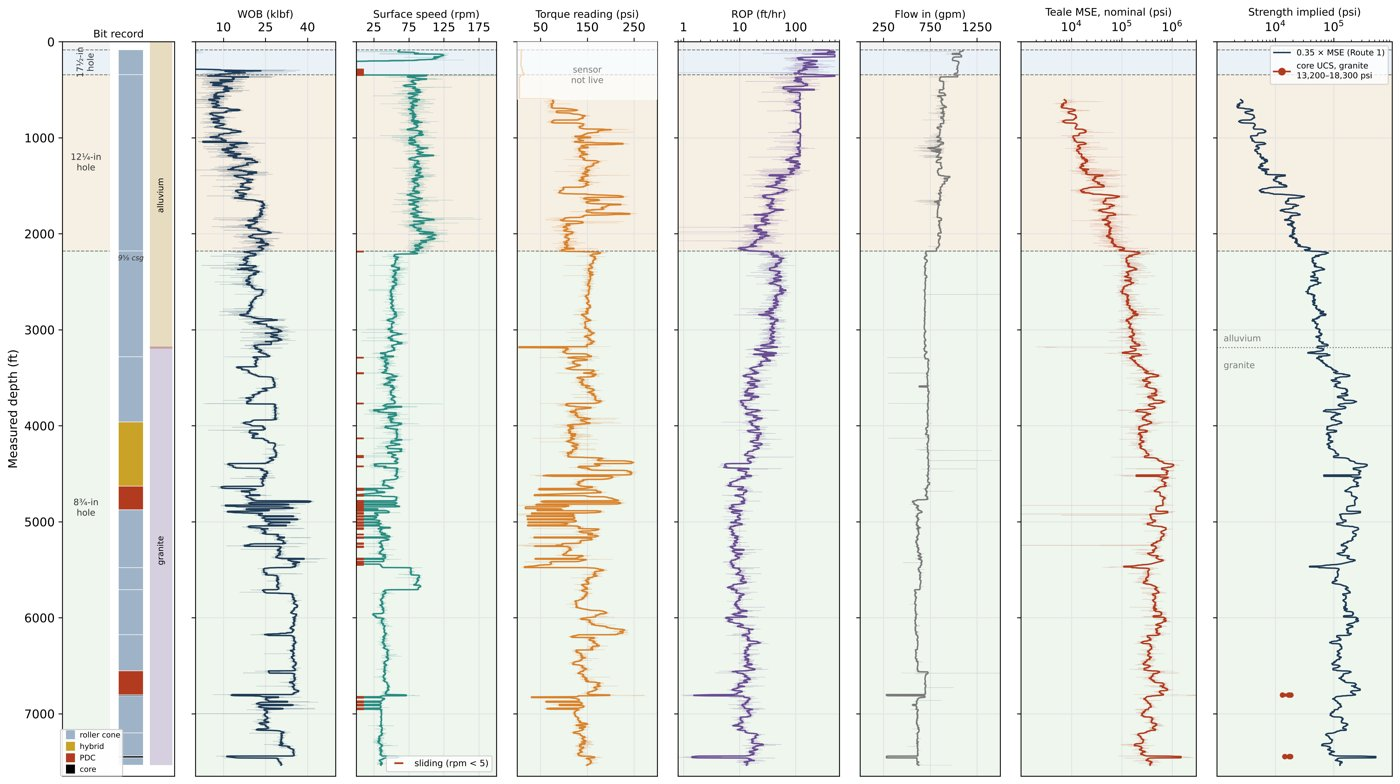

f02_bit_rock_physics.png


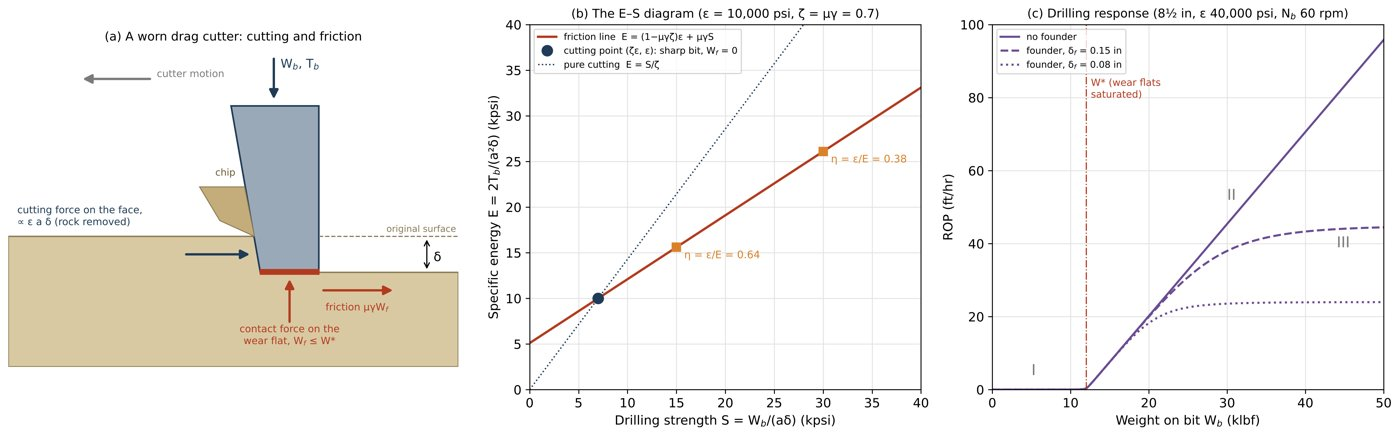

f03_sliding_motor.png


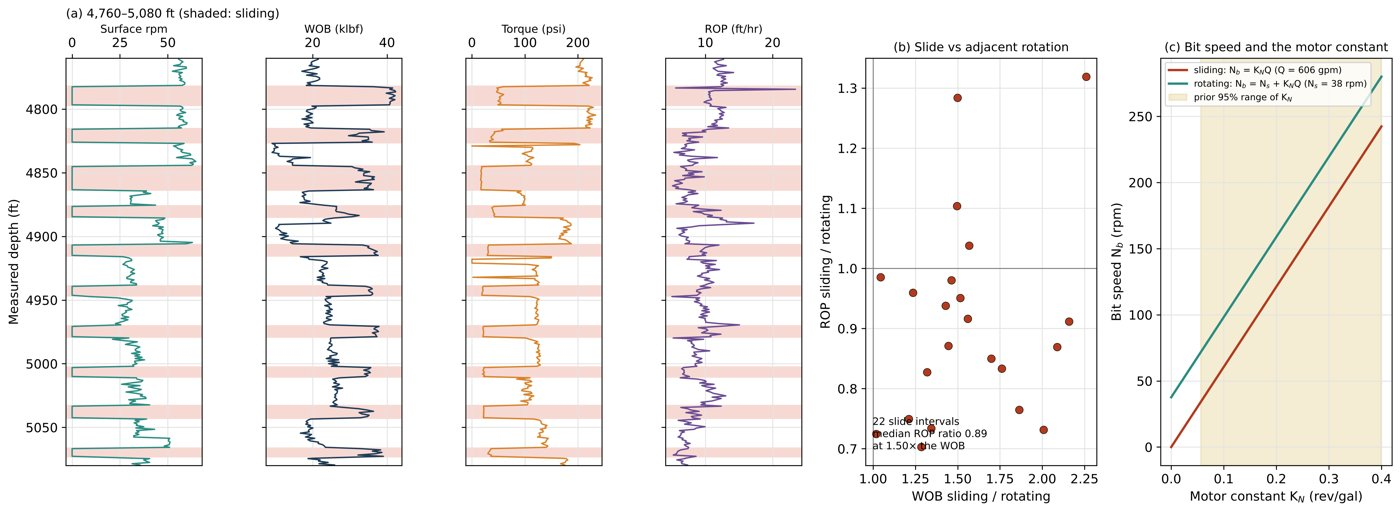

f04_torque_wob.png


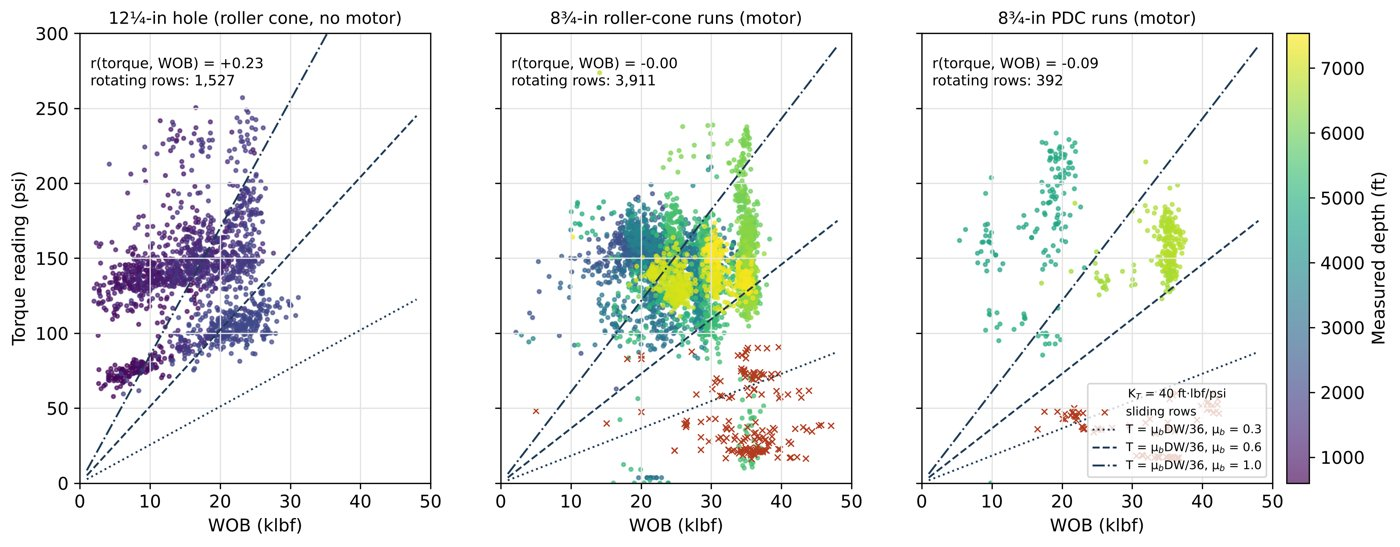

f05_mse_efficiency.png


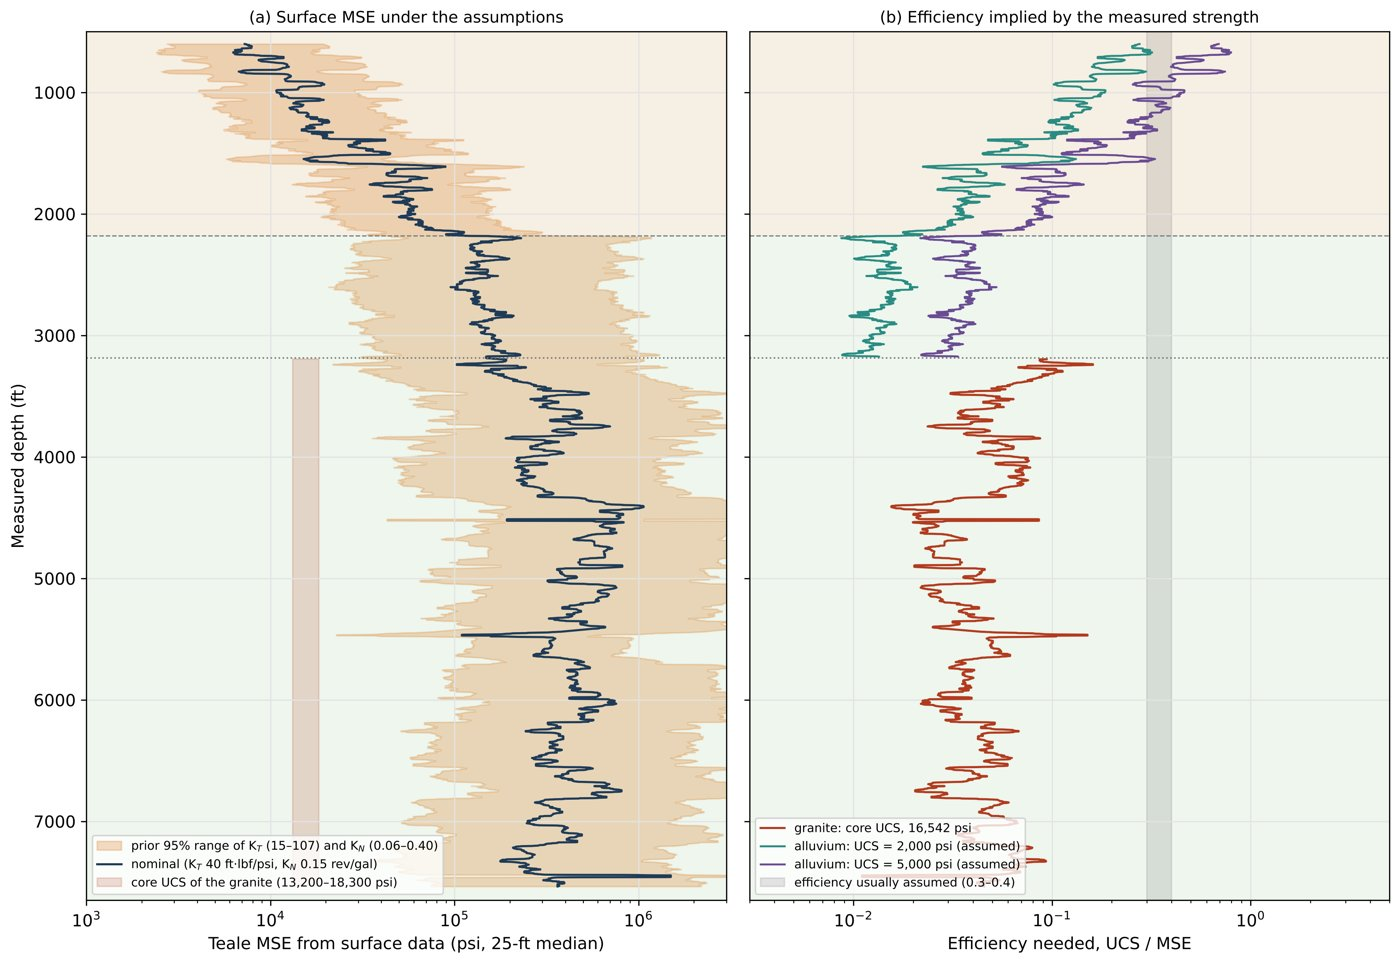

f06_noise_library.png


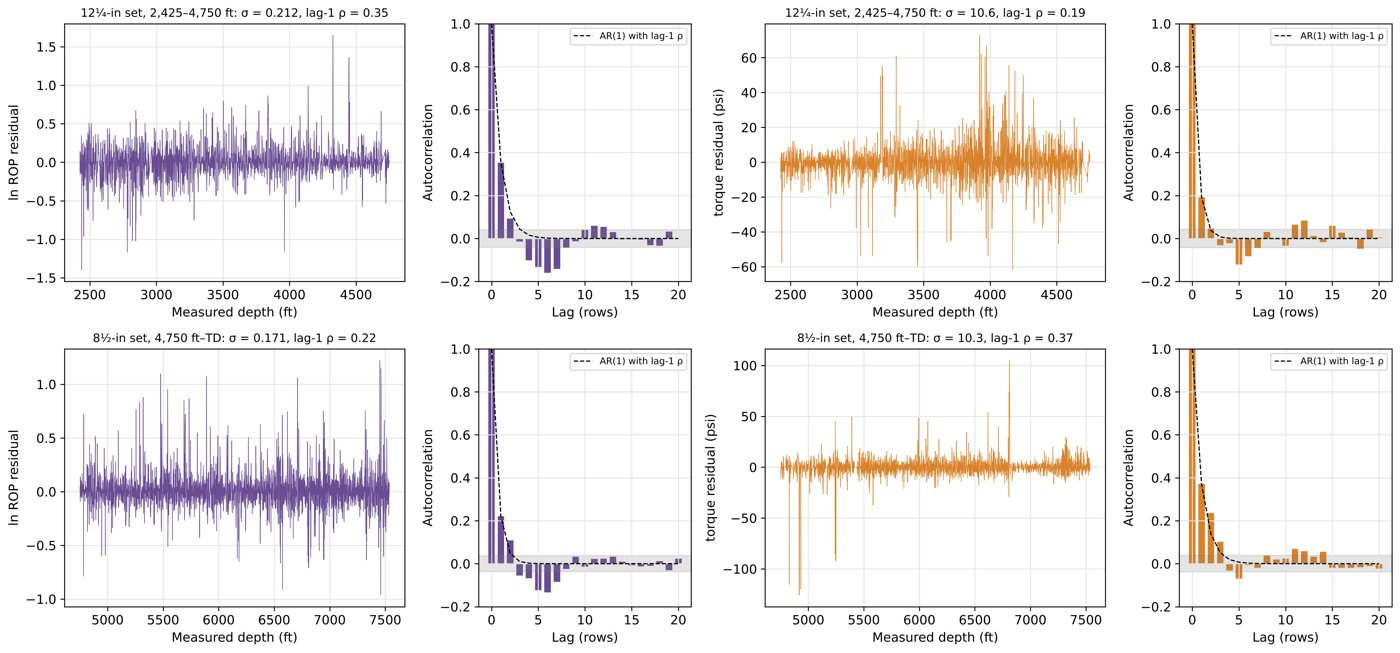

f07_forward_checks.png


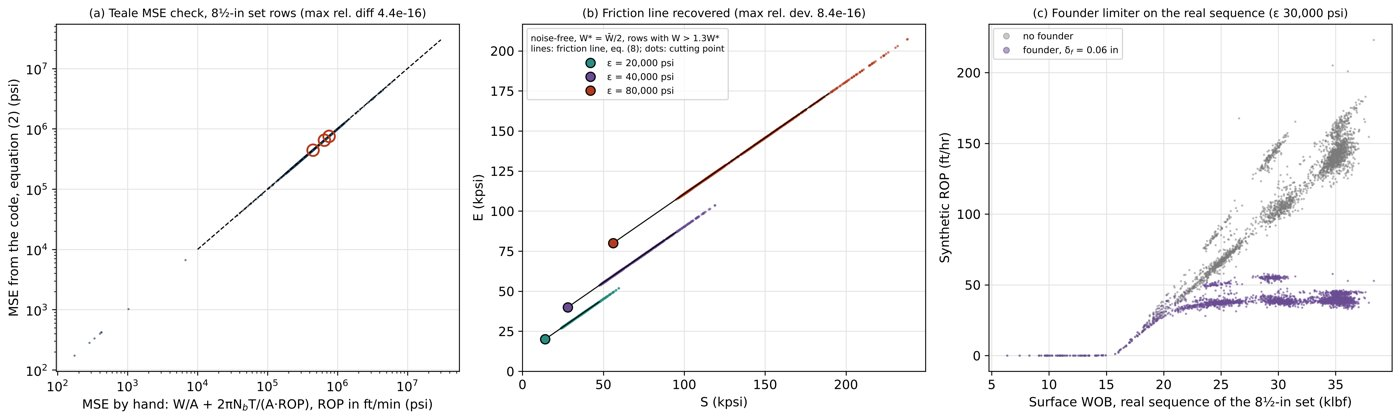

f08_synthetic_design.png


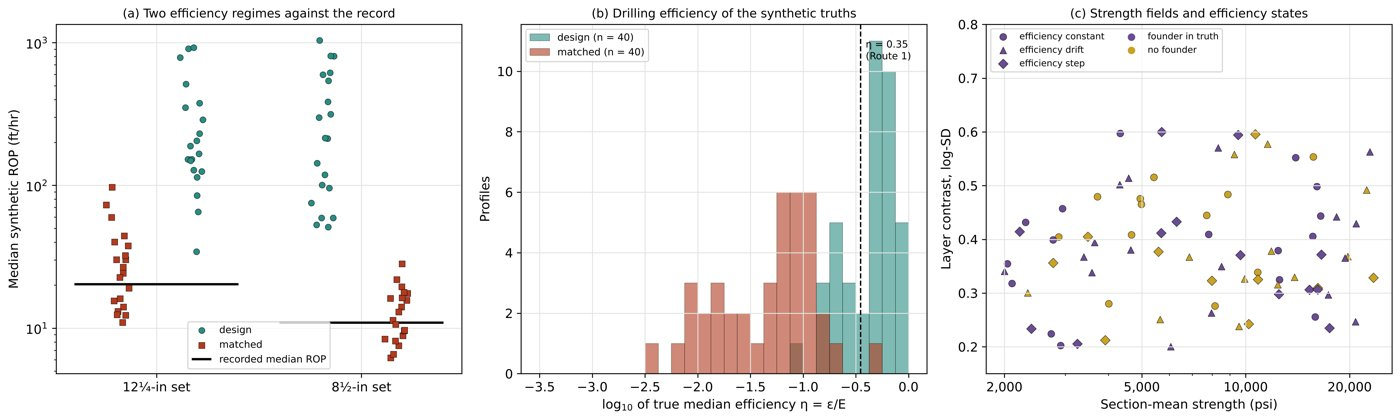

f09_example_profile.png


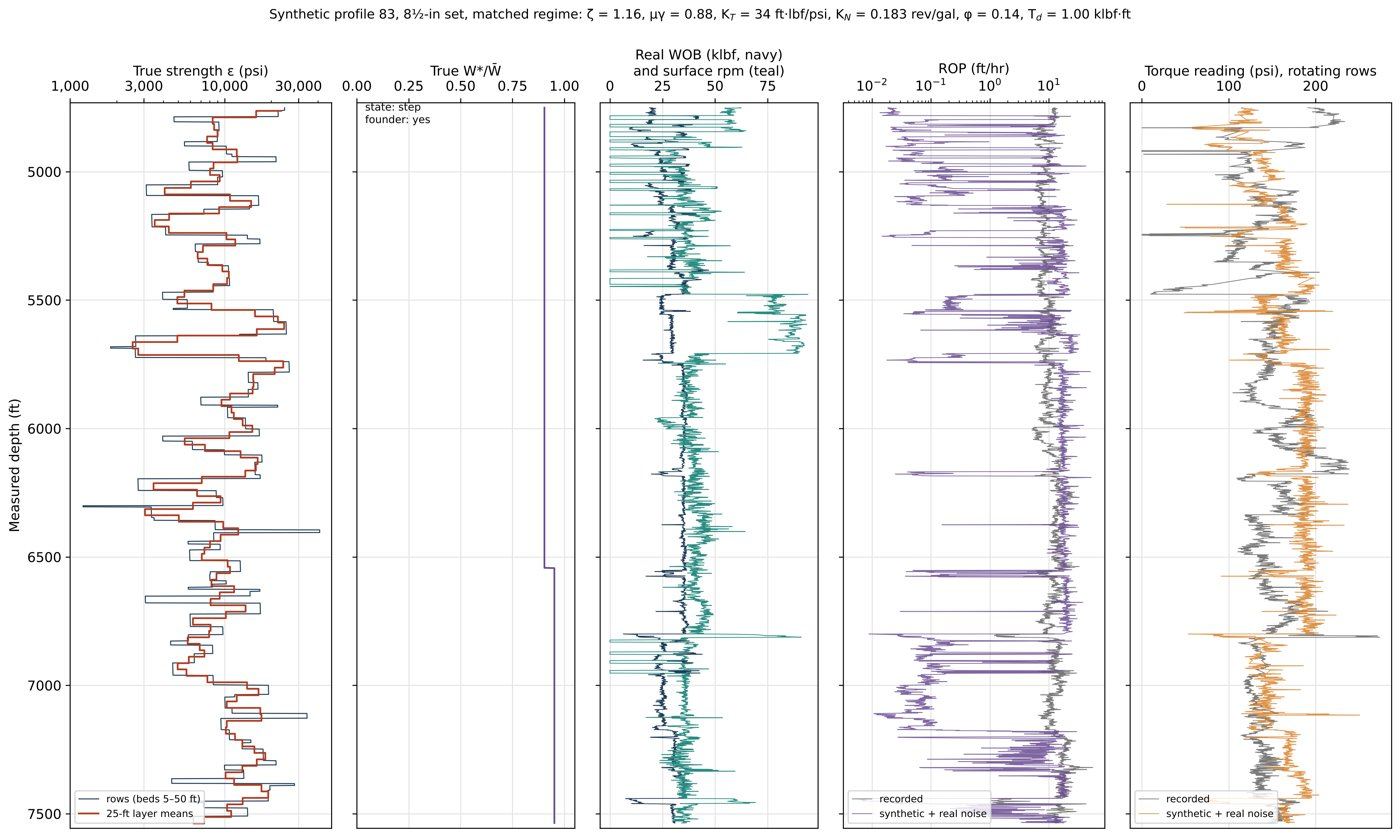

f10_workflow.png


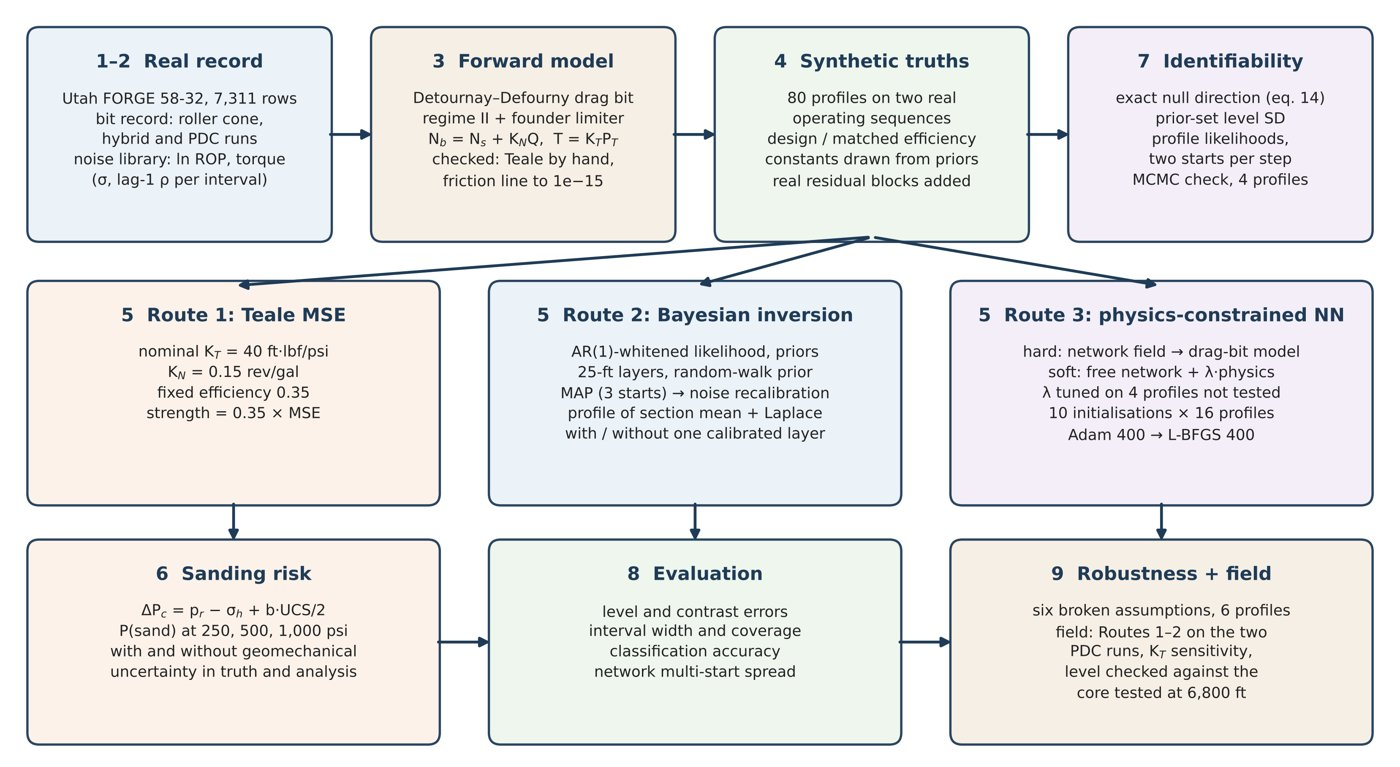

f11_null_direction.png


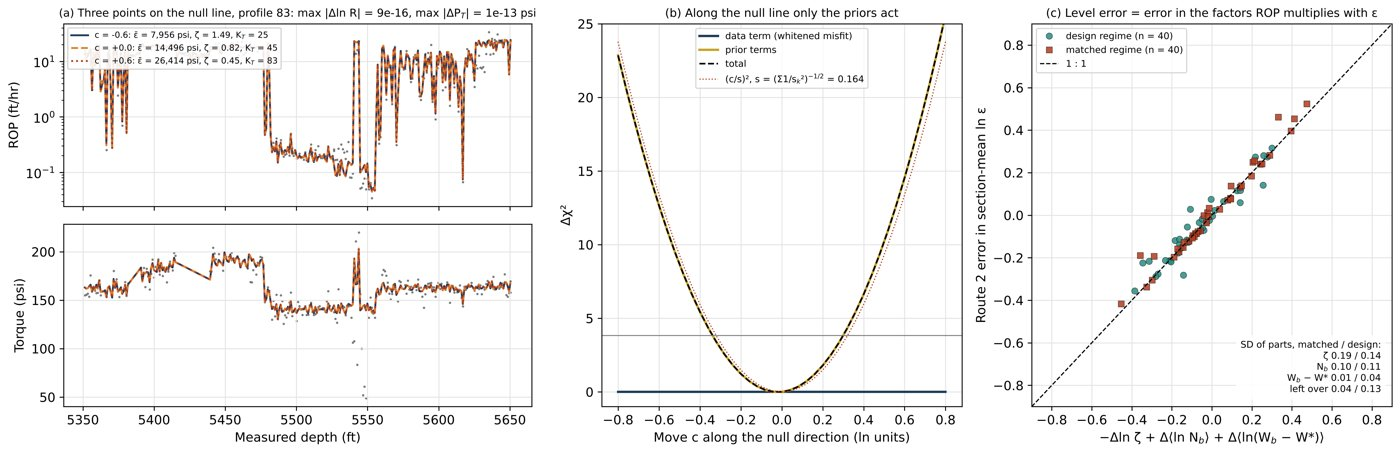

f12_profile_likelihoods.png


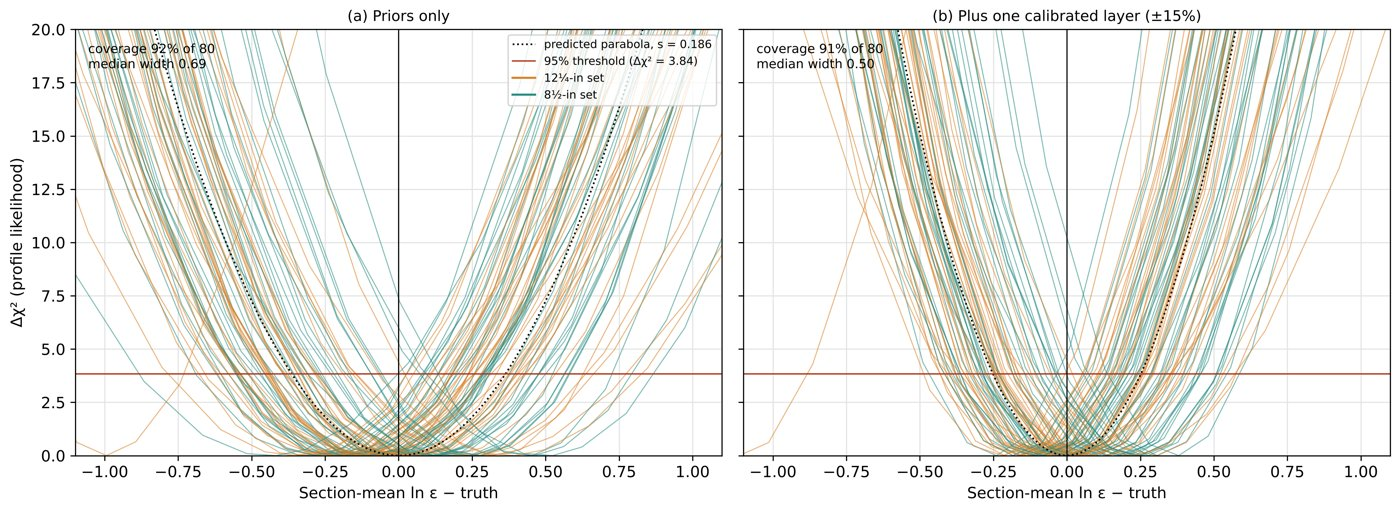

f13_contrast_recovery.png


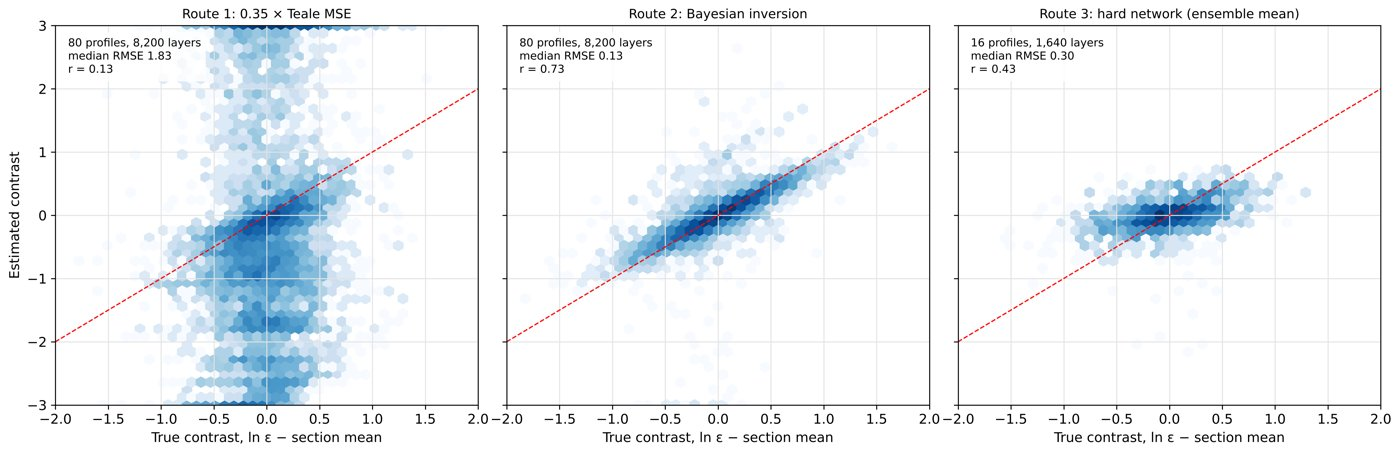

f14_route1_efficiency.png


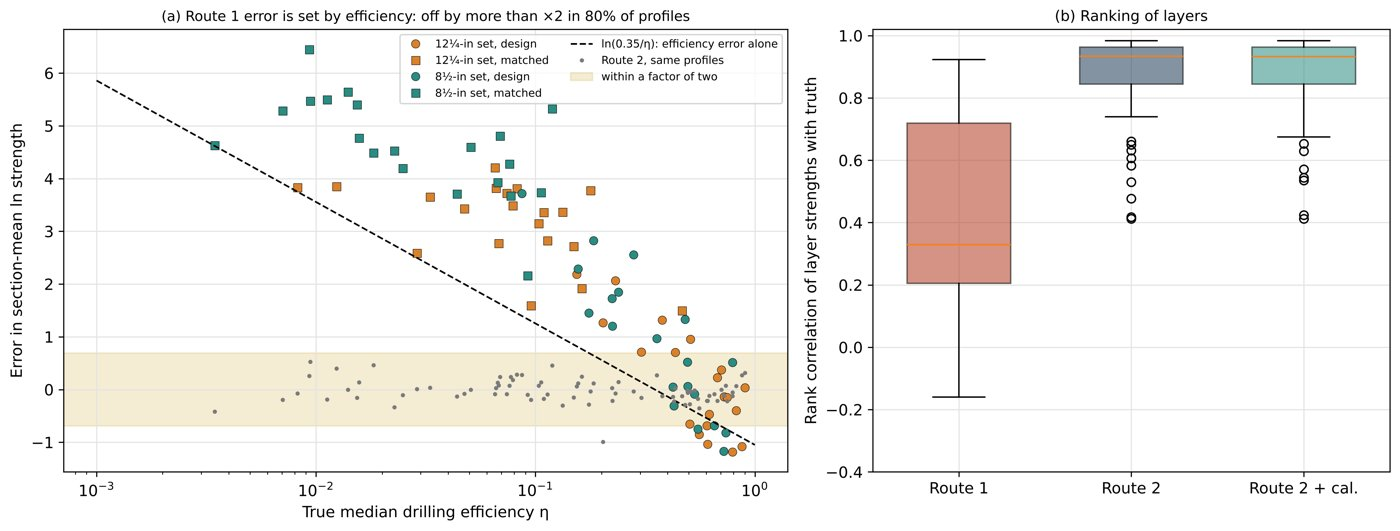

f15_level_intervals.png


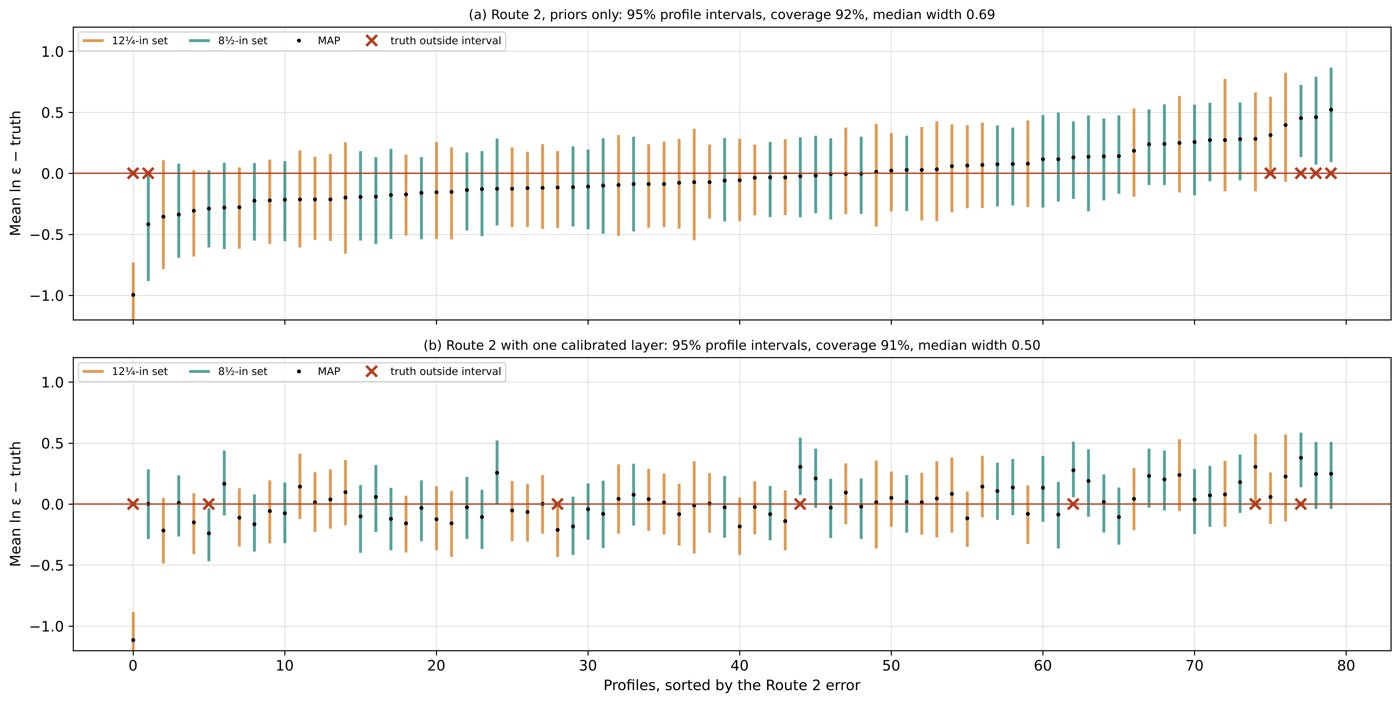

f16_uncertainty_calibration.png


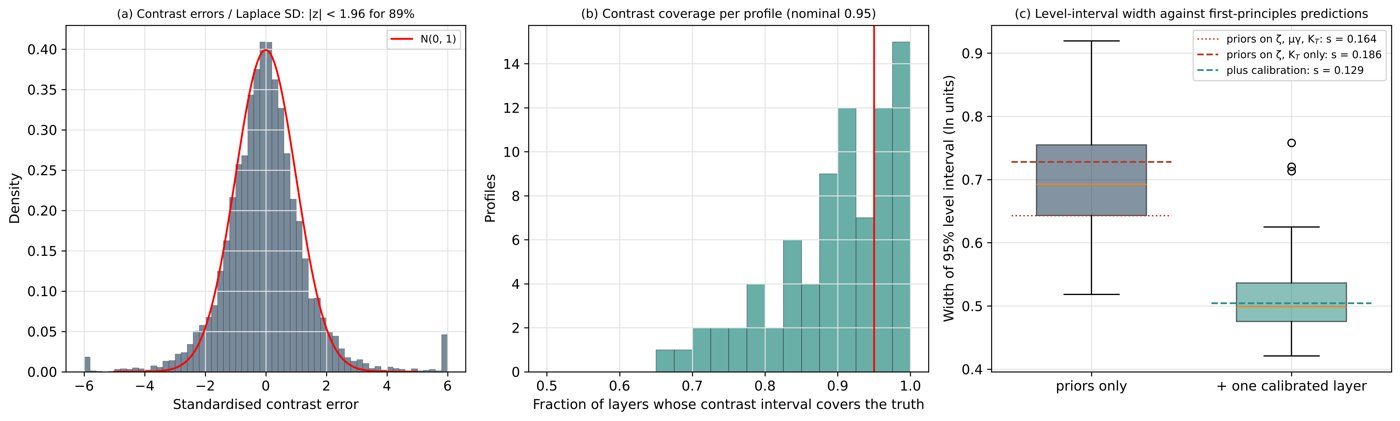

f17_network_multistart.png


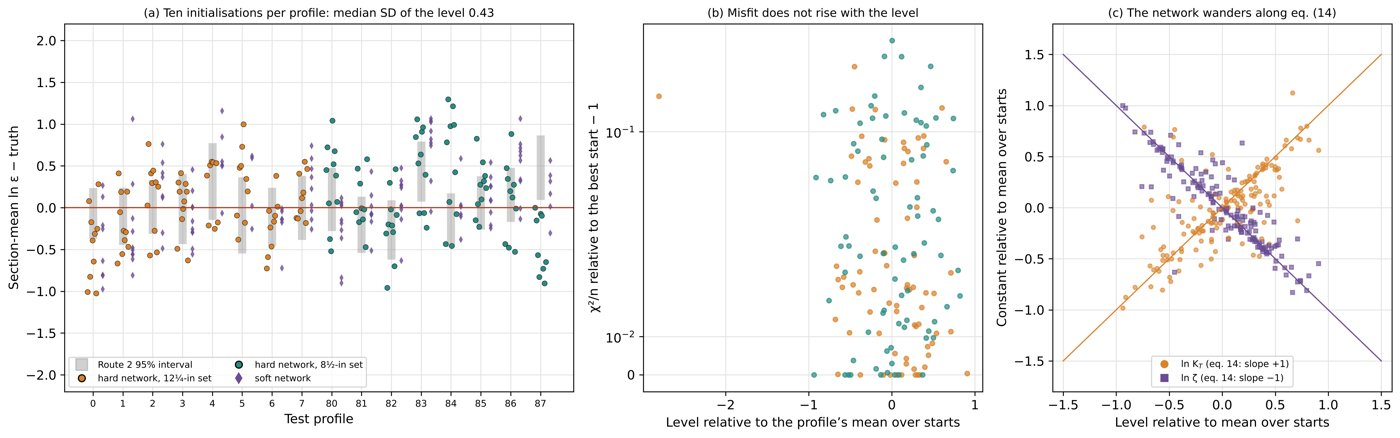

f18_mcmc_check.png


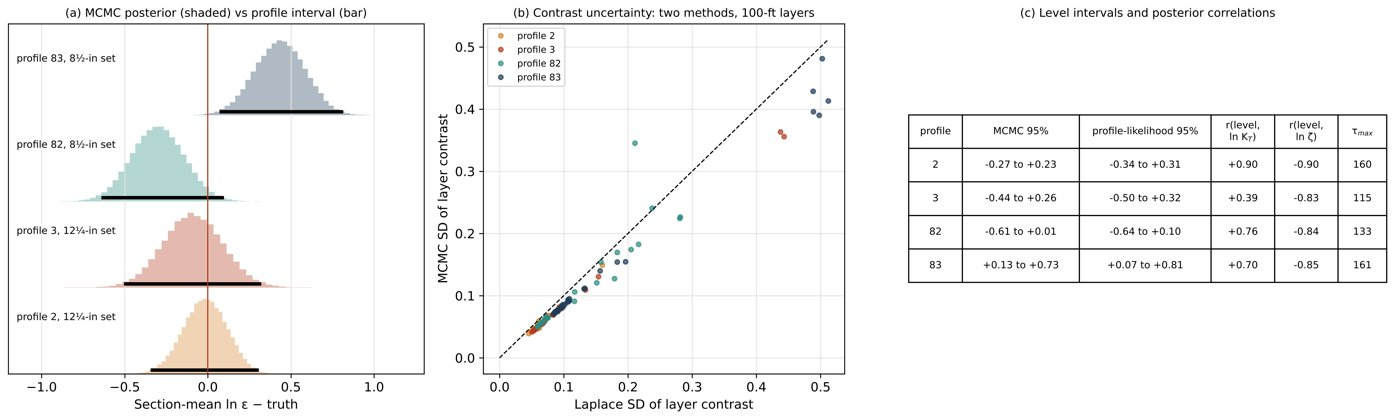

f19_example_logs.png


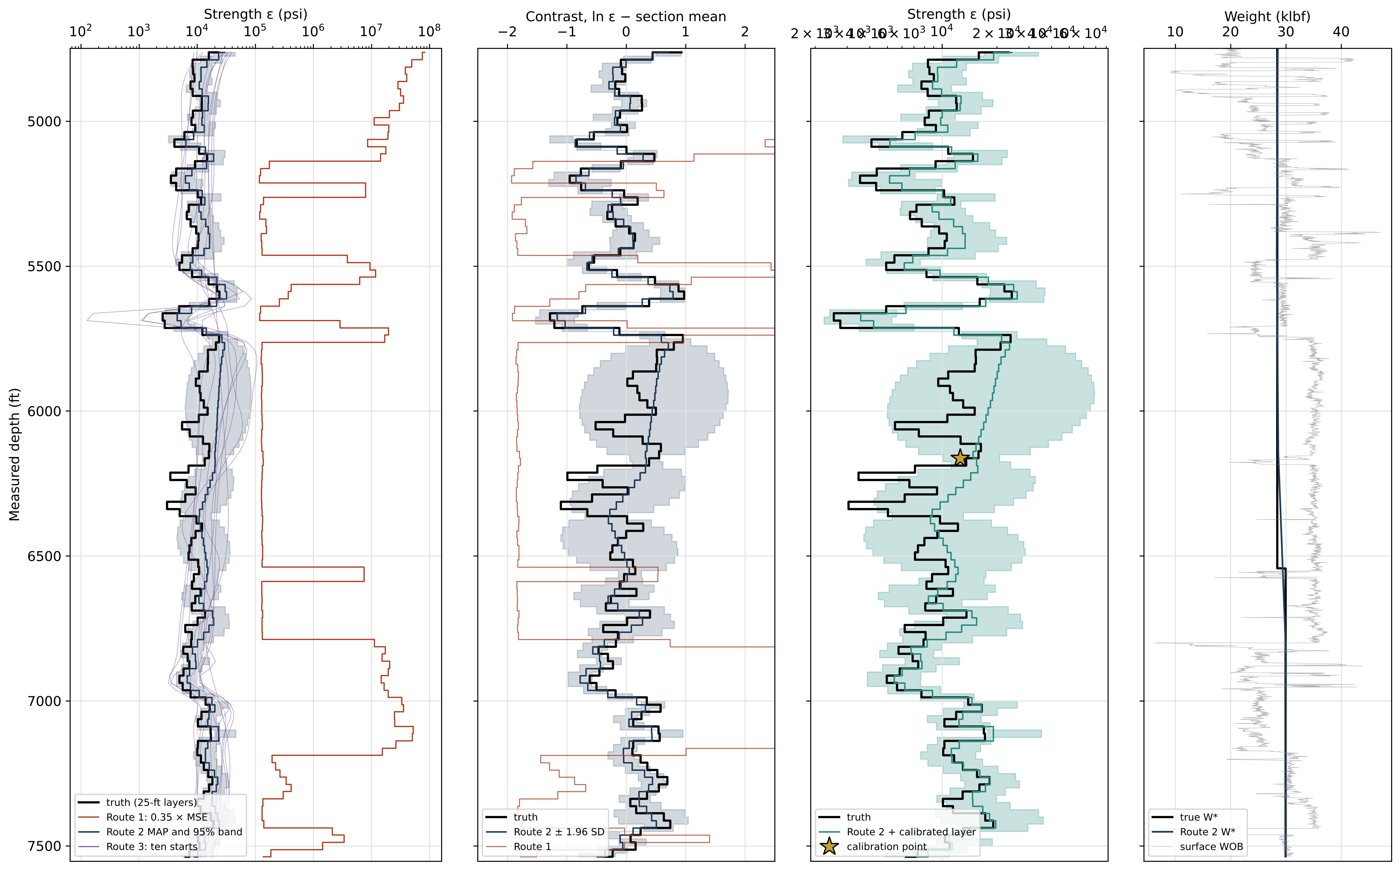

f20_sanding_example.png


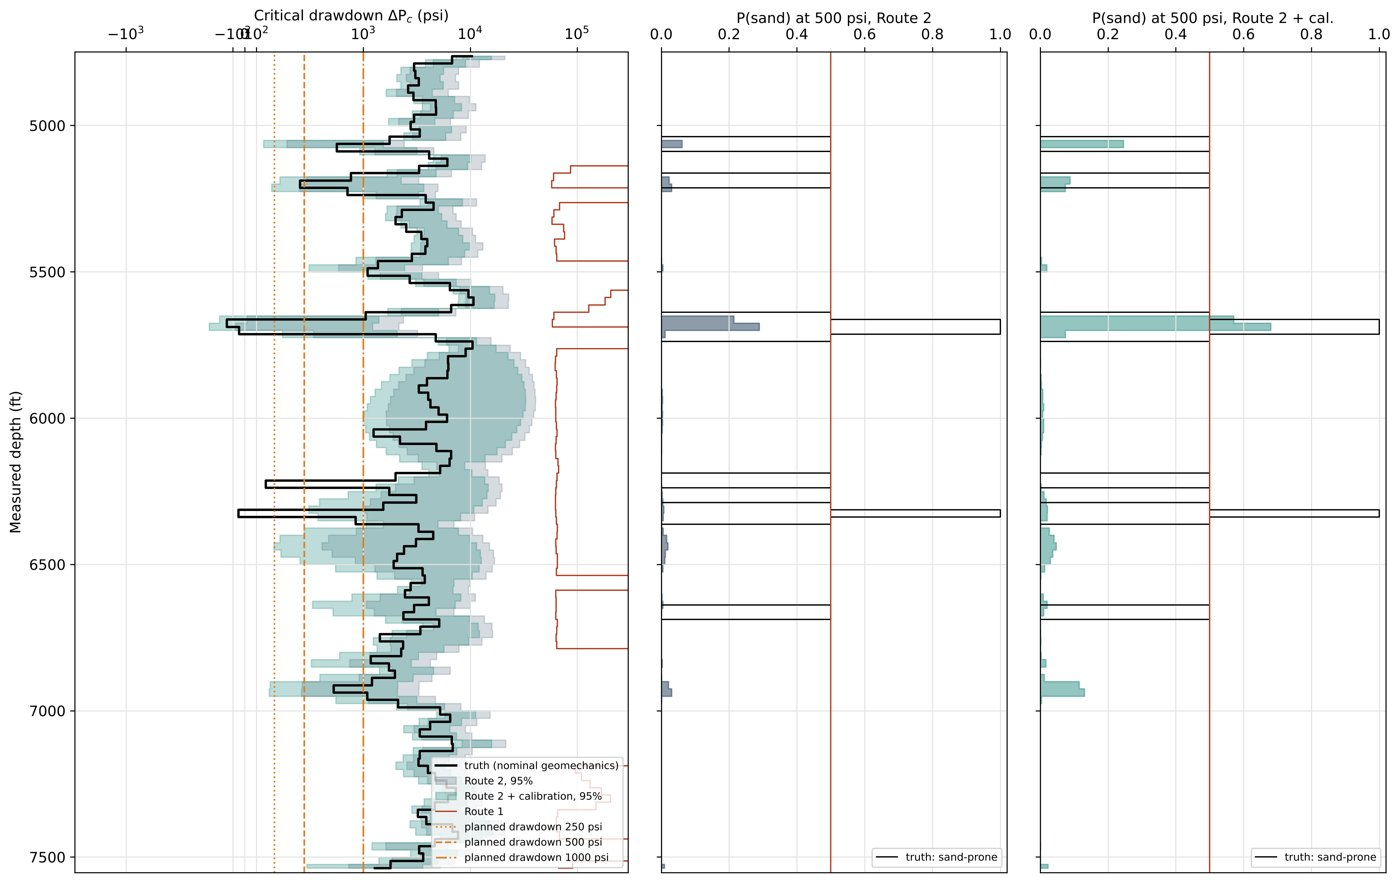

f21_sanding_classification.png


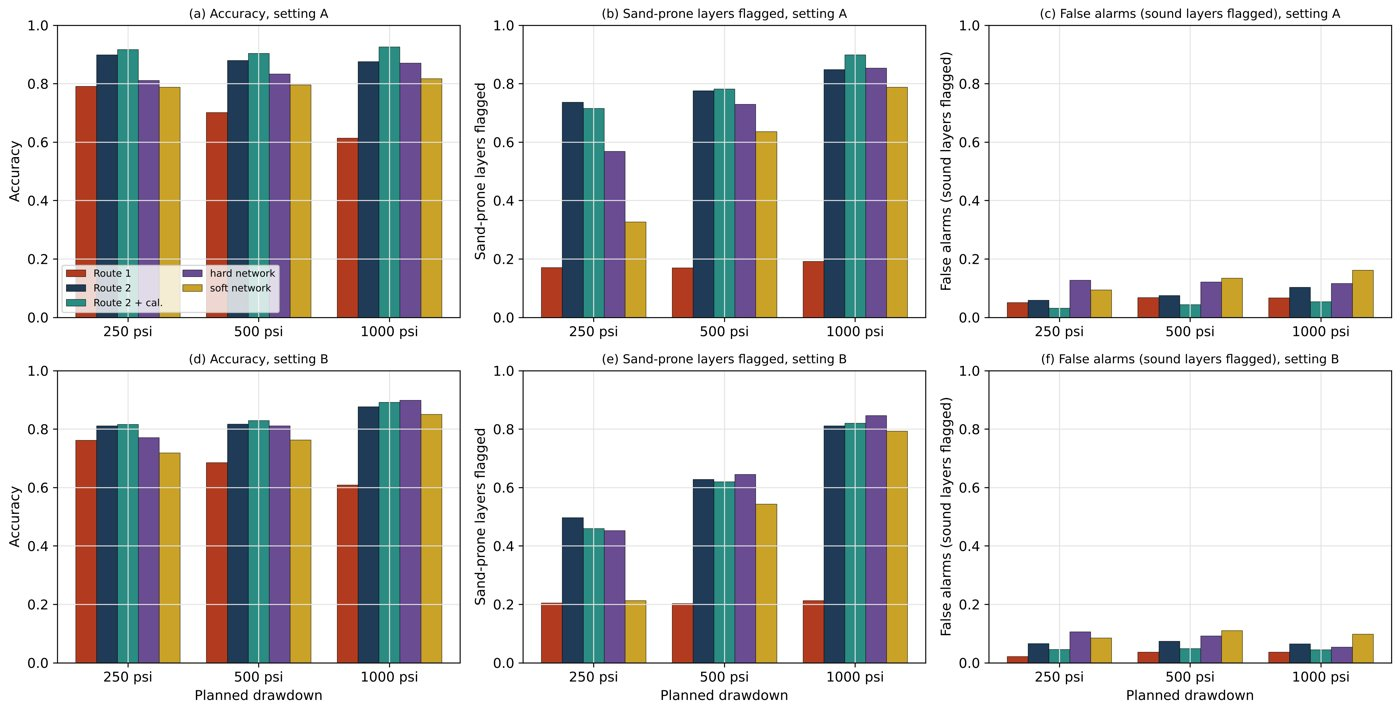

f22_calibration_value.png


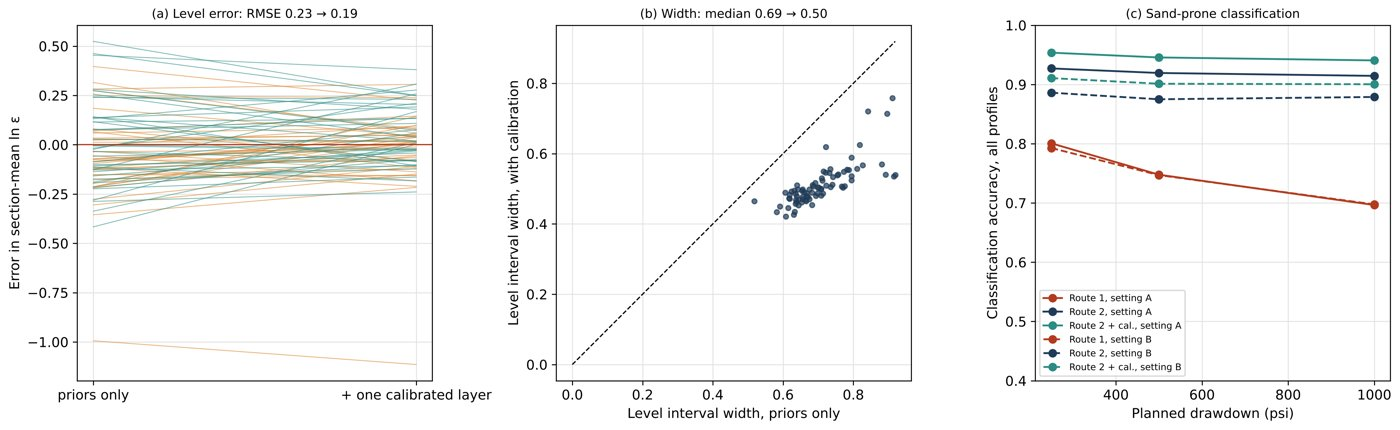

f23_field_strength.png


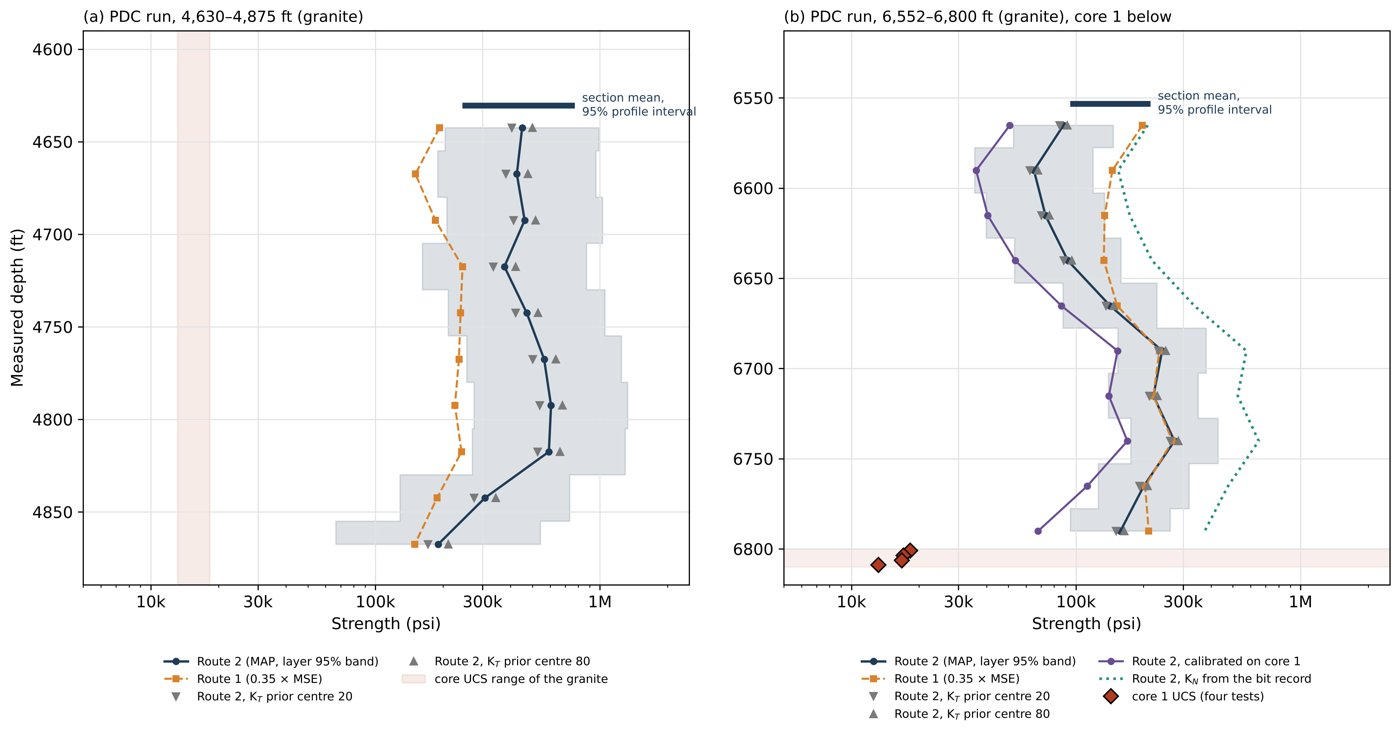

f24_field_fit.png


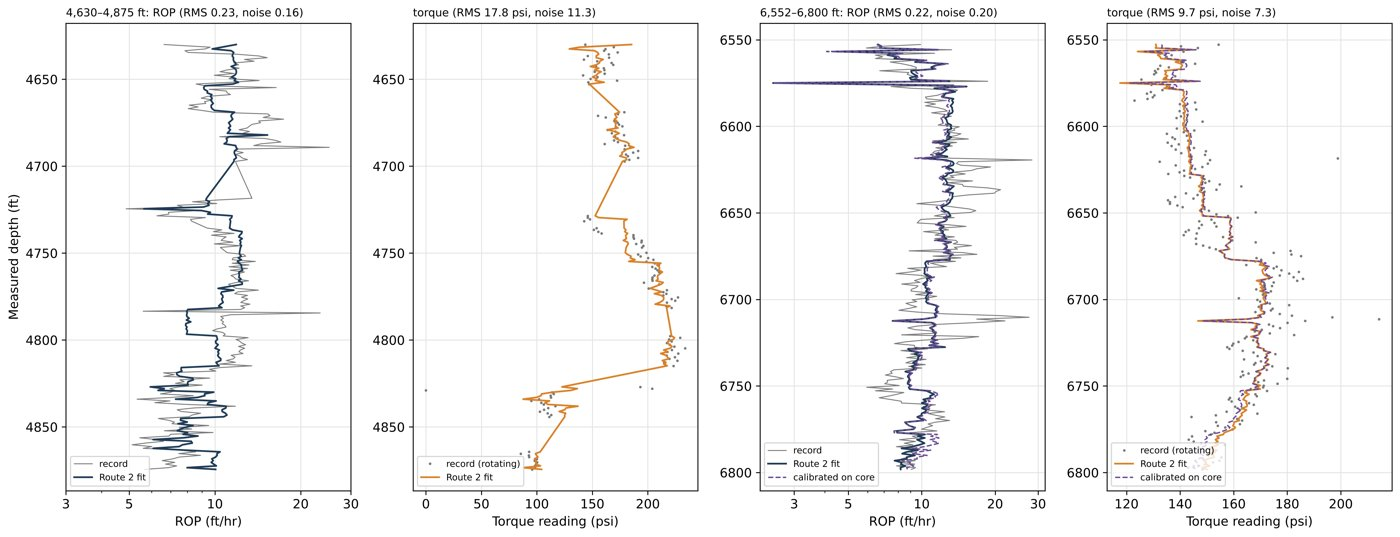

f25_field_ranking_drawdown.png


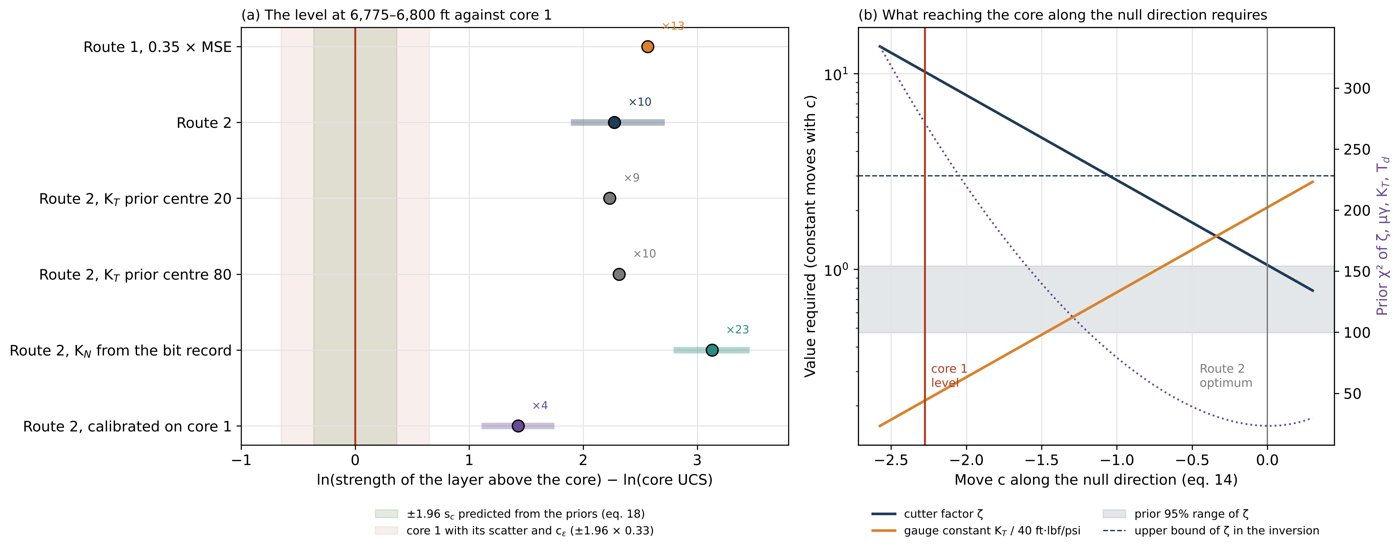

f26_robustness.png


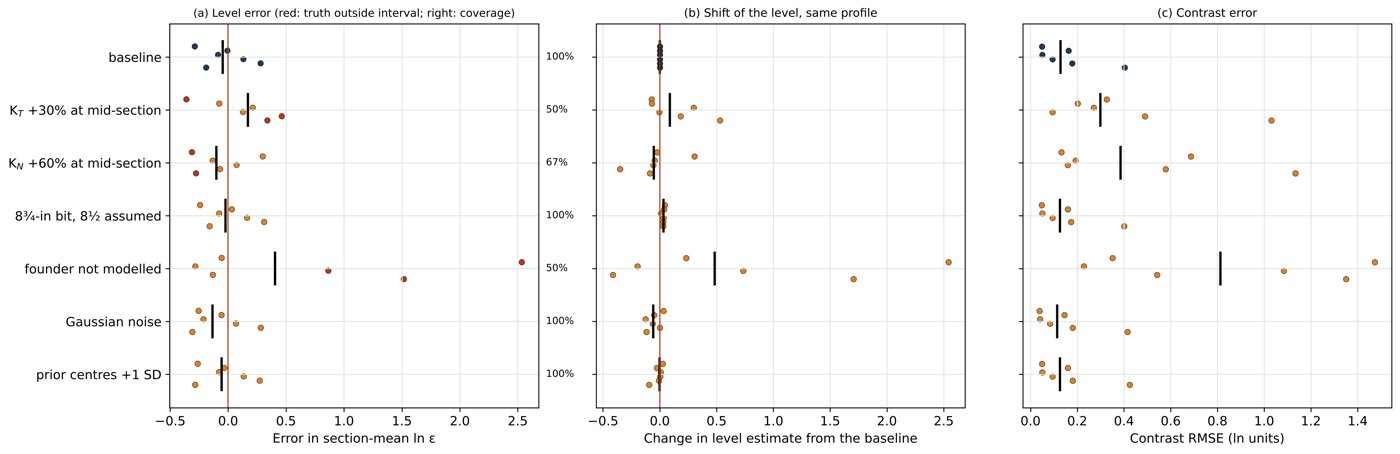

f27_decision_chart.png


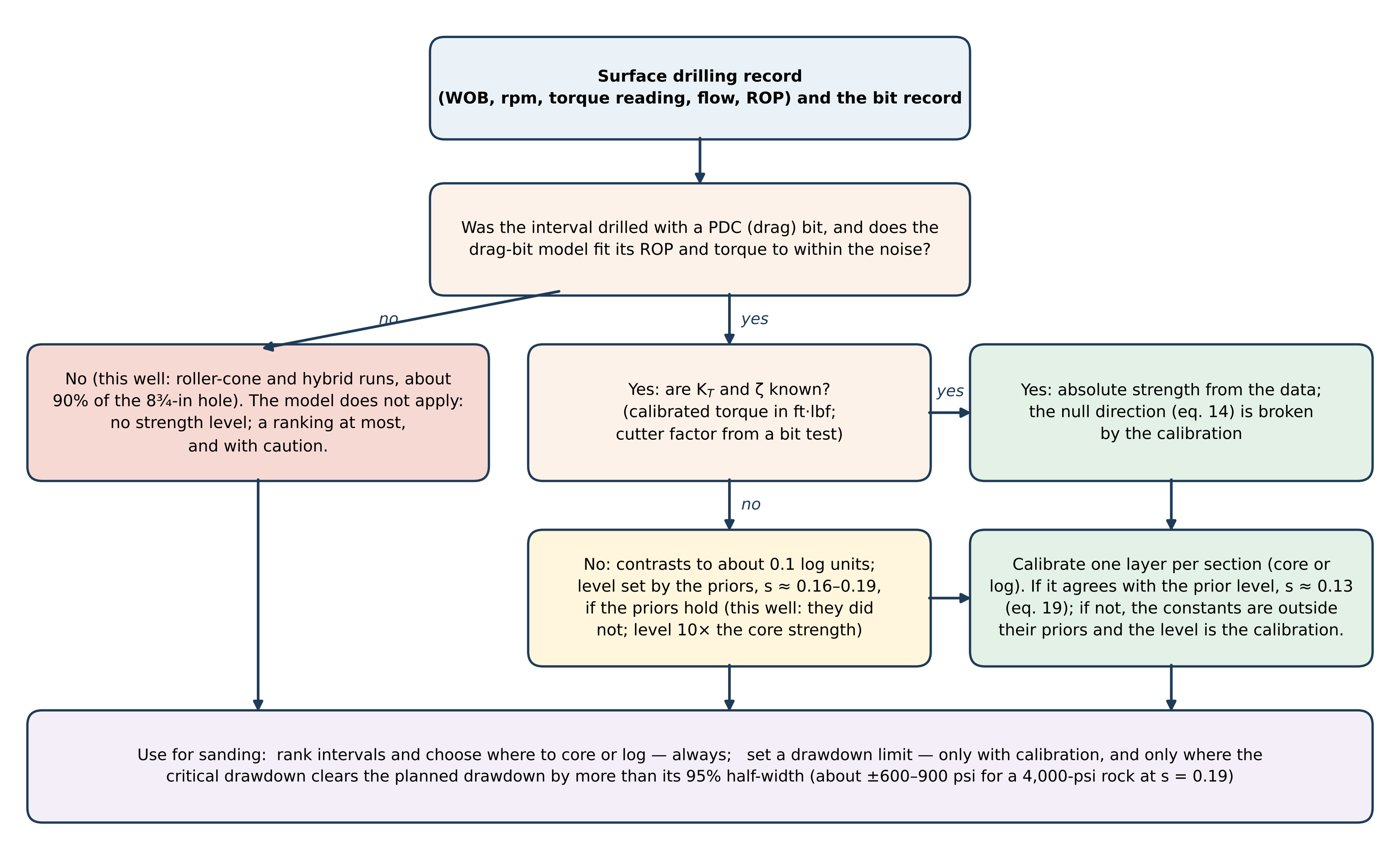

In [27]:
for s in ['t4_figs_a.py', 't4_figs_b.py', 't4_figs_c.py', 't4_figs_field3.py', 't4_figs_d.py']:
    t0 = time.time(); r = subprocess.run([sys.executable, s], capture_output=True, text=True); print(s, 'exit', r.returncode, f'{time.time()-t0:.0f} s')
    if r.returncode: print(r.stderr[-2000:])
import io
from PIL import Image as PILImage
for f in sorted(glob.glob(W + 'figs/f*.png')):                     # shown at screen resolution; the full 300-dpi files are in figs/
    im = PILImage.open(f).convert('RGB'); im.thumbnail((1400, 1400)); buf = io.BytesIO(); im.save(buf, format='JPEG', quality=85)
    print(os.path.basename(f)); display(Image(data=buf.getvalue(), format='jpeg', width=900))

## L. Every number quoted in the paper

`t4_collect.py` gathers the quoted values into `paper/R.json`; the paper's text is generated from that file.

In [28]:
%%writefile t4_collect.py
# Gather every number the paper quotes into paper/R.json.
import os, sys, json
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4_core import CK
R = dict(A=json.load(open(CK+'analysis/R_analysis.json')), S=json.load(open(CK+'figs_a_stats.json')), D=json.load(open(CK+'prop_data_stats.json')),
         F3=json.load(open(CK+'figs_field3_stats.json')))
tune = json.load(open(CK+'t4_pcnn/tune.json')); R['tune'] = dict(vals=tune, best=min(tune, key=tune.get))
# the worked example (profile 83): founder zone, efficiency, and the sanding flags of Figure 20
import pickle, numpy as np, pandas as pd
from t4_core import load_section, smooth_pos, p_sand, LAYER_FT
P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}; pr = P[83]; d = load_section('8.5'); c = pr['consts']
dDD = smooth_pos(d['W']*(1 - c['phi']*d['s']) - pr['frac_rows']*d['Wbar'])/(np.exp(c['ln_zeta'])*np.exp(pr['ln_eps_rows'])*d['a']); ratio = dDD/np.exp(pr['ln_df'])
k = (d['z'] >= 5750) & (d['z'] < 6600)
r = json.load(open(CK+'t4_runs/r083.json')); nL = d['nL']; z = d['z'][0] + (np.arange(nL) + 0.5)*LAYER_FT; t = np.array(r['true_layer']); tm = t.mean()
def lay(rr): L = np.array(rr['map'][:nL]); sdl = (rr['prof']['hi'] - rr['prof']['lo'])/3.92; return L, np.sqrt(np.array(rr['sd_con'])**2 + sdl**2)
L2, s2 = lay(r['route2']); L2c, s2c = lay(r['route2_cal']); tru = (0.45*z - 0.70*z + np.exp(t)/2) < 500
p2 = p_sand(L2, s2, z, 500.0, geo=False); p2c = p_sand(L2c, s2c, z, 500.0, geo=False)
Rr = pd.read_csv(CK+'analysis/route12_by_profile.csv').set_index('id')
R['EX83'] = dict(eta=float(Rr.loc[83, 'eta_true']), frac_beyond=float(np.mean(ratio[k] > 1)), ratio_med=float(np.median(ratio[k])), frac_beyond_out=float(np.mean(ratio[~k] > 1)),
                 r1_err=float(np.mean(r['route1_ln_ucs']) - tm), r2_err=float(L2.mean() - tm), r2_lo=r['route2']['prof']['lo'] - tm, r2_hi=r['route2']['prof']['hi'] - tm,
                 r2c_err=float(L2c.mean() - tm), r2c_lo=r['route2_cal']['prof']['lo'] - tm, r2c_hi=r['route2_cal']['prof']['hi'] - tm, z_cal=float(z[r['calib']['layer']]),
                 n_sand=int(tru.sum()), flag_r2=int((p2[tru] > 0.5).sum()), flag_r2c=int((p2c[tru] > 0.5).sum()), pmax_r2=float(p2[tru].max()), pmax_r2c=float(p2c[tru].max()),
                 fa_r2=int((p2[~tru] > 0.5).sum()), fa_r2c=int((p2c[~tru] > 0.5).sum()))
first = CK+'analysis/r117_first_pass.json'
if os.path.exists(first) and os.path.exists(CK+'t4_runs/r117.json'):
    a = json.load(open(first)); b = json.load(open(CK+'t4_runs/r117.json')); tm7 = float(np.mean(b['true_layer']))
    R['P117'] = dict(first_lo=a['route2']['prof']['lo'] - tm7, first_hi=a['route2']['prof']['hi'] - tm7, lo=b['route2']['prof']['lo'] - tm7, hi=b['route2']['prof']['hi'] - tm7,
                     gain=float(min(dd for vv, dd in zip(a['route2']['prof']['v'], a['route2']['prof']['d']) if vv > a['route2']['prof']['est'])), n_retrace=b['route2']['prof'].get('n_retrace', 0), err=float(np.mean(b['route2']['map'][:len(b['true_layer'])]) - tm7))
json.dump(R, open(CK+'paper/R.json', 'w'), indent=1, default=float); print('R.json written', os.path.getsize(CK+'paper/R.json'))

Writing t4_collect.py


In [29]:
%run t4_collect.py
R = json.load(open(W + 'paper/R.json')); A = R['A']
print(json.dumps({k: A['all'][k] for k in ['r1', 'r2', 'r2c']}, indent=1))
print('prior-only level SD (eqs 17-18):', round(A['sd_level_prior_formula'], 3), '-', round(A['sd_level_prior_formula2'], 3), '| with calibration (eq 19):', round(A['sd_level_cal_formula'], 3))
print(json.dumps(A['route3'], indent=1))
F3 = R['F3']; print(json.dumps({k: {kk: F3[k][kk] for kk in ['mean', 'lo', 'hi', 'r1', 'rmsR', 'rmsT']} for k in ['pdc1', 'pdc2']}, indent=1))
print('core 1 ln UCS', round(F3['core']['ln'], 3), '| layer above core: Route 2', round(F3['pdc2']['last'], 3), '(x', round(np.exp(F3['pdc2']['last'] - F3['core']['ln']), 1), '), calibrated', round(F3['pdc2']['cal']['last'], 3), ', K_N from bit record', round(F3['pdc2']['kn']['last'], 3))

R.json written 40412
{
 "r1": {
  "n": 80,
  "lev_med": 2.237480262735769,
  "lev_abs_med": 2.237480262735769,
  "lev_rmse": 3.0160745351153353,
  "rmse_med": 1.8325441045615332,
  "rho_med": 0.3289574228160501,
  "frac_factor2": 0.8,
  "frac_rmse_lt_0p1": 0.0
 },
 "r2": {
  "n": 80,
  "lev_med": -0.056875105369209145,
  "lev_abs_med": 0.13435319971722404,
  "lev_rmse": 0.22735370715155007,
  "rmse_med": 0.12711092012638492,
  "rho_med": 0.9335557112105786,
  "cover": 0.925,
  "width_med": 0.6922808336791286,
  "finite": 1.0,
  "ccover_med": 0.9139784946236559,
  "ccover_mean": 0.8883604550691244,
  "sdcon_med": 0.0963751111467692,
  "zsd_med": 1.1235710773626608,
  "sdlap_med": 0.18448426082178268,
  "frac_rmse_lt_0p1": 0.3375
 },
 "r2c": {
  "n": 80,
  "lev_med": 0.01455094557768355,
  "lev_abs_med": 0.09055772294074327,
  "lev_rmse": 0.1876483825439016,
  "rmse_med": 0.12715673729124352,
  "rho_med": 0.932765572146103,
  "cover": 0.9125,
  "width_med": 0.49877323858966127,
  "finite

## M. Export of the cleaned dataset and the synthetic-profile tables (Data availability)

`Topic4_MSE_Strength_CLEANED_DATA.csv` holds one row per raw record with the cleaned channels, the hole section, bit run and lithology from the bit record, the flags used in the study, Teale MSE at the actual bit size, the noise residuals of the two synthetic sets and the Route 2 results on the two PDC runs; `Topic4_MSE_Strength_SCENARIOS.csv` lists the 80 profiles with their truths and every route's results; `Topic4_MSE_Strength_SCENARIO_LAYERS.csv` gives the truth and the estimates layer by layer.

In [30]:
%%writefile t4_export.py
# Export the cleaned dataset, the synthetic-profile table, the per-layer series and a data dictionary for Topic 4.
import os, sys, json, glob, pickle, numpy as np, pandas as pd
os.environ.setdefault('T3_DATA', '/mnt/user-data/outputs/field_data.csv')
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from t4data import df, circ
from t4_core import *
EXP = os.environ.get('T4_EXPORT', '/mnt/user-data/outputs/')
import t4_core
t4_core.SECTIONS['pdc1'] = dict(name='PDC run, 4,630–4,875 ft', top=4630.0, base=4875.0, D=8.75, motor=True)
t4_core.SECTIONS['pdc2'] = dict(name='PDC run, 6,552–6,800 ft', top=6552.0, base=6800.0, D=8.75, motor=True)
KT0, KN0 = np.exp(PRIOR['ln_KT'][0]), np.exp(PRIOR['ln_KN'][0])

# ---------------- cleaned record ----------------
out = df[['row_id', 'Depth', 'WOB', 'RPM', 'Torque', 'ROP_1ft', 'ROP_1min', 'FlowIn', 'PumpPress', 'Hookload']].copy().sort_values('Depth').reset_index(drop=True)
# hole sections, bit runs and lithology from the well's bit record and end-of-well report (Nash and Moore, 2018)
out['hole_section'] = [hole_of(z)['name'] for z in out.Depth]; out['bit_in'] = [hole_of(z)['D'] for z in out.Depth]
br = [bit_run(z) for z in out.Depth]
out['bit_type'] = [b[2] for b in br]; out['bit_model'] = [b[3] for b in br]; out['motor'] = [b[4] for b in br]
out['lithology'] = [next(l[2] for l in LITH if l[0] <= z < l[1]) for z in out.Depth]
out['circulating'] = out.FlowIn > 50; out['ROP_clipped'] = out.ROP_1ft.clip(0.5, 500)
out['on_bottom'] = out.circulating & (out.WOB > 2) & (out.ROP_clipped > 1) & (out.Depth > 84)
out['sliding'] = out.on_bottom & (out.RPM < 5); out['torque_live'] = out.Depth >= TORQUE_LIVE
A = np.pi*out.bit_in**2/4; Nb = np.where(out.sliding, 0.0, out.RPM) + np.where(out.motor, KN0*out.FlowIn, 0.0)
mse = 1000*out.WOB/A + 120*np.pi*Nb*KT0*out.Torque/(A*out.ROP_clipped)
ok = out.on_bottom & ~out.sliding & out.torque_live
out['Teale_MSE_nominal_psi'] = np.where(ok, mse, np.nan); out['Route1_strength_psi'] = 0.35*out.Teale_MSE_nominal_psi

def rows_of(key):
    d = load_section(key); idx = out.index[out.Depth.isin(d['z']) & out.on_bottom & out.torque_live & (out.Depth >= SECTIONS[key]['top']) & (out.Depth < SECTIONS[key]['base'])]
    zmap = pd.Series(np.arange(len(d['z'])), index=d['z']); j = zmap.reindex(out.loc[idx, 'Depth']).values
    good = ~np.isnan(j); return d, idx[good], j[good].astype(int)

# synthetic sets: the two intervals whose operating sequence and noise drive the synthetic profiles
out['synthetic_set'] = ''; out['set_layer_25ft'] = np.nan; out['res_lnROP'] = np.nan; out['res_torque_psi'] = np.nan
for key, lab in [('12.25', '12¼-in set'), ('8.5', '8½-in set')]:
    d, idx, j = rows_of(key)
    out.loc[idx, 'synthetic_set'] = lab; out.loc[idx, 'set_layer_25ft'] = d['layer'][j]; out.loc[idx, 'res_lnROP'] = d['res_lnR'][j]
    out.loc[idx, 'res_torque_psi'] = np.where(d['rot'][j], d['res_PT'][j], np.nan)

# field application: Route 2 on the two PDC runs (paper Section 6.8)
for c in ['field_layer_25ft', 'field_R2_ln_strength', 'field_R2_layer_sd', 'field_R2cal_ln_strength', 'field_R2_fit_lnROP', 'field_R2_fit_torque_psi']: out[c] = np.nan
out['pdc_run'] = ''
for key, lab in [('pdc1', '4,630–4,875 ft'), ('pdc2', '6,552–6,800 ft')]:
    d, idx, j = rows_of(key); F3 = json.load(open(CK + f't4_field/field3_{key}_free.json'))
    L = np.array(F3['route2']['layers']); sdl = np.array(F3['route2']['sd_layer'])
    out.loc[idx, 'pdc_run'] = lab; out.loc[idx, 'field_layer_25ft'] = d['layer'][j]
    out.loc[idx, 'field_R2_ln_strength'] = L[d['layer'][j]]; out.loc[idx, 'field_R2_layer_sd'] = sdl[d['layer'][j]]
    out.loc[idx, 'field_R2_fit_lnROP'] = np.array(F3['fit']['lnR_fit'])[j]
    out.loc[idx, 'field_R2_fit_torque_psi'] = np.where(np.array(F3['fit']['rot'])[j] == 1, np.array(F3['fit']['PT_fit'])[j], np.nan)
    if 'route2_cal' in F3: out.loc[idx, 'field_R2cal_ln_strength'] = np.array(F3['route2_cal']['layers'])[d['layer'][j]]
out = out.rename(columns={'WOB': 'WOB_klbf', 'RPM': 'RPM_surface', 'Torque': 'Torque_reading_psi', 'ROP_1ft': 'ROP_1ft_raw', 'ROP_1min': 'ROP_1min_raw', 'FlowIn': 'FlowIn_gpm', 'PumpPress': 'PumpPress_psi', 'Hookload': 'Hookload_klbf', 'ROP_clipped': 'ROP_ft_hr'})
out.to_csv(EXP+'Topic4_MSE_Strength_CLEANED_DATA.csv', index=False)

# ---------------- synthetic profiles and per-profile results ----------------
meta = pd.read_csv(CK+'t4_profiles_meta.csv'); R = pd.read_csv(CK+'analysis/route12_by_profile.csv')
keep = ['id', 'r1_lev', 'r1_rmse', 'r1_rho', 'eta_true', 'true_mean', 'r2_lev', 'r2_lo', 'r2_hi', 'r2_cover', 'r2_width', 'r2_rmse', 'r2_rho', 'r2_ccover', 'r2_sdcon_med',
        'r2c_lev', 'r2c_lo', 'r2c_hi', 'r2c_cover', 'r2c_width', 'r2c_rmse', 'r2c_ccover', 'r2_ln_zeta_err', 'r2_ln_KT_err', 'r2_ln_KN_err', 'r2_ln_mu_err', 'r2_rmsR', 'r2_rmsT']
S = meta.merge(R[keep], on='id', how='inner')
R3p = CK+'analysis/route3_by_profile.csv'
if os.path.exists(R3p):
    R3 = pd.read_csv(R3p)
    for v in ['hard', 'soft']:
        g = R3[R3.variant == v][['id', 'lev_mean', 'lev_sd', 'chi_med', 'rmse_ens', 'n_fail']].rename(columns=lambda c: c if c == 'id' else f'r3{v[0]}_{c}'); S = S.merge(g, on='id', how='left')
S.to_csv(EXP+'Topic4_MSE_Strength_SCENARIOS.csv', index=False)

# ---------------- per-layer series ----------------
P = {p_['id']: p_ for p_ in pickle.load(open(CK+'t4_profiles.pkl', 'rb'))}; rows = []
for f in sorted(glob.glob(CK+'t4_runs/r*.json')):
    r = json.load(open(f)); d = load_section(r['key']); nL = d['nL']; z = d['z'][0] + (np.arange(nL) + 0.5)*LAYER_FT
    for jj in range(nL):
        rows.append(dict(id=r['id'], section=r['key'], layer=jj, depth_mid_ft=z[jj], true_ln_eps=r['true_layer'][jj], route1_ln_strength=r['route1_ln_ucs'][jj],
                         route2_ln_eps=r['route2']['map'][jj], route2_sd_contrast=r['route2']['sd_con'][jj], route2cal_ln_eps=r['route2_cal']['map'][jj], route2cal_sd_contrast=r['route2_cal']['sd_con'][jj],
                         calibrated_layer=(jj == r['calib']['layer'])))
pd.DataFrame(rows).to_csv(EXP+'Topic4_MSE_Strength_SCENARIO_LAYERS.csv', index=False)

dic = """Topic 4 — Physics-Constrained MSE Inversion for Rock Strength and Sanding-Risk Profiling: data dictionary
=====================================================================================================

Source: Utah FORGE well 58-32 (MU-ESW1), Milford, Utah, drilled July-September 2017. Drilling record: Podgorney, R., McLennan, J.,
and Moore, J. 2018, Utah FORGE: Drilling Data for Student Competition, Geothermal Data Repository, https://doi.org/10.15121/1495411.
Bit record, daily reports and end-of-well report: Nash, G., and Moore, J. 2018, Utah FORGE: Logs and Data from Deep Well 58-32
(MU-ESW1), https://doi.org/10.15121/1452735. Core tests: McLennan, J. 2018, Utah FORGE: Well 58-32 Core Analyses,
https://doi.org/10.15121/1557418. All released under CC BY 4.0.

Topic4_MSE_Strength_CLEANED_DATA.csv  (one row per raw record, sorted by depth)
  row_id                      index of the row in the raw file
  Depth                       measured depth (ft)
  WOB_klbf, RPM_surface       surface weight on bit (klbf, hook-load based) and surface rotary speed (rpm)
  Torque_reading_psi          torque sensor reading (psi; no stated conversion to ft.lbf)
  ROP_1ft_raw, ROP_1min_raw   penetration rate channels as recorded (ft/hr)
  ROP_ft_hr                   per-foot ROP limited to 0.5-500 ft/hr (used in this study)
  FlowIn_gpm, PumpPress_psi, Hookload_klbf   as recorded
  hole_section, bit_in        hole section and bit diameter (in) from the bit record: 17½ in to 342 ft, 12¼ in to 2,180 ft, 8¾ in to TD
  bit_type, bit_model, motor  bit run from the bit record (roller cone, hybrid, PDC or core; mud motor in the run)
  lithology                   alluvium to 3,176 ft, rhyolite to 3,196 ft, granite below (end-of-well report)
  circulating                 flow in above 50 gpm
  on_bottom                   circulating, WOB > 2 klbf, ROP > 1 ft/hr
  sliding                     on bottom with surface speed below 5 rpm
  torque_live                 below 600 ft (the torque sensor reads about 5 psi above ~592 ft)
  Teale_MSE_nominal_psi       equation (2) with the actual bit size, K_T = 40 ft.lbf/psi and K_N = 0.15 rev/gal in motor runs (rotating, torque-live rows)
  Route1_strength_psi         0.35 x Teale_MSE_nominal_psi (the fixed-efficiency recipe; NOT a validated strength; the granite cores
                              gave 13,200-18,300 psi)
  synthetic_set               interval whose operating sequence and noise drive a synthetic set: '12¼-in set' (2,425-4,750 ft) or
                              '8½-in set' (4,750 ft to TD). The set names are the nominal bit sizes of the synthetic truth; the
                              well was drilled at 8¾ in over both intervals.
  set_layer_25ft              index of the 25-ft layer within its set
  res_lnROP, res_torque_psi   noise-library residuals about a 15-row running median (torque: rotating rows)
  pdc_run                     PDC bit run used in the field application ('4,630–4,875 ft' or '6,552–6,800 ft'); blank elsewhere
  field_layer_25ft            index of the 25-ft layer within the PDC run
  field_R2_ln_strength        Route 2 MAP ln strength of the layer (ln psi), priors only. Core 1 below the lower run: ln 9.69 (16,200 psi);
                              the Route 2 level is about ten times too high there (paper Section 6.8)
  field_R2_layer_sd           Laplace SD of the layer's ln strength (conditional on the priors)
  field_R2cal_ln_strength     Route 2 calibrated on core 1 (lower run only)
  field_R2_fit_lnROP, field_R2_fit_torque_psi   Route 2 fitted ln ROP and torque reading (torque: rotating rows)

Topic4_MSE_Strength_SCENARIOS.csv  (one row per synthetic profile that was inverted)
  id, key                     profile id and synthetic set (12.25 = 12¼-in set, 8.5 = 8½-in set)
  regime                      design (W*/W 0.2-0.9) or matched (median ROP matched to the record)
  mean_ucs, sig_c, trend      true section-mean strength (psi), layer contrast log-SD, linear trend (log units)
  state, f0, founder          efficiency state (constant/drift/step), base W*/W, founder present in truth
  med_rop, med_PT             median synthetic ROP (ft/hr) and torque reading (psi)
  ln_zeta, ln_mu, ln_KT, ln_KN, phi, Td   true rig and bit constants (drawn from the priors)
  eta_true                    true median drilling efficiency eps/E
  true_mean                   true section-mean ln eps (25-ft layers)
  r1_lev, r1_rmse, r1_rho     Route 1 level error, contrast RMSE, rank correlation with truth
  r2_lev, r2_lo, r2_hi        Route 2 level error and 95% profile interval relative to truth (log units)
  r2_cover, r2_width          interval covers truth; interval width
  r2_rmse, r2_rho, r2_ccover  contrast RMSE, rank correlation, fraction of layer intervals covering truth
  r2_sdcon_med                median Laplace SD of layer contrasts
  r2c_*                       the same with one calibrated layer
  r2_ln_*_err                 Route 2 errors in the constants
  r2_rmsR, r2_rmsT            RMS misfit of ln ROP and torque
  r3h_*, r3s_*                Route 3 (hard, soft): mean level error over successful starts, SD between starts,
                              median chi2/n, ensemble contrast RMSE, number of failed starts (test profiles only)

Topic4_MSE_Strength_SCENARIO_LAYERS.csv  (one row per profile and 25-ft layer)
  true_ln_eps, route1_ln_strength, route2_ln_eps, route2_sd_contrast, route2cal_ln_eps, route2cal_sd_contrast, calibrated_layer

Units: natural-log strengths are ln(psi). Errors and widths are in natural-log units (0.10 is about 10%).
"""
open(EXP+'Topic4_MSE_Strength_CLEANED_DATA_dictionary.txt', 'w').write(dic)
print('exported', len(out), 'rows;', len(S), 'profiles;', len(rows), 'layer rows')

Writing t4_export.py


In [31]:
%run t4_export.py
display(pd.read_csv(W + 'Topic4_MSE_Strength_SCENARIOS.csv').head())
d_ = pd.read_csv(W + 'Topic4_MSE_Strength_CLEANED_DATA.csv'); print(d_.groupby(['hole_section', 'bit_type']).size()); print(d_.groupby('pdc_run').field_R2_ln_strength.agg(['count', 'mean']))

exported 7311 rows; 80 profiles; 8200 layer rows


,id,key,regime,mean_ucs,sig_c,trend,state,f0,founder,med_rop,...,r3h_lev_mean,r3h_lev_sd,r3h_chi_med,r3h_rmse_ens,r3h_n_fail,r3s_lev_mean,r3s_lev_sd,r3s_chi_med,r3s_rmse_ens,r3s_n_fail
0,0,12.25,design,2040.850844,0.354353,-0.333984,constant,0.800729,True,113.947978,...,-0.426737,0.443613,1.220895,0.284584,0.0,-0.412697,0.462983,1.274720,0.314813,2.0
1,1,12.25,matched,3721.162496,0.479118,-0.167525,constant,0.970000,False,24.259127,...,-0.189867,0.360003,2.177468,0.355249,0.0,-0.260110,0.555026,2.451304,0.440184,0.0
2,2,12.25,design,8513.587781,0.349255,-0.333540,drift,0.654390,True,125.461095,...,0.111841,0.441968,1.510774,0.268582,0.0,0.192995,0.420109,1.579802,0.296128,2.0
3,3,12.25,matched,3255.426908,0.205294,-0.334136,step,0.872435,True,37.787018,...,0.019288,0.346125,1.052276,0.169637,0.0,-0.139407,0.311587,1.084393,0.188686,0.0
4,4,12.25,design,19769.143229,0.367794,0.179761,drift,0.311282,False,205.825411,...,0.235742,0.375889,1.696536,0.355157,2.0,0.582953,0.408693,1.790595,0.304943,4.0


hole_section  bit_type   
12¼-in hole   roller cone    1794
17½-in hole   roller cone     241
8¾-in hole    PDC             490
              core             34
              hybrid          657
              roller cone    4095
dtype: int64
                count       mean
pdc_run                         
4,630–4,875 ft    219  12.968354
6,552–6,800 ft    244  11.833097
